In [1]:
pip install pvlib pandas matplotlib numpy requests windpowerlib scipy windrose geopandas contextily tqdm

Note: you may need to restart the kernel to use updated packages.


In [2]:
# %% Installation (run this command in your terminal or notebook environment first)
# pip install pvlib pandas matplotlib numpy requests windpowerlib scipy windrose geopandas contextily tqdm

# %% Chunk 1: Initial Setup, Imports, and User Inputs

# Import necessary libraries
import pvlib
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
from io import StringIO # Used for handling string data as files if needed
from pvlib.modelchain import ModelChain
from pvlib.location import Location
from pvlib.pvsystem import PVSystem
from pvlib.temperature import TEMPERATURE_MODEL_PARAMETERS
from pvlib.irradiance import get_total_irradiance
import requests # For making API calls (e.g., NASA POWER)
import json # For handling JSON data from APIs
from windpowerlib import data as wt # Windpowerlib data utilities
from windpowerlib import TurbineClusterModelChain, WindTurbine, WindFarm
from scipy.stats import weibull_min # For statistical analysis (Weibull distribution)
from windrose import WindroseAxes # For creating wind rose plots
import calendar # For calendar-related operations (e.g., month names)
import datetime # For date and time operations
# Imports added from the new code block (used later for plotting)
import matplotlib.dates as mdates
import matplotlib.ticker as mticker
import matplotlib.patches as mpatches


# --- User Inputs (Solar Farm Specific - Updated based on Code 2) ---
# NEW: Target DC capacity for the entire solar farm in Megawatts (MW)
SOLAR_FARM_TARGET_DC_CAPACITY_MW = 304 # Example: Target 300 MW DC capacity

# Target DC to AC power ratio (used for initial sizing per inverter)
# This still influences how modules are grouped per inverter, affecting the final counts.
SOLAR_TARGET_DC_AC_RATIO = 1.25

# Location Parameters for Solar Farm
SOLAR_LATITUDE = 55.03              # Latitude of the solar farm location
SOLAR_LONGITUDE = 9.28             # Longitude of the solar farm location
SOLAR_ALTITUDE = 10                # Altitude of the location in meters
SOLAR_TIMEZONE = 'Europe/Copenhagen' # Timezone for the location
SOLAR_LOCATION_NAME = 'Aabenraa Kasso' # Name of the location

# Component & System Parameters for Solar Farm
SOLAR_MODULE_MODEL_NAME = 'Canadian_Solar_CS6X_300M__2013_' # Specific module model from SAM database
SOLAR_INVERTER_MODEL_NAME = 'Yaskawa_Solectria_Solar__SGI_750XTM__380V_' # Specific inverter model from SAM database
SOLAR_TEMP_MODEL_PARAMS_TYPE = 'open_rack_glass_polymer' # Type of temperature model parameters

# Panel Orientation (Could be optimized separately)
SOLAR_SURFACE_TILT = 50            # Tilt angle of the solar panels in degrees
SOLAR_SURFACE_AZIMUTH = 180        # Azimuth angle of the solar panels (180=South)
# Note: Optimal tilt/azimuth can be calculated using location.get_optimal_tilt_azimuth()
#       or by running simulations for various angles to maximize annual energy yield.

# Simulation Time Parameters for Solar Farm
SOLAR_SIMULATION_START = "2023-01-01" # Start date for the simulation
SOLAR_SIMULATION_END = "2023-12-31"   # End date for the simulation
SOLAR_SIMULATION_FREQ = "1min"        # Frequency of simulation steps (e.g., '1min', '1h') - Used for PV simulation steps
SOLAR_HOURLY_FREQ = "1h"              # Frequency for resampling final output (e.g., '1h')

# Wind Farm Parameters (from Code 1)
WIND_LATITUDE = 55.03               # Latitude for wind data retrieval
WIND_LONGITUDE = 9.28              # Longitude for wind data retrieval
WIND_START_DATE = "20230101"         # Start date for NASA POWER API query
WIND_END_DATE = "20231231"           # End date for NASA POWER API query
WIND_PARAMETERS = "T2M,PS,WS10M,WD10M,WS50M,T10M,WD50M" # Parameters requested from NASA POWER
WIND_ROUGHNESS_VALUE = 0.15          # Surface roughness length (used for wind profile extrapolation)
WIND_TARGET_HEIGHT = 130.0           # Target hub height for wind turbines (meters)
WIND_HELLMAN_EXPONENT = 0.15         # Hellmann exponent (alpha) for wind profile extrapolation (can be calculated or assumed)
WIND_SELECTED_TURBINE_TYPE = 'V90/3000' # Specific wind turbine model from windpowerlib database
WIND_ROTOR_DIAMETER = 90.0           # Rotor diameter of the selected turbine (meters)
WIND_NUM_TURBINES = 20               # Number of turbines in the wind farm
WIND_SPACING_FACTOR = 15             # Factor to determine turbine spacing (multiplied by rotor diameter)
WIND_COMMUNITY = "RE"                # NASA POWER community parameter (Renewable Energy)
WIND_OUTPUT_FORMAT = "JSON"          # NASA POWER output format


In [3]:
# %% Chunk 2: Solar Farm Simulation (Based on Code 2 logic)

# --- Solar Farm Simulation ---

# 1. Define Location using parameters from Chunk 1
location = pvlib.location.Location(latitude=SOLAR_LATITUDE,
                                   longitude=SOLAR_LONGITUDE,
                                   tz=SOLAR_TIMEZONE,
                                   altitude=SOLAR_ALTITUDE,
                                   name=SOLAR_LOCATION_NAME)

# 2. Retrieve Module and Inverter specifications from SAM databases
print("Retrieving component specifications from SAM databases...")
sandia_modules = pvlib.pvsystem.retrieve_sam('SandiaMod')
cec_inverters = pvlib.pvsystem.retrieve_sam('CECInverter')

# Select the specific module and inverter models using parameters from Chunk 1
module = sandia_modules[SOLAR_MODULE_MODEL_NAME]
inverter = cec_inverters[SOLAR_INVERTER_MODEL_NAME]

# Select temperature model parameters using parameters from Chunk 1
temperature_parameters = pvlib.temperature.TEMPERATURE_MODEL_PARAMETERS['sapm'][SOLAR_TEMP_MODEL_PARAMS_TYPE]
print("Component specifications retrieved.")

# 3. Calculate PV System Configuration based on DC target and component specs
print("\nCalculating PV system configuration...")

# Get inverter AC power limit in Watts and Megawatts
INVERTER_AC_LIMIT_W = inverter.Paco
INVERTER_AC_LIMIT_MW = INVERTER_AC_LIMIT_W / 1e6

# Calculate nominal DC power per module (at reference conditions: Vmpo * Impo)
nominal_dc_power_per_module_w = module.Vmpo * module.Impo
if nominal_dc_power_per_module_w <= 0 or pd.isna(nominal_dc_power_per_module_w):
    raise ValueError("Nominal DC power per module is zero, negative, or NaN. Check module parameters.")

# Calculate the target total number of modules based on the desired farm DC capacity
# Target DC capacity (MW) * 1e6 (to W) / Nominal DC power per module (W)
total_modules_target = (SOLAR_FARM_TARGET_DC_CAPACITY_MW * 1e6) / nominal_dc_power_per_module_w

# --- Determine the configuration per inverter block (modules/string, strings/inverter) ---
# This part is based on voltage limits and the *target* DC/AC ratio per inverter block

# Calculate max/min modules per string based on inverter voltage limits and module specs
# Max modules based on Max System Voltage (Vdcmax) / Module Open Circuit Voltage (Voco)
max_mods_vdcmax = np.floor(inverter.Vdcmax / module.Voco) if module.Voco > 0 else np.inf
# Max modules based on Inverter Max MPPT Voltage / Module Max Power Voltage (Vmpo)
max_mods_mppt_high = np.floor(inverter.Mppt_high / module.Vmpo) if module.Vmpo > 0 else np.inf
# Min modules based on Inverter Min MPPT Voltage / Module Max Power Voltage (Vmpo)
min_mods_mppt_low = np.ceil(inverter.Mppt_low / module.Vmpo) if module.Vmpo > 0 else 0

# Determine the number of modules per string (series connection)
# Start with the minimum of the voltage-based maximums
modules_per_string = int(min(max_mods_vdcmax, max_mods_mppt_high))
# Ensure it meets the minimum MPPT voltage requirement
if modules_per_string < min_mods_mppt_low:
    modules_per_string = int(min_mods_mppt_low)
# Handle edge cases where calculations might result in zero or negative
if modules_per_string == 0 and min_mods_mppt_low > 0 :
    modules_per_string = int(min_mods_mppt_low) # Use min MPPT if initial calc was 0
elif modules_per_string <= 0:
     # Default to 1 if calculation fails completely, though this indicates a problem
     print(f"Warning: Calculated modules per string ({modules_per_string}) is invalid. Defaulting to 1. Check component compatibility.")
     modules_per_string = 1

# Calculate target DC power per inverter based on AC limit and TARGET DC/AC ratio
target_dc_power_per_inverter_mw = INVERTER_AC_LIMIT_MW * SOLAR_TARGET_DC_AC_RATIO

# Calculate the target number of modules per inverter based on the desired DC/AC ratio
modules_per_inverter_target = (target_dc_power_per_inverter_mw * 1e6) / nominal_dc_power_per_module_w

# Calculate the number of strings per inverter (parallel connection)
# Target modules per inverter / modules per string
strings_per_inverter = int(np.ceil(modules_per_inverter_target / modules_per_string)) if modules_per_string > 0 else 0
if strings_per_inverter <= 0:
    print(f"Warning: Calculated strings per inverter ({strings_per_inverter}) is invalid. Defaulting to 1.")
    strings_per_inverter = 1 # Ensure at least one string

# Calculate the actual number of modules per inverter based on string configuration
modules_per_inverter_actual = modules_per_string * strings_per_inverter
if modules_per_inverter_actual <= 0:
    raise ValueError(f"Calculated actual modules per inverter ({modules_per_inverter_actual}) is zero or negative. Check calculations.")

# --- Calculate total farm size based on DC target and inverter block configuration ---

# Calculate the total number of inverters needed for the farm
# Based on the target total modules and the actual modules per inverter
num_inverters = int(np.ceil(total_modules_target / modules_per_inverter_actual)) if modules_per_inverter_actual > 0 else 0
if num_inverters <= 0:
    print(f"Warning: Calculated number of inverters ({num_inverters}) is invalid. Defaulting to 1.")
    num_inverters = 1 # Ensure at least one inverter for small targets

# Calculate the *actual* total number of modules in the farm (due to discrete components)
total_modules_actual = num_inverters * modules_per_inverter_actual

# Calculate the *actual* total nominal DC power of the farm in MW
actual_total_farm_dc_capacity_mw = (total_modules_actual * nominal_dc_power_per_module_w) / 1e6

# Calculate the *resulting* total nominal AC power capacity of the farm in MW
resulting_total_farm_ac_capacity_mw = num_inverters * INVERTER_AC_LIMIT_MW

# Calculate the actual DC/AC ratio achieved with the discrete components
actual_dc_ac_ratio = actual_total_farm_dc_capacity_mw / resulting_total_farm_ac_capacity_mw if resulting_total_farm_ac_capacity_mw > 0 else np.nan

# Print calculated system configuration details
print(f"\n--- Solar System Configuration ---")
print(f"Target Farm DC Capacity (MW): {SOLAR_FARM_TARGET_DC_CAPACITY_MW}")
print(f"Target DC/AC Ratio (Design Goal per Inverter): {SOLAR_TARGET_DC_AC_RATIO}")
print(f"Inverter AC Capacity (MW): {INVERTER_AC_LIMIT_MW:.3f}")
print(f"Module Nominal DC Power (W): {nominal_dc_power_per_module_w:.2f}")
print(f"\n--- Actual Farm Design ---")
print(f"Modules per String: {modules_per_string}")
print(f"Strings per Inverter: {strings_per_inverter}")
print(f"Actual Modules per Inverter: {modules_per_inverter_actual}")
print(f"Calculated Number of Inverters: {num_inverters}")
print(f"Actual Total Modules for the Farm: {total_modules_actual}")
print(f"Actual Total Farm DC Capacity (Nominal, MW): {actual_total_farm_dc_capacity_mw:.2f}")
print(f"Resulting Total Farm AC Capacity (Nominal, MW): {resulting_total_farm_ac_capacity_mw:.2f}")
print(f"Actual Achieved DC/AC Ratio: {actual_dc_ac_ratio:.2f}" if not np.isnan(actual_dc_ac_ratio) else "N/A")
print(f"---------------------------------")


# 4. Define the PV System using calculated parameters for a single inverter block
# The ModelChain will simulate this single block, and results will be scaled later.
system_single_inverter = pvlib.pvsystem.PVSystem(
    surface_tilt=SOLAR_SURFACE_TILT,
    surface_azimuth=SOLAR_SURFACE_AZIMUTH,
    module_parameters=module,
    inverter_parameters=inverter,
    temperature_model_parameters=temperature_parameters,
    modules_per_string=modules_per_string,
    strings_per_inverter=strings_per_inverter
)

# 5. Create the ModelChain
# Associates the system definition (single inverter block) with the location
modelchain = pvlib.modelchain.ModelChain(system_single_inverter, location)
print("PV ModelChain created.")

# 6. Prepare Time Index for Simulation
print("Preparing simulation time index...")
# Adjust end date by one day because pd.date_range with inclusive='left' excludes the exact end time.
# This ensures the simulation covers the full final day specified.
solar_sim_actual_end = (pd.to_datetime(SOLAR_SIMULATION_END) + pd.Timedelta(days=1)).strftime('%Y-%m-%d')

times = pd.date_range(start=SOLAR_SIMULATION_START,
                      end=solar_sim_actual_end, # Use adjusted end date
                      freq=SOLAR_SIMULATION_FREQ, # Use minute-level frequency for simulation
                      tz=location.tz,
                      inclusive='left') # 'left' includes start, excludes end timestamp
print(f"Time index created from {times.min()} to {times.max()} with frequency {SOLAR_SIMULATION_FREQ}.")

# 7. Get Weather Data (Using Clear Sky Model as per original script)
# NOTE: For a realistic simulation, replace this with actual weather data
# (e.g., from TMY, NSRDB, or fetched from an API like NASA POWER or a local file).
# Actual weather data should include columns like 'ghi', 'dni', 'dhi', 'temp_air', 'wind_speed'.
print("Generating clear sky weather data...")
clear_sky = location.get_clearsky(times)
# Add dummy air temperature and wind speed if needed by the temperature model (SAPM requires it)
# Using a constant value for simplicity here. Replace with actual data if available.
if 'temp_air' not in clear_sky:
    clear_sky['temp_air'] = 20.0 # Dummy air temp in Celsius
if 'wind_speed' not in clear_sky:
    clear_sky['wind_speed'] = 1.0 # Dummy wind speed in m/s
print("Clear sky data generated.")

# 8. Get Solar Position Data (Needed for irradiance calculations within the model)
print("Calculating solar position...")
solar_pos = location.get_solarposition(times)
print("Solar position calculated.")

# --- Run the Simulation and Calculate Output ---
print("Running PV simulation model...")
# Run the model chain using the weather data (clear sky for now)
# The modelchain uses the weather data, solar position, and system definition
# to calculate various parameters, including DC and AC power.
modelchain.run_model(weather=clear_sky) # Pass weather data here
print("PV simulation complete.")

# Get AC power output for the single inverter system simulated
# The .ac attribute holds the calculated AC power output series
ac_power_single_w = modelchain.results.ac

# Clip the AC power at the inverter's maximum AC power rating (Paco)
# Ensure power doesn't exceed the inverter limit and isn't negative
ac_power_single_clipped_w = ac_power_single_w.clip(lower=0, upper=INVERTER_AC_LIMIT_W)

# Scale the single inverter output to the total farm output by multiplying by the number of inverters
# Convert the total power from Watts to Megawatts
total_ac_power_mw = (ac_power_single_clipped_w * num_inverters) / 1e6

# --- Resample Solar Power and Calculate Yield ---
print("Resampling results and calculating annual yield...")
# Resample the minute-level power data to hourly average power using the specified hourly frequency
hourly_solar_power_mw = total_ac_power_mw.resample(SOLAR_HOURLY_FREQ).mean()

# Calculate the total annual energy yield by summing the hourly power values
# Since the data represents average power (MW) over each hour, summing gives MWh.
total_annual_solar_yield_mwh = hourly_solar_power_mw.sum()

print(f"Total estimated annual solar yield (Clear Sky): {total_annual_solar_yield_mwh:.2f} MWh")
print("Solar farm simulation chunk complete.")


Retrieving component specifications from SAM databases...
Component specifications retrieved.

Calculating PV system configuration...

--- Solar System Configuration ---
Target Farm DC Capacity (MW): 304
Target DC/AC Ratio (Design Goal per Inverter): 1.25
Inverter AC Capacity (MW): 0.753
Module Nominal DC Power (W): 284.37

--- Actual Farm Design ---
Modules per String: 18
Strings per Inverter: 184
Actual Modules per Inverter: 3312
Calculated Number of Inverters: 323
Actual Total Modules for the Farm: 1069776
Actual Total Farm DC Capacity (Nominal, MW): 304.22
Resulting Total Farm AC Capacity (Nominal, MW): 243.28
Actual Achieved DC/AC Ratio: 1.25
---------------------------------
PV ModelChain created.
Preparing simulation time index...
Time index created from 2023-01-01 00:00:00+01:00 to 2023-12-31 23:59:00+01:00 with frequency 1min.
Generating clear sky weather data...
Clear sky data generated.
Calculating solar position...
Solar position calculated.
Running PV simulation model...
P

In [4]:
# %% Chunk 3: Wind Farm Simulation (Based on Code 1 logic)

# --- Wind Farm Simulation ---

# Import necessary libraries if not already imported in previous chunks
import pandas as pd
import numpy as np
import requests
import json
import datetime
from windpowerlib import WindTurbine, WindFarm, TurbineClusterModelChain

# Assume these variables are defined in Chunk 1
# WIND_SELECTED_TURBINE_TYPE, WIND_TARGET_HEIGHT, WIND_SPACING_FACTOR,
# WIND_ROTOR_DIAMETER, WIND_NUM_TURBINES, WIND_LATITUDE, WIND_LONGITUDE,
# WIND_START_DATE, WIND_END_DATE, WIND_PARAMETERS, WIND_COMMUNITY,
# WIND_OUTPUT_FORMAT, WIND_ROUGHNESS_VALUE, WIND_HELLMAN_EXPONENT

# 1. Define Wind Turbine Layout Coordinates
print("\nDefining wind turbine layout...")
# Define the turbine based on user inputs
Selected_Turbine = {
    'turbine_type': WIND_SELECTED_TURBINE_TYPE, # e.g. 'V90/3000'
    'hub_height': WIND_TARGET_HEIGHT           # e.g. 130.0 meters
}

# Calculate turbine coordinates for a circular layout
# Spacing radius based on spacing factor and rotor diameter
radius = WIND_SPACING_FACTOR * WIND_ROTOR_DIAMETER
# Angle between turbines
angle_step = 360.0 / WIND_NUM_TURBINES if WIND_NUM_TURBINES > 0 else 0
turbine_coordinates = [] # List to hold coordinate dictionaries
for i in range(WIND_NUM_TURBINES):
    angle = np.radians(i * angle_step) # Convert angle to radians
    # Calculate x and y coordinates relative to the center (0,0)
    x = radius * np.cos(angle)
    y = radius * np.sin(angle)
    turbine_coordinates.append({'id': i + 1, 'x': x, 'y': y})
print(f"Calculated coordinates for {WIND_NUM_TURBINES} turbines with spacing factor {WIND_SPACING_FACTOR}.")

# 2. Fetch Wind Data from NASA POWER API
print("Fetching wind data from NASA POWER API...")
base_url = "https://power.larc.nasa.gov/api/temporal/hourly/point"
payload = {
    "latitude": WIND_LATITUDE,
    "longitude": WIND_LONGITUDE,
    "start": WIND_START_DATE,
    "end": WIND_END_DATE,
    "parameters": WIND_PARAMETERS, # String of parameters like "T2M,PS,WS10M..."
    "community": WIND_COMMUNITY,
    "format": WIND_OUTPUT_FORMAT,
}

# Make the API request
try:
    response = requests.get(base_url, params=payload, timeout=60) # Added timeout
    response.raise_for_status() # Raise an exception for bad status codes (4xx or 5xx)
    data = response.json()
    print("NASA POWER data fetched successfully.")
except requests.exceptions.RequestException as e:
    print(f"Error fetching NASA POWER data: {e}")
    data = {} # Assign empty dict if fetch fails
except json.JSONDecodeError as e:
    print(f"Error decoding NASA POWER JSON response: {e}")
    data = {} # Assign empty dict if decode fails

# 3. Process Wind Data and Prepare for windpowerlib

# Initialize Farm_Power_Output_MW and Weather_Data with default values
# Create an expected index for the full year at hourly frequency in UTC
# This helps ensure the final output covers the entire period, even if API data is partial.
expected_wind_index = pd.date_range(start=f"{WIND_START_DATE[:4]}-{WIND_START_DATE[4:6]}-{WIND_START_DATE[6:8]}",
                                      end=f"{WIND_END_DATE[:4]}-{WIND_END_DATE[4:6]}-{WIND_END_DATE[6:8]} 23:00:00",
                                      freq='h', tz='UTC') # Ensure UTC timezone

# Default to a DataFrame of zeros with the expected index
Farm_Power_Output_MW = pd.DataFrame(0.0, index=expected_wind_index, columns=['Power Output (MW)'])
total_annual_wind_yield_mwh = 0.0
Weather_Data = pd.DataFrame() # Initialize as empty DataFrame for processed data

# Check if data was successfully fetched and contains the expected structure
if 'properties' in data and 'parameter' in data['properties']:
    print("Processing fetched wind data...")
    parameter_data = data['properties']['parameter']
    df = pd.DataFrame(parameter_data)

    # Convert index to datetime objects, assuming NASA POWER format YYYYMMDDHH
    # Coerce errors to NaT (Not a Time) if conversion fails for any index
    df.index = pd.to_datetime(df.index, format='%Y%m%d%H', errors='coerce')

    # Drop rows where the datetime index conversion failed (resulted in NaT)
    # Check directly if the index is NaT instead of using index.name
    df = df[pd.notna(df.index)]

    # Localize the index to UTC now that NaT values are removed
    if not df.empty:
        df.index = df.index.tz_localize('UTC')

    # Replace NASA POWER's fill value (-999) with NaN
    df.replace(-999.0, np.nan, inplace=True)

    # Proceed only if DataFrame is not empty after initial processing and NaT drop
    if not df.empty:
        # Convert all data columns to numeric, coercing errors to NaN
        for col in df.columns:
            df[col] = pd.to_numeric(df[col], errors='coerce')

        # Handle missing values (NaNs) - Forward fill then backward fill is a common strategy
        # Consider interpolation ('linear') if more appropriate for the data type
        df = df.ffill().bfill()
        # Fill any remaining NaNs (e.g., if the entire series was NaN) with 0 - use cautiously
        df = df.fillna(0)

        # Add roughness length column (constant value from user input)
        df['roughness_length'] = WIND_ROUGHNESS_VALUE

        # Define measurement heights for provided data
        h_ws1 = 10.0 # Height for WS10M
        h_ws2 = 50.0 # Height for WS50M
        h_t1 = 2.0  # Height for T2M
        h_t2 = 10.0 # Height for T10M (if available)
        z_ref = 50.0 # Reference height for wind direction (WD50M)
        z_hub = WIND_TARGET_HEIGHT # Target hub height

        # Calculate Hellmann exponent (alpha) safely using log-law approach
        # Avoid log(0) or division by zero
        ws10m_safe = df['WS10M'].replace(0, np.nan) # Replace 0 with NaN before division/log
        ws50m_safe = df['WS50M'].replace(0, np.nan)
        # Calculate ratio only where both WS are valid and positive
        ratio_ws = (ws50m_safe / ws10m_safe).replace([np.inf, -np.inf], np.nan)
        log_ratio_h = np.log(h_ws2 / h_ws1) if h_ws1 > 0 and h_ws2 > 0 and h_ws2 != h_ws1 else np.nan # Avoid log(1) or log(<=0)

        alpha = pd.Series(np.nan, index=df.index) # Initialize alpha series with NaN
        if pd.notna(log_ratio_h) and log_ratio_h != 0:
            # Calculate alpha only where ratio_ws is valid (positive)
            valid_alpha_idx = ratio_ws.dropna().index[ratio_ws.dropna() > 0] # Ensure ratio is positive for log
            alpha.loc[valid_alpha_idx] = np.log(ratio_ws.loc[valid_alpha_idx]) / log_ratio_h

        # Fill missing alpha values with the user-provided default exponent
        alpha.fillna(WIND_HELLMAN_EXPONENT, inplace=True)
        # Clip alpha to reasonable bounds if needed (optional, depends on context)
        # alpha = alpha.clip(lower=0.05, upper=0.5)

        # Calculate wind speed at target height using the calculated or default alpha
        ws_target_col = f'WS_{int(WIND_TARGET_HEIGHT)}m'
        # Extrapolate from the highest available measurement height (WS50M)
        df[ws_target_col] = df['WS50M'] * (z_hub / h_ws2) ** alpha if h_ws2 > 0 else df['WS50M'] # Avoid division by zero
        # Ensure wind speed is not negative
        df[ws_target_col] = df[ws_target_col].clip(lower=0)

        # Calculate temperature at target height using linear interpolation/extrapolation
        t_target_col = f'T_{int(WIND_TARGET_HEIGHT)}m'
        # Check if T10M is available and heights are different
        if 'T10M' in df.columns and h_t2 != h_t1:
            # Calculate temperature gradient only where both T2M and T10M are valid
            valid_temp_idx = df[['T2M', 'T10M']].dropna().index
            temp_diff = df.loc[valid_temp_idx, 'T10M'] - df.loc[valid_temp_idx, 'T2M']
            height_ratio = (z_hub - h_t1) / (h_t2 - h_t1)
            # Apply calculation only for valid indices
            df[t_target_col] = np.nan # Initialize column
            df.loc[valid_temp_idx, t_target_col] = df.loc[valid_temp_idx, 'T2M'] + temp_diff * height_ratio
            # *** FIXED WARNING LINE ***
            # Fill remaining NaNs (where T10M was missing) using T2M as fallback
            # Use assignment instead of inplace=True on a potential slice
            df[t_target_col] = df[t_target_col].fillna(df['T2M'])
        else:
            # Fallback to using T2M if T10M is unavailable or heights are the same
            df[t_target_col] = df['T2M']

        # Calculate wind direction at target height using power law extrapolation
        wd_ref_col = 'WD50M' # Reference wind direction measurement
        wd_target_col = f'WD_{int(WIND_TARGET_HEIGHT)}m'
        if z_ref > 0: # Avoid division by zero
            # Ensure the base wind direction is numeric before calculation
            df[wd_ref_col] = pd.to_numeric(df[wd_ref_col], errors='coerce').fillna(0)
            # Apply power law (exponent often smaller for direction, using WIND_HELLMAN_EXPONENT here)
            df[wd_target_col] = df[wd_ref_col] * (z_hub / z_ref) ** WIND_HELLMAN_EXPONENT
            # Normalize wind direction to 0-360 degrees
            df[wd_target_col] = df[wd_target_col] % 360.0
        else:
            # Fallback if reference height is zero
            df[wd_target_col] = df[wd_ref_col]

        # Rename columns for windpowerlib compatibility
        rename_map = {
            'T2M': 'temperature', 'PS': 'pressure', 'WS10M': 'wind_speed',
            'WS50M': 'wind_speed.1', 'T10M': 'temperature.1', 'WD50M': 'wind_direction',
            wd_target_col: f'wind_direction_{int(WIND_TARGET_HEIGHT)}m', # Target WD
            ws_target_col: f'wind_speed_{int(WIND_TARGET_HEIGHT)}m',     # Target WS
            t_target_col: f'temperature_{int(WIND_TARGET_HEIGHT)}m',   # Target Temp
            'roughness_length': 'roughness_length'
        }
        # Filter the rename map to only include columns that actually exist in the DataFrame
        rename_map_filtered = {k: v for k, v in rename_map.items() if k in df.columns}
        Weather_Data = df.rename(columns=rename_map_filtered)

        # Convert temperatures from Celsius to Kelvin for windpowerlib
        temp_cols = [col for col in Weather_Data.columns if 'temperature' in col]
        for col in temp_cols:
            Weather_Data[col] = Weather_Data[col] + 273.15
        # Convert pressure from kPa to Pascal for windpowerlib
        if 'pressure' in Weather_Data.columns:
            Weather_Data['pressure'] = Weather_Data['pressure'] * 1000

        # Drop original columns that are no longer needed after renaming/processing
        # Example: Drop original WD10M if it exists and isn't used
        columns_to_remove = ['WD10M']
        existing_columns_to_remove = [col for col in columns_to_remove if col in Weather_Data.columns]
        if existing_columns_to_remove:
             Weather_Data.drop(columns=existing_columns_to_remove, inplace=True, errors='ignore') # Added errors='ignore'

        # Create MultiIndex for windpowerlib (variable_name, height)
        current_columns = list(Weather_Data.columns)
        # Define heights for each variable used by windpowerlib
        height_mapping = {
             'temperature': 2.0, 'pressure': 0.0, 'wind_speed': 10.0, 'wind_speed.1': 50.0,
             'temperature.1': 10.0, 'wind_direction': 50.0, 'roughness_length': 0.0,
             f'wind_direction_{int(WIND_TARGET_HEIGHT)}m': float(WIND_TARGET_HEIGHT),
             f'wind_speed_{int(WIND_TARGET_HEIGHT)}m': float(WIND_TARGET_HEIGHT),
             f'temperature_{int(WIND_TARGET_HEIGHT)}m': float(WIND_TARGET_HEIGHT),
        }
        # Filter mapping for existing columns and ensure all columns have a height
        filtered_height_mapping = {k: v for k, v in height_mapping.items() if k in current_columns}
        # Check if all current columns are covered by the mapping
        if len(filtered_height_mapping) != len(current_columns):
            missing_cols = [col for col in current_columns if col not in filtered_height_mapping]
            print(f"Warning: Height mapping missing for columns: {missing_cols}. Cannot proceed with windpowerlib.")
            # Set Weather_Data back to empty to prevent simulation attempt
            Weather_Data = pd.DataFrame()
        else:
            heights = [filtered_height_mapping.get(col) for col in current_columns]
            multi_index = pd.MultiIndex.from_arrays(
                [current_columns, heights],
                names=['variable_name', 'height']
            )
            Weather_Data.columns = multi_index
            print("Weather data processed and formatted for windpowerlib.")

    else:
        print("Warning: Wind data DataFrame is empty after initial processing or NaT drop.")
        # Weather_Data remains empty

else:
    print("Warning: Could not retrieve or parse wind data from NASA POWER. 'properties' or 'parameter' key missing.")
    # Weather_Data remains empty


# 4. Setup and Run windpowerlib Model
# Proceed only if Weather_Data is not empty and WIND_NUM_TURBINES > 0
if not Weather_Data.empty and WIND_NUM_TURBINES > 0:
    print("Setting up windpowerlib model...")
    try:
        # Define Wind Turbine object
        W_Turbine = WindTurbine(**Selected_Turbine)

        # Define Wind Farm using the turbine object and calculated coordinates
        # Create a list of turbine fleet definitions (one for each turbine for coordinate-based wake model)
        Wind_Turbine_Fleet = [
            {
                'wind_turbine': W_Turbine,
                'number_of_turbines': 1, # Define each turbine individually
                'coordinates': [coord['x'], coord['y']] # Provide coordinates [x, y]
            }
            for coord in turbine_coordinates # Iterate through the calculated coordinates
        ]
        Wind_Farm = WindFarm(wind_turbine_fleet=Wind_Turbine_Fleet)
        print(f"WindFarm object created for {len(Wind_Turbine_Fleet)} turbines.")

        # Define Model Chain Parameters (specifying sub-models)
        Wind_Farm_Submodel = {
            'wake_loss_model': 'jensen', # Jensen wake model is common and relatively simple
            # Specify the wind direction data and its height for the wake model
            # Ensure the column name and height match the Weather_Data MultiIndex
            'wind_direction_model': (f'wind_direction_{int(WIND_TARGET_HEIGHT)}m', float(WIND_TARGET_HEIGHT)),
            'smoothing': True, # Use power curve smoothing
            'power_output_model': 'power_curve', # Use standard power curve
            'density_model': 'barometric', # Use barometric pressure model for air density
            'temperature_model': 'linear_gradient', # Use linear gradient for temp at hub height
            'wind_speed_model': 'logarithmic', # Logarithmic wind speed profile extrapolation
            'density_correction': True, # Apply air density correction to power output
            'obstacle_height': 0, # Assume no obstacles affecting wind flow
            # Optional: Add turbulence intensity if using stochastic power curves or specific models
            # 'standard_deviation_method': 'turbulence_intensity', 'turbulence_intensity': 0.1,
        }
        print(f"Using wake model: {Wind_Farm_Submodel['wake_loss_model']}")

        # Create the Turbine Cluster Model Chain
        Model = TurbineClusterModelChain(Wind_Farm, **Wind_Farm_Submodel)
        print("TurbineClusterModelChain created.")

        # Ensure weather data index matches the expected range before running the model
        # Use reindex with tolerance to handle potential minor time mismatches from API/processing
        # Fill any gaps created by reindexing (e.g., if API data was missing hours)
        Weather_Data = Weather_Data.reindex(expected_wind_index, method='nearest', tolerance=pd.Timedelta('1h'))
        Weather_Data = Weather_Data.ffill().bfill() # Fill any remaining NaNs

        # Run the Wind Farm Model
        print("Running wind farm simulation model...")
        ModelResult = Model.run_model(Weather_Data)
        Farm_Power_Output_W = ModelResult.power_output # Power output in Watts
        print("Wind farm simulation complete.")

        # Convert power output to MW and store in the pre-defined DataFrame
        # Ensure the index aligns with the full expected range and fill any potential gaps with 0
        Farm_Power_Output_MW_series = (Farm_Power_Output_W / 1e6)
        Farm_Power_Output_MW['Power Output (MW)'] = Farm_Power_Output_MW_series.reindex(expected_wind_index).fillna(0)

        # Calculate total annual wind energy yield by summing hourly power (MW) -> MWh
        total_annual_wind_yield_mwh = Farm_Power_Output_MW['Power Output (MW)'].sum()
        print(f"Total estimated annual wind yield: {total_annual_wind_yield_mwh:.2f} MWh")

    except Exception as e:
        print(f"Error during windpowerlib simulation setup or run: {e}")
        # Keep default zero output if simulation fails
        Farm_Power_Output_MW = pd.DataFrame(0.0, index=expected_wind_index, columns=['Power Output (MW)'])
        total_annual_wind_yield_mwh = 0.0

elif WIND_NUM_TURBINES <= 0:
    print("Wind simulation skipped: Number of turbines is zero or less.")
    # Ensure output remains zero with the correct index
    Farm_Power_Output_MW = pd.DataFrame(0.0, index=expected_wind_index, columns=['Power Output (MW)'])
    total_annual_wind_yield_mwh = 0.0
else: # Weather_Data was empty
    print("Wind simulation skipped: Processed weather data is empty.")
    # Ensure output remains zero with the correct index
    Farm_Power_Output_MW = pd.DataFrame(0.0, index=expected_wind_index, columns=['Power Output (MW)'])
    total_annual_wind_yield_mwh = 0.0

print("Wind farm simulation chunk complete.")



Defining wind turbine layout...
Calculated coordinates for 20 turbines with spacing factor 15.
Fetching wind data from NASA POWER API...
NASA POWER data fetched successfully.
Processing fetched wind data...
Weather data processed and formatted for windpowerlib.
Setting up windpowerlib model...
WindFarm object created for 20 turbines.
Using wake model: jensen
TurbineClusterModelChain created.
Running wind farm simulation model...
Wind farm simulation complete.
Total estimated annual wind yield: 209917.96 MWh
Wind farm simulation chunk complete.


In [5]:
# %% Chunk 4: Create Final Combined Energy Table

# Import pandas if not already imported
import pandas as pd
import numpy as np # Import numpy if not already imported

# Assume the following variables are available from previous chunks:
# hourly_solar_power_mw: Pandas Series with hourly solar power (MW) and DatetimeIndex (potentially localized)
# Farm_Power_Output_MW: Pandas DataFrame with 'Power Output (MW)' column and DatetimeIndex (UTC)
# total_annual_solar_yield_mwh: Float, total solar MWh
# total_annual_wind_yield_mwh: Float, total wind MWh
# SOLAR_TIMEZONE: String, e.g., 'Europe/Copenhagen'
# SOLAR_LOCATION_NAME: String, e.g., 'Aabenraa Kasso'

print("\nCreating final combined energy table...")

# --- Prepare Solar Data ---
# Convert the solar power Series to a DataFrame and name the column
solar_df = hourly_solar_power_mw.to_frame(name='Solar Energy Yield (MWh)')

# Ensure solar data has the correct timezone (defined by SOLAR_TIMEZONE)
# If timezone is naive, localize it. If it's different, convert it.
if solar_df.index.tz is None:
    print(f"Localizing solar data index to timezone: {SOLAR_TIMEZONE}")
    # Use ambiguous='infer' or 'NaT' based on expected data behavior during DST transitions
    solar_df = solar_df.tz_localize(SOLAR_TIMEZONE, ambiguous='infer')
elif str(solar_df.index.tz) != SOLAR_TIMEZONE: # Compare string representations for robustness
    print(f"Converting solar data index from {solar_df.index.tz} to {SOLAR_TIMEZONE}")
    solar_df = solar_df.tz_convert(SOLAR_TIMEZONE)
else:
    print(f"Solar data index already in correct timezone: {SOLAR_TIMEZONE}")


# --- Prepare Wind Data ---
# Extract the wind power Series from the DataFrame
wind_power_series = Farm_Power_Output_MW['Power Output (MW)'].copy()

# Ensure wind data index is a DatetimeIndex and has UTC timezone before converting
if not isinstance(wind_power_series.index, pd.DatetimeIndex):
    print("Converting wind data index to DatetimeIndex (assuming UTC)...")
    wind_power_series.index = pd.to_datetime(wind_power_series.index, utc=True)
elif wind_power_series.index.tz is None: # If timezone was lost somehow, assume UTC
    print("Localizing wind data index to UTC...")
    wind_power_series.index = wind_power_series.index.tz_localize('UTC')
elif str(wind_power_series.index.tz).upper() != 'UTC': # Check if it's already UTC (case-insensitive)
     print(f"Converting wind data index from {wind_power_series.index.tz} to UTC...")
     wind_power_series.index = wind_power_series.index.tz_convert('UTC')


# Convert wind data index from UTC to the solar timezone for merging
print(f"Converting wind data index from UTC to {SOLAR_TIMEZONE}...")
wind_power_series.index = wind_power_series.index.tz_convert(SOLAR_TIMEZONE)

# Convert the wind power Series to a DataFrame and name the column
wind_df = wind_power_series.to_frame(name='Wind Energy Yield (MWh)')


# --- Merge Solar and Wind Data ---
print("Merging solar and wind data...")
# Merge the two DataFrames based on their datetime index (now in the same timezone)
# Use an 'outer' merge to keep all timestamps from both datasets
final_energy_table_df = pd.merge(solar_df, wind_df, left_index=True, right_index=True, how='outer')

# Fill any NaN values that resulted from the outer merge (e.g., if one source had data when the other didn't)
# Fill with 0, assuming no generation during those times.
final_energy_table_df = final_energy_table_df.fillna(0)
print("Merge complete. Filled NaN values with 0.")

# --- Format the Final Table ---
# Reset the index to turn the DatetimeIndex into a regular column
final_energy_table_df = final_energy_table_df.reset_index()
# Rename the new index column to 'Timestamp'
final_energy_table_df = final_energy_table_df.rename(columns={'index': 'Timestamp'})

# Create separate 'Date' and 'Time (hourly)' columns for easier readability/filtering
final_energy_table_df['Date'] = final_energy_table_df['Timestamp'].dt.date
final_energy_table_df['Time (hourly)'] = final_energy_table_df['Timestamp'].dt.strftime('%H:%M:%S')

# Reorder columns for the final presentation
final_energy_table_df = final_energy_table_df[['Date', 'Time (hourly)', 'Timestamp', 'Solar Energy Yield (MWh)', 'Wind Energy Yield (MWh)']]
# Optional: Drop the original Timestamp column if only Date and Time are needed
# final_energy_table_df = final_energy_table_df.drop(columns=['Timestamp'])
# final_energy_table_df = final_energy_table_df[['Date', 'Time (hourly)', 'Solar Energy Yield (MWh)', 'Wind Energy Yield (MWh)']]


# --- Output Results ---
print("\n--- Energy Yield Summary ---")
# Use f-strings for formatted output
# Ensure the variables exist and are numeric before printing
solar_yield_str = f"{total_annual_solar_yield_mwh:,.2f} MWh (Based on Clear Sky Model)" if pd.notna(total_annual_solar_yield_mwh) else "N/A"
wind_yield_str = f"{total_annual_wind_yield_mwh:,.2f} MWh" if pd.notna(total_annual_wind_yield_mwh) else "N/A"

print(f"Location: {SOLAR_LOCATION_NAME}")
print(f"Simulation Period: {SOLAR_SIMULATION_START} to {SOLAR_SIMULATION_END}")
print(f"Solar Total Estimated Annual Energy Yield: {solar_yield_str}")
print(f"Wind Total Estimated Annual Energy Yield: {wind_yield_str}")

print("\n--- Final Combined Energy Table ---")
# Print the first 5 rows of the combined table
print("Head:")
print(final_energy_table_df.head())

# Print DataFrame info (column types, non-null counts, memory usage)
print("\nInfo:")
final_energy_table_df.info()

# Print some basic statistics about the final table
print(f"\nNumber of rows in final_energy_table_df: {len(final_energy_table_df)}")
if not final_energy_table_df.empty:
    # Get min/max directly from the Date column
    min_date = final_energy_table_df['Date'].min()
    max_date = final_energy_table_df['Date'].max()
    print(f"Table start date: {min_date}")
    print(f"Table end date: {max_date}")
else:
    print("Final energy table is empty.")

print("\nCombined energy table generation chunk complete.")



Creating final combined energy table...
Solar data index already in correct timezone: Europe/Copenhagen
Converting wind data index from UTC to Europe/Copenhagen...
Merging solar and wind data...
Merge complete. Filled NaN values with 0.

--- Energy Yield Summary ---
Location: Aabenraa Kasso
Simulation Period: 2023-01-01 to 2023-12-31
Solar Total Estimated Annual Energy Yield: 582,338.06 MWh (Based on Clear Sky Model)
Wind Total Estimated Annual Energy Yield: 209,917.96 MWh

--- Final Combined Energy Table ---
Head:
         Date Time (hourly)                 Timestamp  \
0  2023-01-01      00:00:00 2023-01-01 00:00:00+01:00   
1  2023-01-01      01:00:00 2023-01-01 01:00:00+01:00   
2  2023-01-01      02:00:00 2023-01-01 02:00:00+01:00   
3  2023-01-01      03:00:00 2023-01-01 03:00:00+01:00   
4  2023-01-01      04:00:00 2023-01-01 04:00:00+01:00   

   Solar Energy Yield (MWh)  Wind Energy Yield (MWh)  
0                       0.0                 0.000000  
1                       0

In [6]:
# %% Chunk 5: Energy Balance Analysis

# Import pandas if not already imported
import pandas as pd
import numpy as np # Import numpy if not already imported

# Assume the following variables are available from previous chunks:
# final_energy_table_df: DataFrame with 'Timestamp', 'Solar Energy Yield (MWh)', 'Wind Energy Yield (MWh)'
# hourly_solar_power_mw: Series with hourly solar power (MW) and DatetimeIndex
# Farm_Power_Output_MW: DataFrame with 'Power Output (MW)' column and DatetimeIndex (UTC)
# wind_power_series: Series with hourly wind power (MW) and DatetimeIndex (localized to SOLAR_TIMEZONE)
# SOLAR_TIMEZONE: String, e.g., 'Europe/Copenhagen'

print("\nStarting Energy Balance Analysis...")

# --- User Inputs (Consumption) ---
# Define the power consumption of the plant components
electrolyzer_power_consumption_mw = 53     # Constant power demand of the electrolyzer in MW
methanol_plant_power_consumption_kw = 2000 # Constant power demand of the methanol plant in kW
hours_per_hour = 0.92                      # Operational uptime factor (e.g., 0.92 represents 92% uptime or ~55 mins/hour)

# --- Data Preparation (Energy Balance) ---
print("Preparing data for energy balance calculation...")
# Create a consistent DatetimeIndex for the balance calculation.
# Use the 'Timestamp' column from the final merged table, ensuring it's a DatetimeIndex and has the correct timezone.

# Check if 'Timestamp' column exists and is datetime type
if 'Timestamp' in final_energy_table_df.columns and pd.api.types.is_datetime64_any_dtype(final_energy_table_df['Timestamp']):
    # Use the Timestamp column as the index
    datetime_index_balance = pd.DatetimeIndex(final_energy_table_df['Timestamp'])
    # Ensure the index has the correct timezone (it should already be localized in Chunk 4)
    if datetime_index_balance.tz is None:
        print(f"Warning: Timestamp column lost timezone. Re-localizing to {SOLAR_TIMEZONE}.")
        datetime_index_balance = datetime_index_balance.tz_localize(SOLAR_TIMEZONE, ambiguous='infer')
    elif str(datetime_index_balance.tz) != SOLAR_TIMEZONE:
        print(f"Warning: Timestamp column has incorrect timezone ({datetime_index_balance.tz}). Converting to {SOLAR_TIMEZONE}.")
        datetime_index_balance = datetime_index_balance.tz_convert(SOLAR_TIMEZONE)
    print("Using 'Timestamp' column from final_energy_table_df as index.")
else:
    # Fallback: Try to reconstruct index if 'Timestamp' is missing or not datetime
    print("Warning: 'Timestamp' column missing or not datetime. Attempting fallback index creation.")
    if 'Date' in final_energy_table_df.columns and 'Time (hourly)' in final_energy_table_df.columns:
        try:
            datetime_str_series = final_energy_table_df['Date'].astype(str) + ' ' + final_energy_table_df['Time (hourly)']
            datetime_index_balance = pd.to_datetime(datetime_str_series).tz_localize(SOLAR_TIMEZONE, ambiguous='infer')
            print("Reconstructed index from Date and Time columns.")
        except Exception as e:
            print(f"Error creating datetime index from Date/Time columns: {e}")
            # Final fallback: Use the index from one of the source series if available
            if 'hourly_solar_power_mw' in locals() and not hourly_solar_power_mw.empty:
                 datetime_index_balance = hourly_solar_power_mw.index
                 print("Using index from 'hourly_solar_power_mw'.")
            elif 'wind_power_series' in locals() and not wind_power_series.empty:
                 datetime_index_balance = wind_power_series.index
                 print("Using index from 'wind_power_series'.")
            else:
                 print("Error: Cannot establish a valid DatetimeIndex for balance calculation.")
                 datetime_index_balance = pd.DatetimeIndex([]) # Empty index
    else:
        print("Error: Cannot establish a valid DatetimeIndex for balance calculation.")
        datetime_index_balance = pd.DatetimeIndex([]) # Empty index


# Use the pre-calculated hourly solar and wind series.
# Reindex them using the common 'datetime_index_balance' to ensure alignment and fill missing values.

# Reindex solar data
if 'hourly_solar_power_mw' in locals() and not hourly_solar_power_mw.empty:
    solar_hourly_yield_balance = hourly_solar_power_mw.copy()
    # Ensure timezone matches the balance index timezone
    if solar_hourly_yield_balance.index.tz is None:
        solar_hourly_yield_balance = solar_hourly_yield_balance.tz_localize(SOLAR_TIMEZONE, ambiguous='infer')
    elif str(solar_hourly_yield_balance.index.tz) != SOLAR_TIMEZONE:
        solar_hourly_yield_balance = solar_hourly_yield_balance.tz_convert(SOLAR_TIMEZONE)
    # Reindex to the common balance index, filling missing values with 0
    solar_hourly_yield_balance = solar_hourly_yield_balance.reindex(datetime_index_balance, fill_value=0)
else:
    print("Warning: 'hourly_solar_power_mw' not found or empty. Assuming zero solar generation.")
    solar_hourly_yield_balance = pd.Series(0.0, index=datetime_index_balance, name="Solar (MWh)")

# Reindex wind data (using the already localized 'wind_power_series' from Chunk 4)
if 'wind_power_series' in locals() and not wind_power_series.empty:
    wind_hourly_yield_balance = wind_power_series.copy()
    # Ensure timezone matches the balance index timezone (should already match from Chunk 4)
    if wind_hourly_yield_balance.index.tz is None:
         wind_hourly_yield_balance = wind_hourly_yield_balance.tz_localize(SOLAR_TIMEZONE, ambiguous='infer')
    elif str(wind_hourly_yield_balance.index.tz) != SOLAR_TIMEZONE:
         wind_hourly_yield_balance = wind_hourly_yield_balance.tz_convert(SOLAR_TIMEZONE)
    # Reindex to the common balance index, filling missing values with 0
    wind_hourly_yield_balance = wind_hourly_yield_balance.reindex(datetime_index_balance, fill_value=0)
else:
    print("Warning: 'wind_power_series' not found or empty. Assuming zero wind generation.")
    wind_hourly_yield_balance = pd.Series(0.0, index=datetime_index_balance, name="Wind (MWh)")


# Check for and handle potential duplicate indices if they occurred before this point
if not datetime_index_balance.is_unique:
    print("Warning: Duplicate index found in balance index. Averaging generation data.")
    solar_hourly_yield_balance = solar_hourly_yield_balance.groupby(solar_hourly_yield_balance.index).mean()
    wind_hourly_yield_balance = wind_hourly_yield_balance.groupby(wind_hourly_yield_balance.index).mean()
    # Recreate the unique index after grouping
    datetime_index_balance = solar_hourly_yield_balance.index


# Convert methanol plant consumption from kW to MW
methanol_plant_power_consumption_mw = methanol_plant_power_consumption_kw / 1000

# Define the common index for all calculations in this section
all_timestamps_balance = datetime_index_balance

# --- Energy Calculations (Balance) ---
print("Calculating hourly energy balance...")
# Calculate total generation (Solar + Wind) based on the prepared series
total_generation_mwh_hourly = solar_hourly_yield_balance.add(wind_hourly_yield_balance, fill_value=0)
total_generation_mwh_hourly.name = "Total Generation (MWh)"

# Calculate hourly energy consumption values, considering the uptime factor
# Energy (MWh) = Power (MW) * Time (hours) * Uptime Factor
# Since we are calculating per hour, Time = 1 hour.
electrolyzer_hourly_consumption_mwh_val = (electrolyzer_power_consumption_mw * 1 * hours_per_hour)
methanol_hourly_consumption_mwh_val = (methanol_plant_power_consumption_mw * 1 * hours_per_hour)

# Create consumption series aligned with the common balance index
electrolyzer_hourly_consumption_mwh = pd.Series(electrolyzer_hourly_consumption_mwh_val, index=all_timestamps_balance, name="Electrolyzer Consumption (MWh)")
methanol_hourly_consumption_mwh = pd.Series(methanol_hourly_consumption_mwh_val, index=all_timestamps_balance, name="Methanol Consumption (MWh)")

# Calculate total hourly consumption
total_consumption_mwh_hourly = electrolyzer_hourly_consumption_mwh.add(methanol_hourly_consumption_mwh, fill_value=0)
total_consumption_mwh_hourly.name = "Total Consumption (MWh)"

# Calculate net energy (Generation - Consumption) for each hour
net_energy_mwh_hourly = total_generation_mwh_hourly.subtract(total_consumption_mwh_hourly, fill_value=0)
net_energy_mwh_hourly.name = "Net Energy (MWh)"

# Determine grid interaction status based on net energy
# Excess: Net energy > 0 (more generation than consumption)
# Deficit: Net energy < 0 (more consumption than generation)
# Balanced: Net energy == 0
grid_interaction_hourly = net_energy_mwh_hourly.apply(lambda x: "Excess" if x > 0 else ("Deficit" if x < 0 else "Balanced"))
grid_interaction_hourly.name = "Grid Interaction"
print("Hourly balance calculations complete.")

# --- Results DataFrame (Balance) ---
# Combine all calculated hourly series into a single DataFrame
results_df_hourly = pd.DataFrame({
    "Solar (MWh)": solar_hourly_yield_balance,
    "Wind (MWh)": wind_hourly_yield_balance,
    "Total Generation (MWh)": total_generation_mwh_hourly,
    "Electrolyzer Consumption (MWh)": electrolyzer_hourly_consumption_mwh,
    "Methanol Consumption (MWh)": methanol_hourly_consumption_mwh,
    "Total Consumption (MWh)": total_consumption_mwh_hourly,
    "Net Energy (MWh)": net_energy_mwh_hourly,
    "Grid Interaction": grid_interaction_hourly
})

# Set display format for floating-point numbers in pandas output
pd.options.display.float_format = '{:,.2f}'.format

# Print head of the hourly results table
if not results_df_hourly.empty:
    print("\n--- Hourly Energy Balance Analysis Results ---")
    print("Head:")
    print(results_df_hourly.head())
else:
    print("\nHourly Energy Balance Analysis Results: No data to display (index might be empty).")


# --- Monthly Summary Calculation ---
print("Calculating monthly energy balance summary...")
# Check if the hourly results DataFrame is not empty and has a DatetimeIndex
if not results_df_hourly.empty and isinstance(results_df_hourly.index, pd.DatetimeIndex):
    # Resample the hourly data to get monthly sums. 'ME' stands for Month End frequency.
    # Aggregate the relevant columns by summing them up for each month.
    monthly_data_with_datetime_index = results_df_hourly.resample('ME').agg({
        'Solar (MWh)': 'sum',
        'Wind (MWh)': 'sum',
        'Total Generation (MWh)': 'sum',
        'Electrolyzer Consumption (MWh)': 'sum',
        'Methanol Consumption (MWh)': 'sum',
        'Total Consumption (MWh)': 'sum',
        'Net Energy (MWh)': 'sum'
    })

    # Filter for the specific year of the simulation (e.g., 2023)
    # Extract the year from the simulation start date defined in Chunk 1
    target_year = pd.to_datetime(SOLAR_SIMULATION_START).year
    monthly_data_target_year = monthly_data_with_datetime_index[monthly_data_with_datetime_index.index.year == target_year].copy() # Use .copy()

    # Format the index to be Month Name and Year (e.g., "January 2023") for display purposes
    monthly_data_target_year.index = monthly_data_target_year.index.strftime('%B %Y')

    # Calculate Grid Interaction status for the monthly summary based on monthly net energy
    monthly_data_target_year['Grid Interaction'] = monthly_data_target_year['Net Energy (MWh)'].apply(
        lambda x: "Excess" if x > 0 else ("Deficit" if x < 0 else "Balanced")
    )

    # Display the monthly summary table for the target year
    print(f"\n--- Monthly Energy Balance Summary ({target_year}) ---")
    print(monthly_data_target_year)

    # Store the monthly summary in a variable for potential later use (e.g., plotting)
    monthly_summary_df = monthly_data_target_year

else:
    print("\nCould not calculate monthly summary: Hourly results DataFrame is empty or has no DatetimeIndex.")
    monthly_summary_df = pd.DataFrame() # Assign empty DataFrame

print("\nEnergy balance analysis chunk complete.")

monthly_summary_df



Starting Energy Balance Analysis...
Preparing data for energy balance calculation...
Using 'Timestamp' column from final_energy_table_df as index.
Calculating hourly energy balance...
Hourly balance calculations complete.

--- Hourly Energy Balance Analysis Results ---
Head:
                           Solar (MWh)  Wind (MWh)  Total Generation (MWh)  \
Timestamp                                                                    
2023-01-01 00:00:00+01:00          NaN        0.00                    0.00   
2023-01-01 01:00:00+01:00          NaN       50.29                   50.29   
2023-01-01 02:00:00+01:00          NaN       57.64                   57.64   
2023-01-01 03:00:00+01:00          NaN       59.14                   59.14   
2023-01-01 04:00:00+01:00          NaN       59.35                   59.35   

                           Electrolyzer Consumption (MWh)  \
Timestamp                                                   
2023-01-01 00:00:00+01:00                           48

,Solar (MWh),Wind (MWh),Total Generation (MWh),Electrolyzer Consumption (MWh),Methanol Consumption (MWh),Total Consumption (MWh),Net Energy (MWh),Grid Interaction
Timestamp,,,,,,,,
January 2023,"31,219.73","23,106.86","54,326.59","36,277.44","1,368.96","37,646.40","16,680.19",Excess
February 2023,"42,024.04","17,453.29","59,477.33","32,766.72","1,236.48","34,003.20","25,474.13",Excess
March 2023,"55,373.43","18,705.58","74,079.00","36,228.68","1,367.12","37,595.80","36,483.20",Excess
April 2023,"58,374.72","17,734.46","76,109.18","35,107.20","1,324.80","36,432.00","39,677.18",Excess
May 2023,"61,568.39","17,192.55","78,760.94","36,277.44","1,368.96","37,646.40","41,114.54",Excess
June 2023,"59,091.36","9,670.27","68,761.63","35,107.20","1,324.80","36,432.00","32,329.63",Excess
July 2023,"60,530.94","17,767.73","78,298.67","36,277.44","1,368.96","37,646.40","40,652.27",Excess
August 2023,"59,361.41","11,180.13","70,541.53","36,277.44","1,368.96","37,646.40","32,895.13",Excess
September 2023,"52,775.35","11,582.11","64,357.46","35,107.20","1,324.80","36,432.00","27,925.46",Excess



Generating plots...
Plotting Clear-Sky Irradiance...


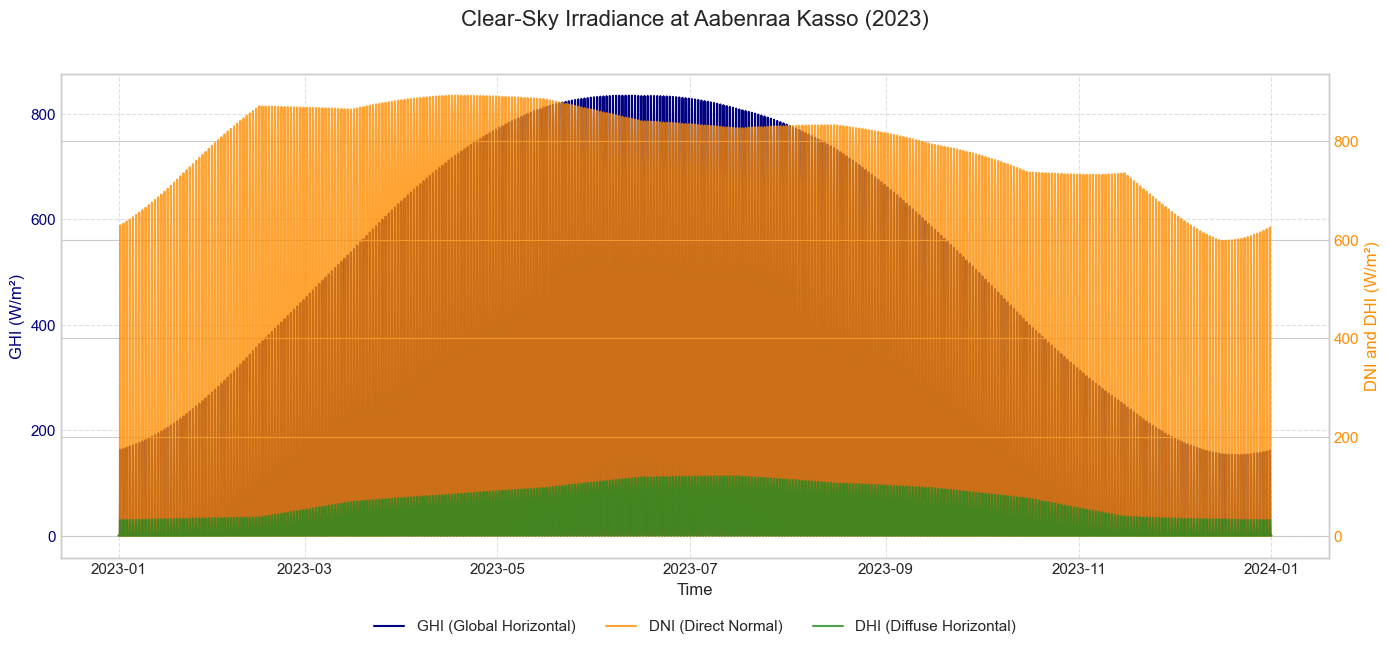

Plotting Total Solar Farm AC Power...


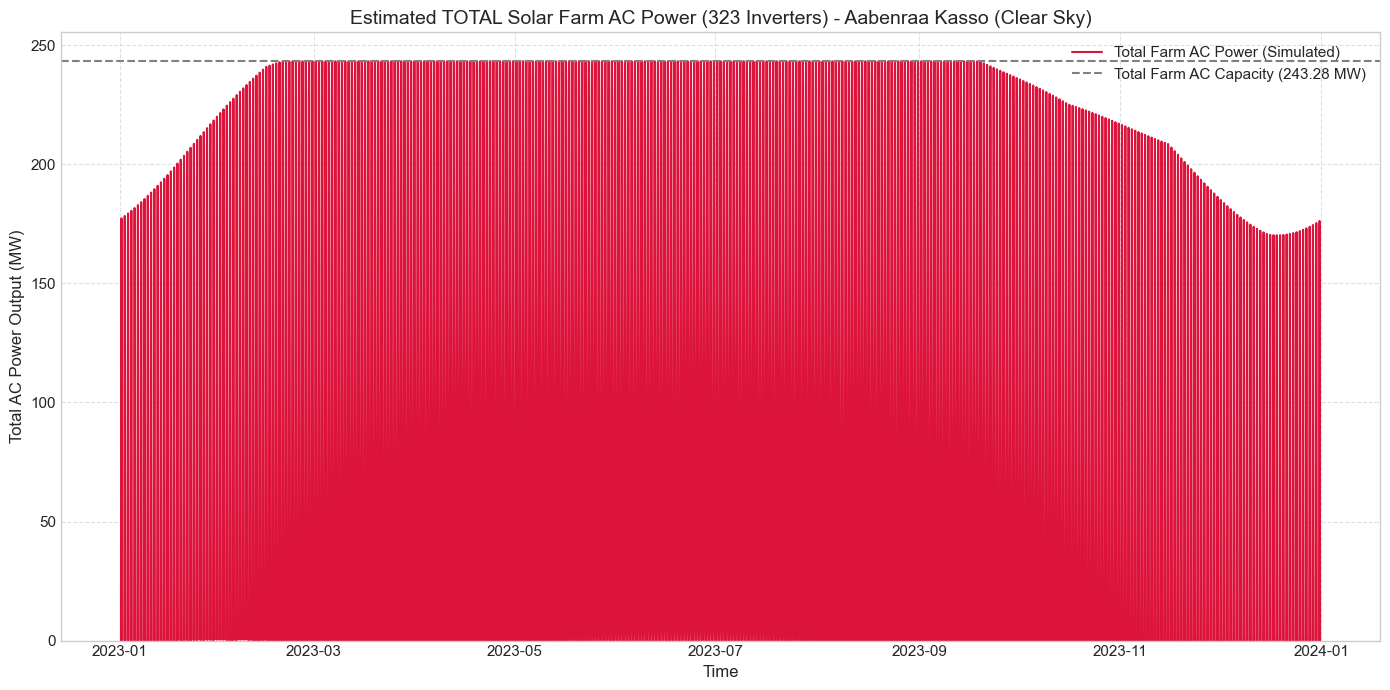

Plotting Wind Turbine Power Curve...


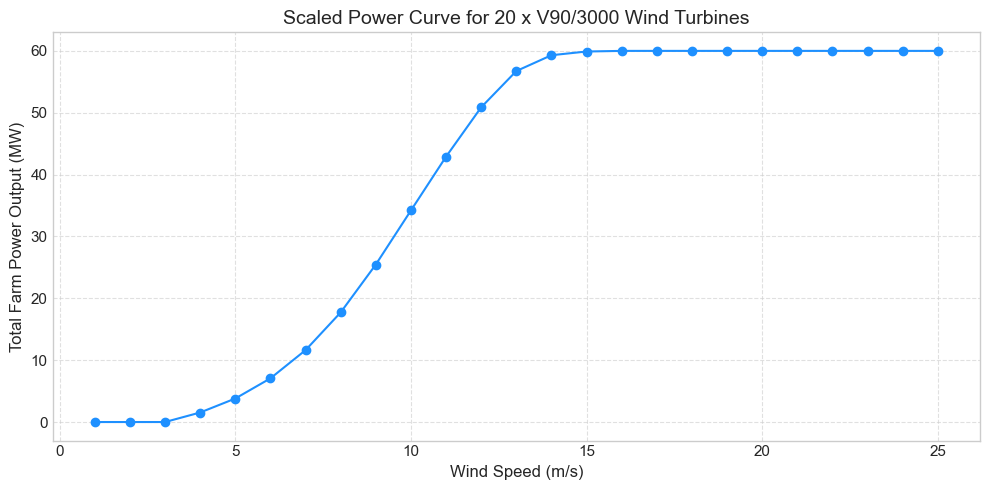

Plotting Wind Farm Power Output Time Series...


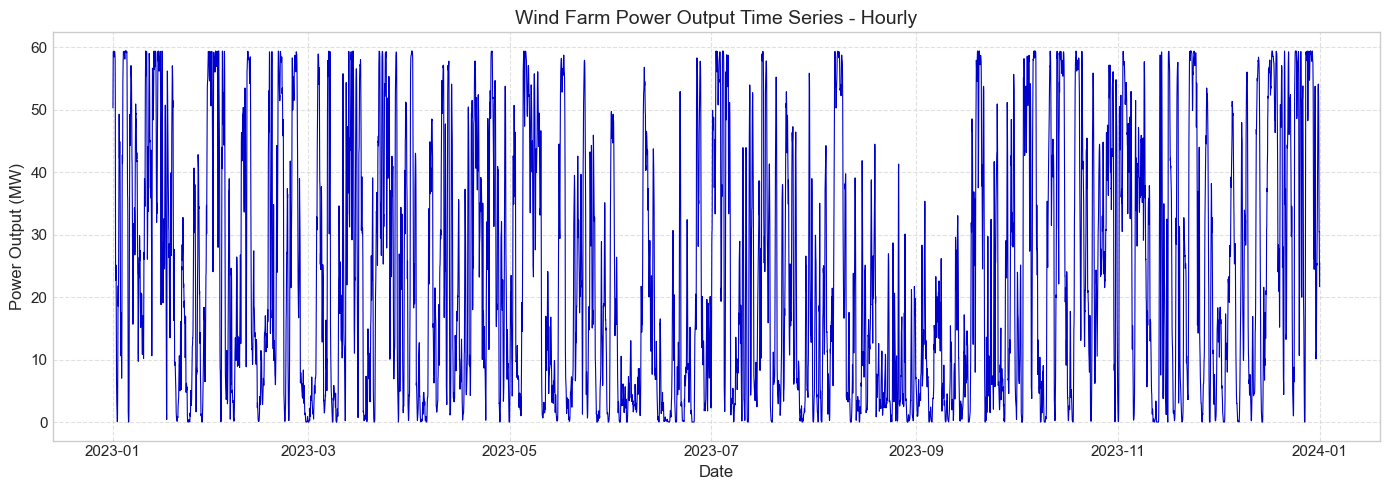

Plotting Daily Wind Power Summary...


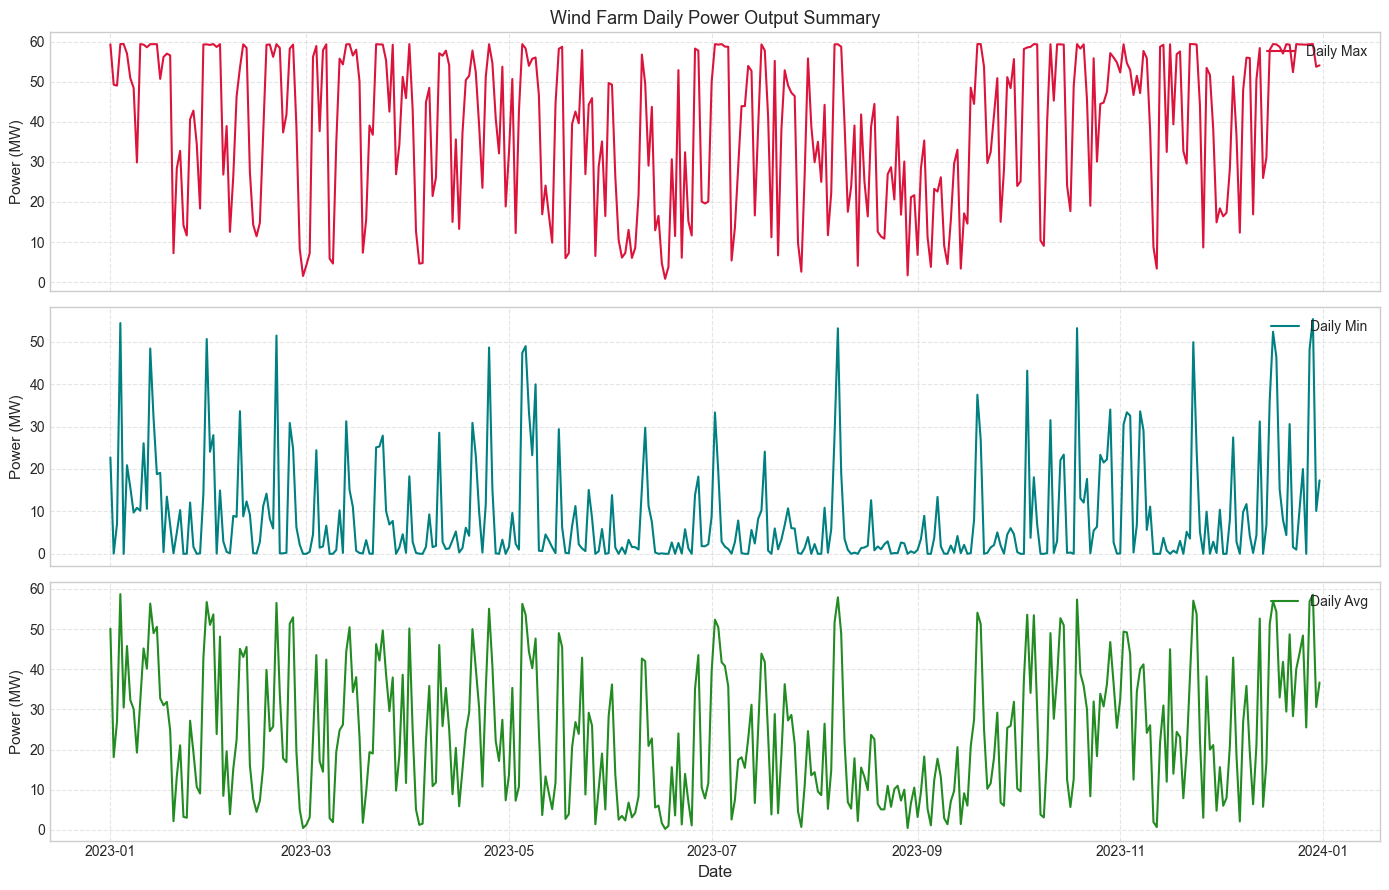

Plotting Weekly Wind Power Summary...


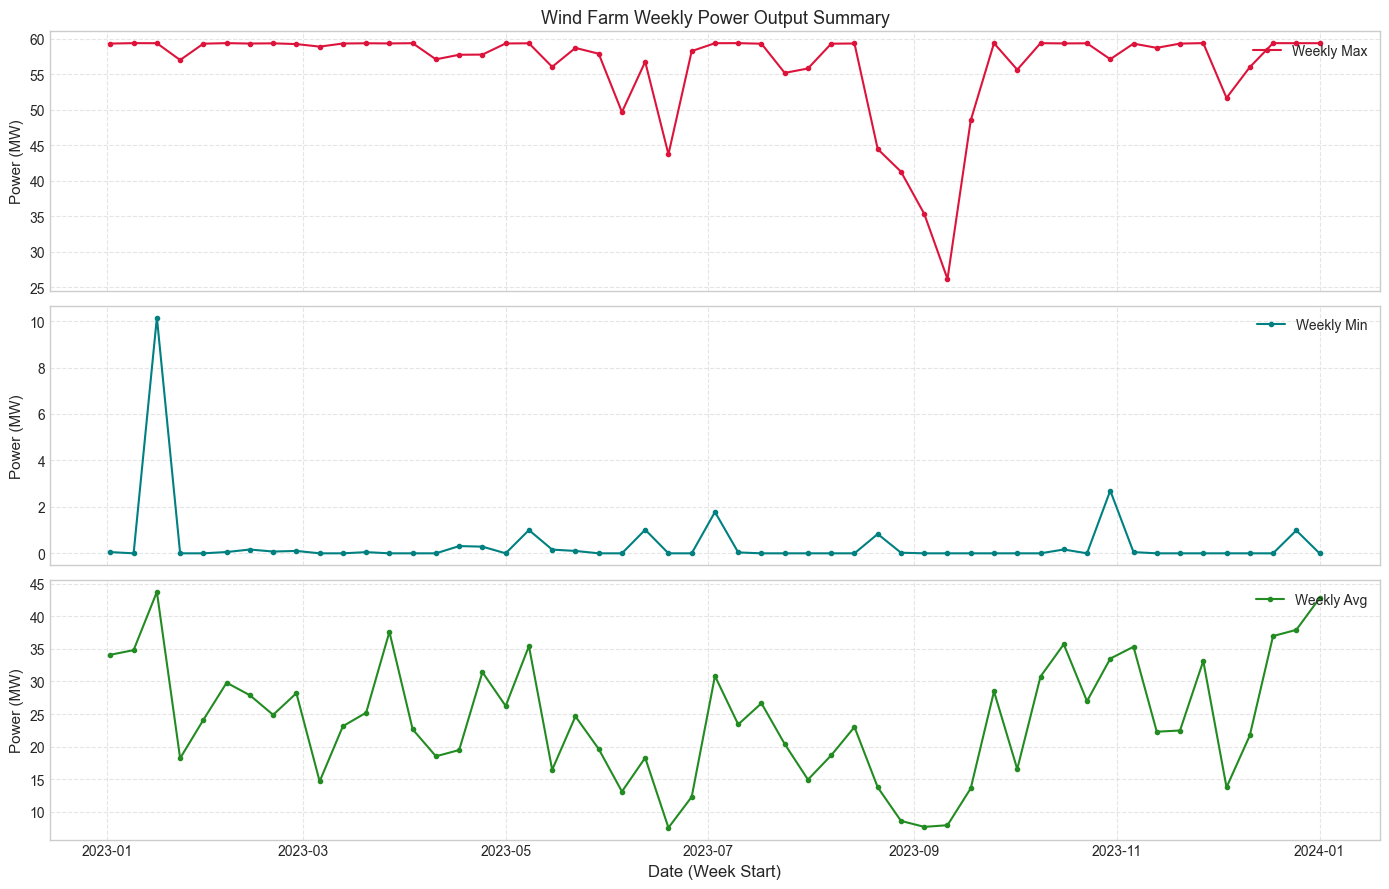

Plotting Monthly Wind Power Summary...


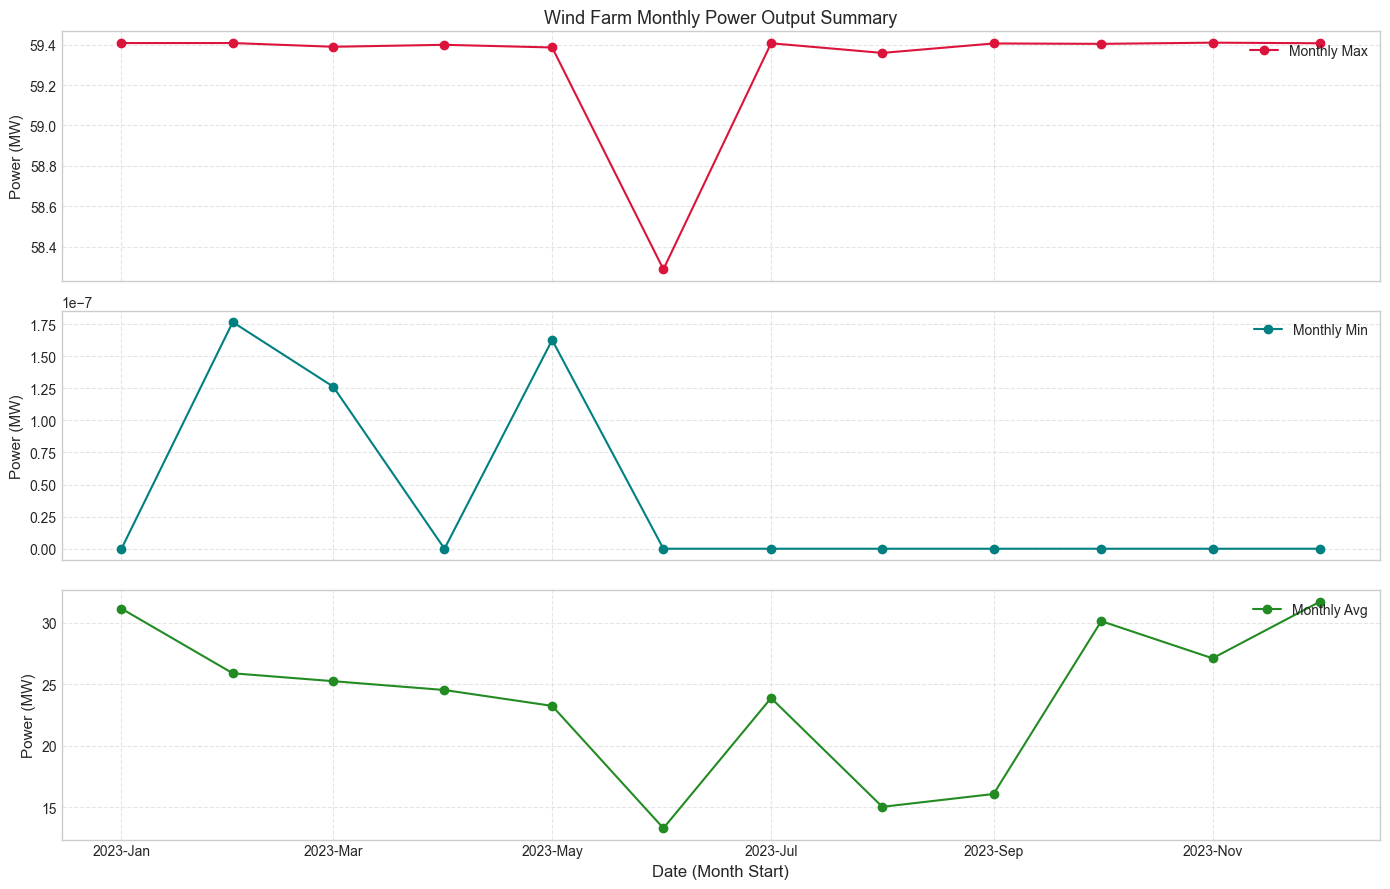

Plotting Monthly Wind Power Distribution...


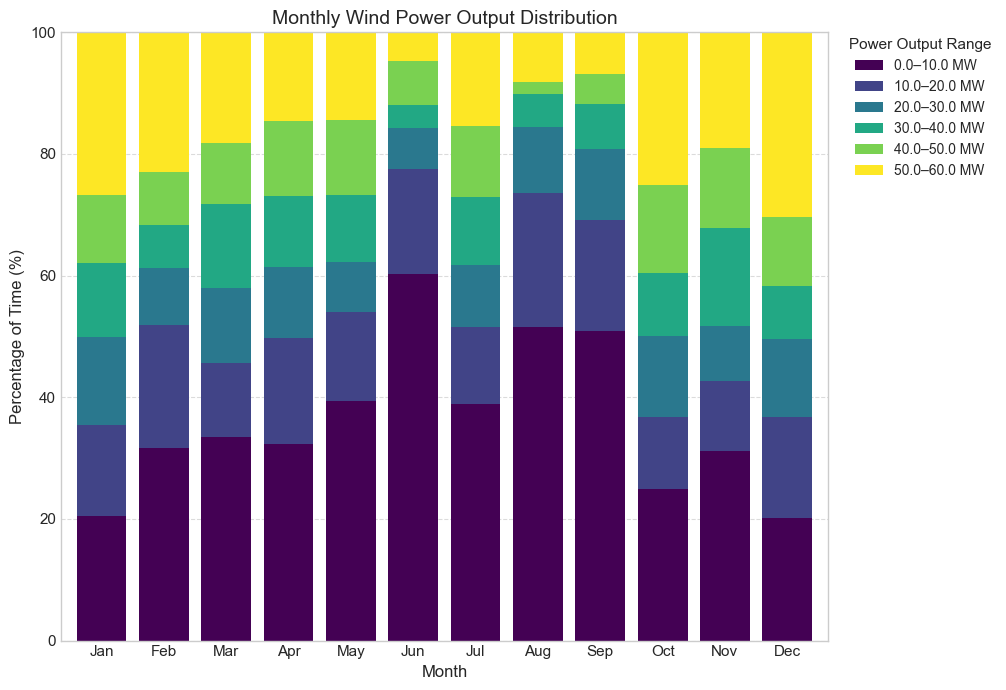

Plotting Weibull Wind Speed Distribution...


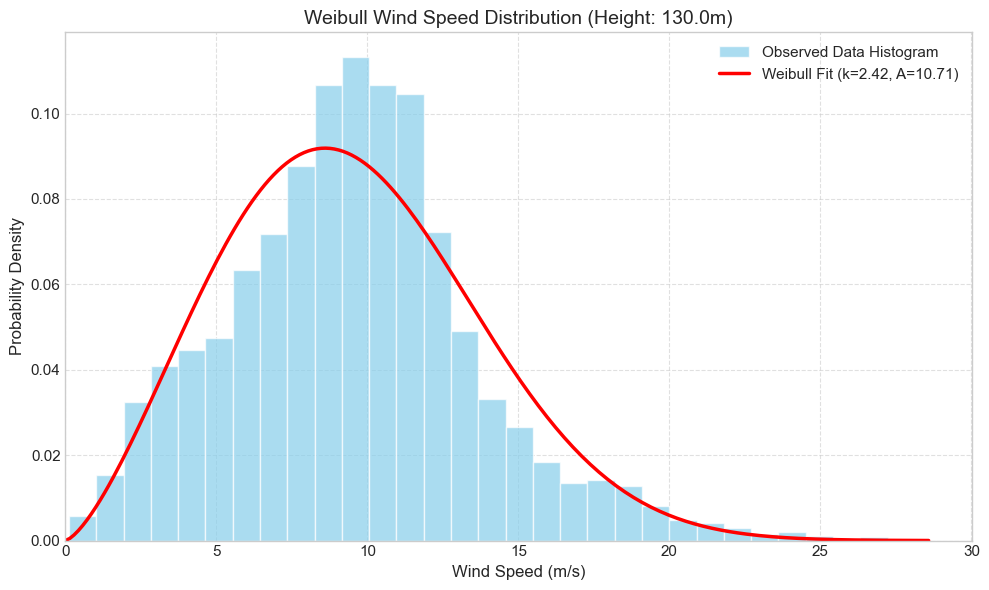

Plotting Wind Rose...


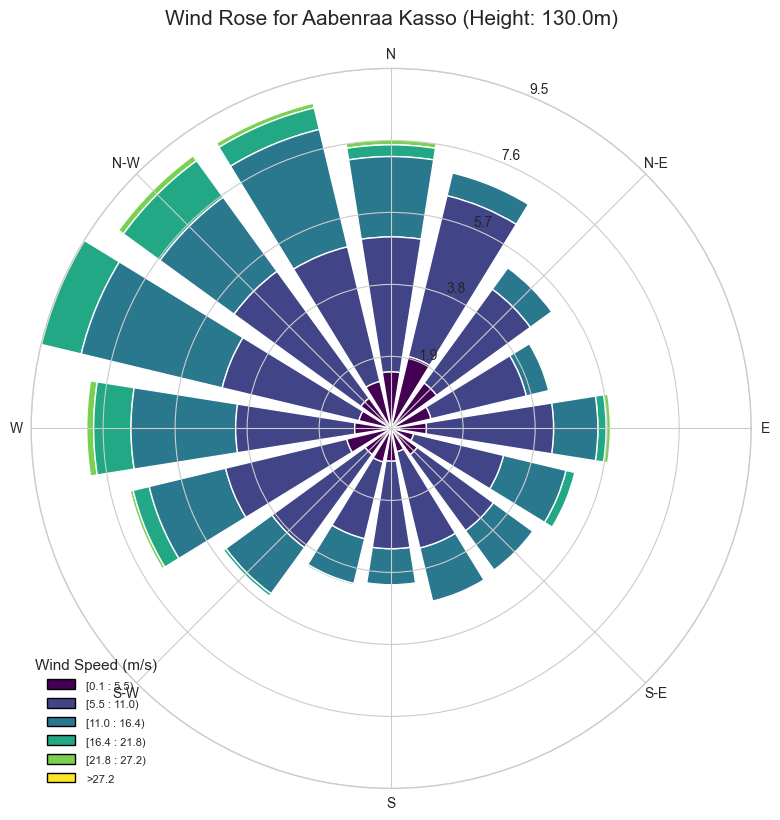

Plotting Seasonal Variation (Solar vs Wind)...


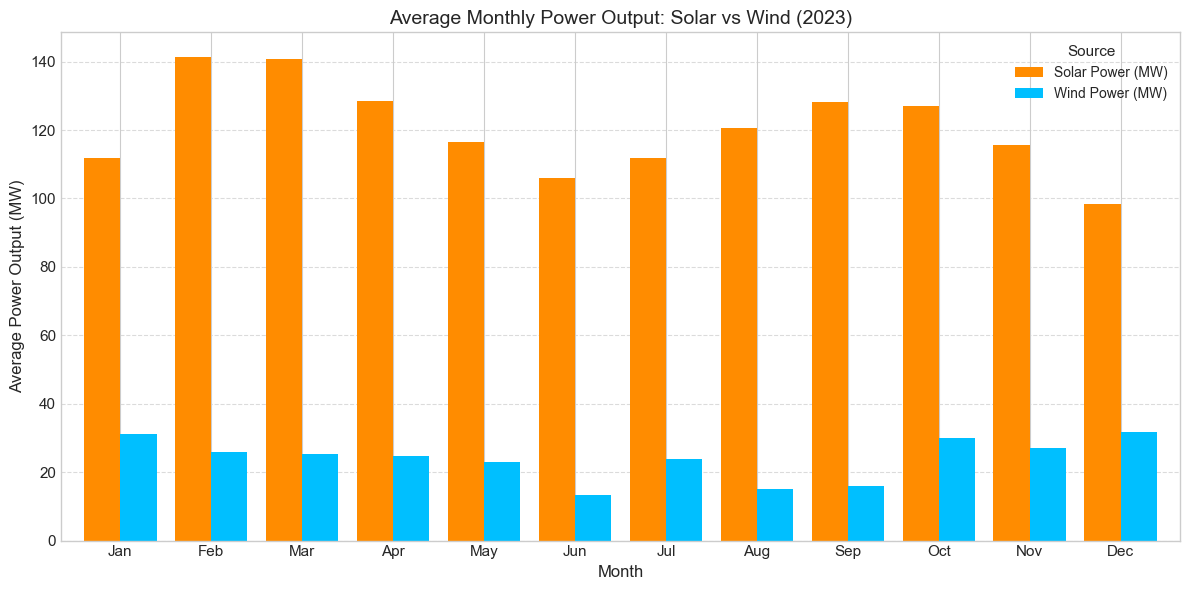

Plotting Energy Balance Results...


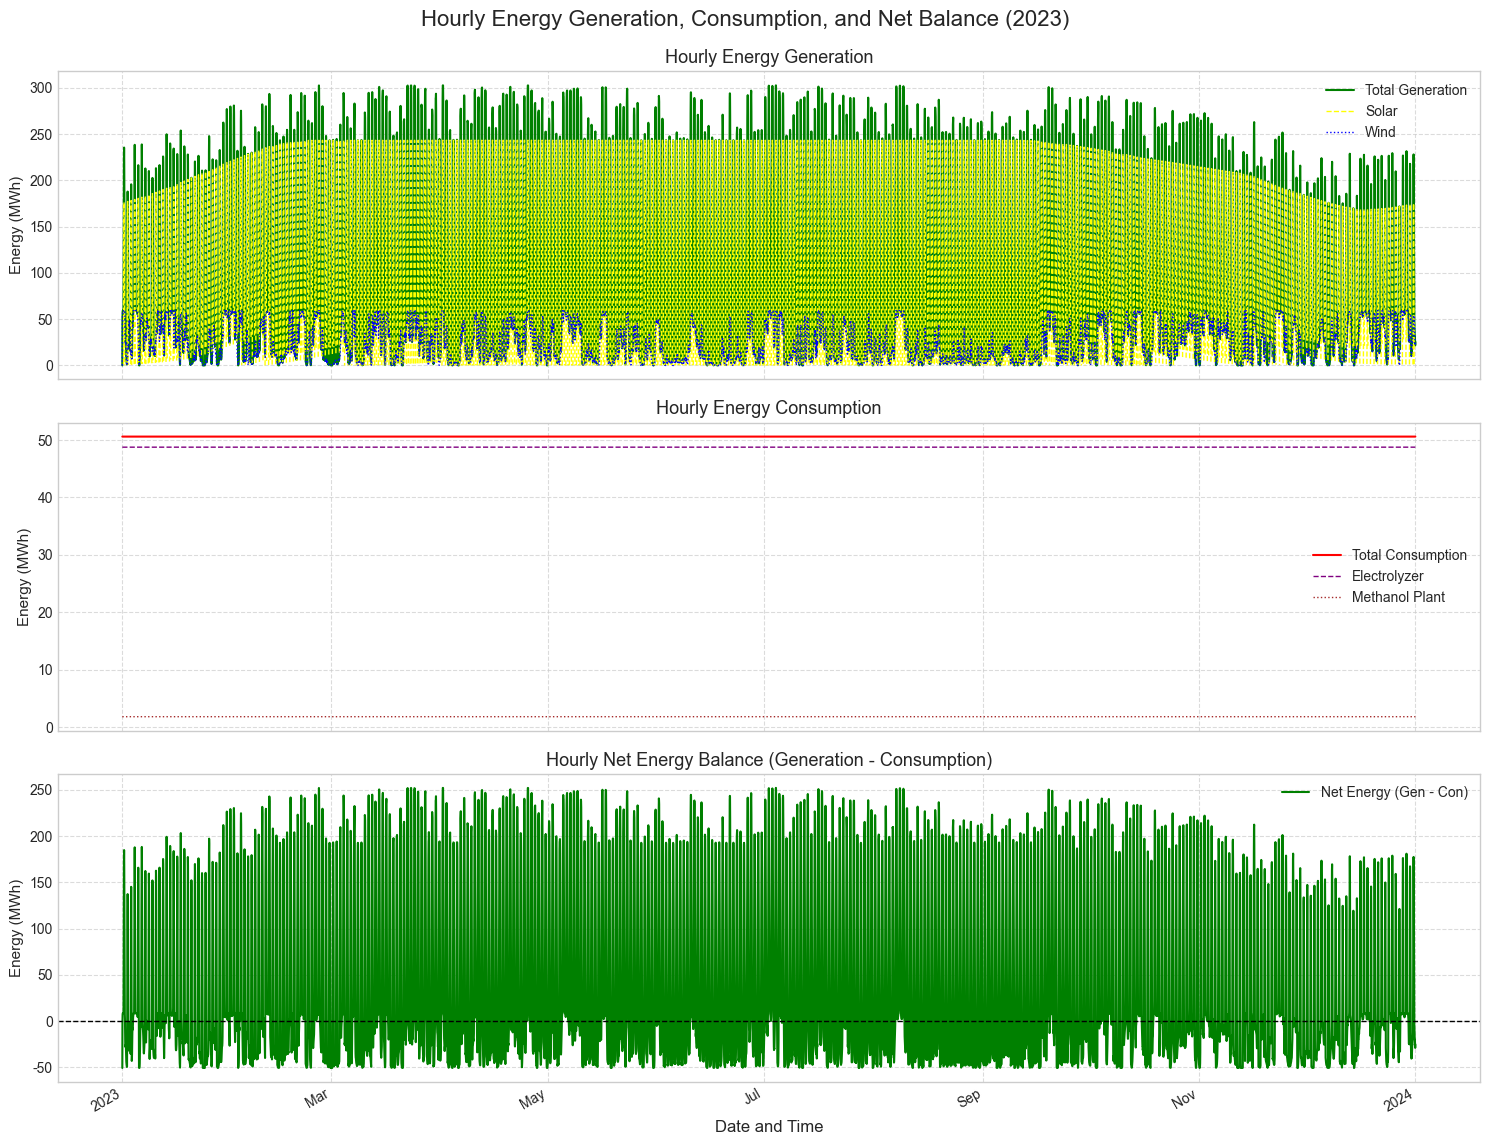

Plotting Hourly Stacked Generation vs Consumption (may be slow/cluttered)...


C:\Users\Veloy\AppData\Local\Temp\ipykernel_6268\1583255279.py:484: UserWarning: Creating legend with loc="best" can be slow with large amounts of data.
  plt.tight_layout()
C:\Users\Veloy\AppData\Roaming\Python\Python312\site-packages\IPython\core\pylabtools.py:170: UserWarning: Creating legend with loc="best" can be slow with large amounts of data.
  fig.canvas.print_figure(bytes_io, **kw)


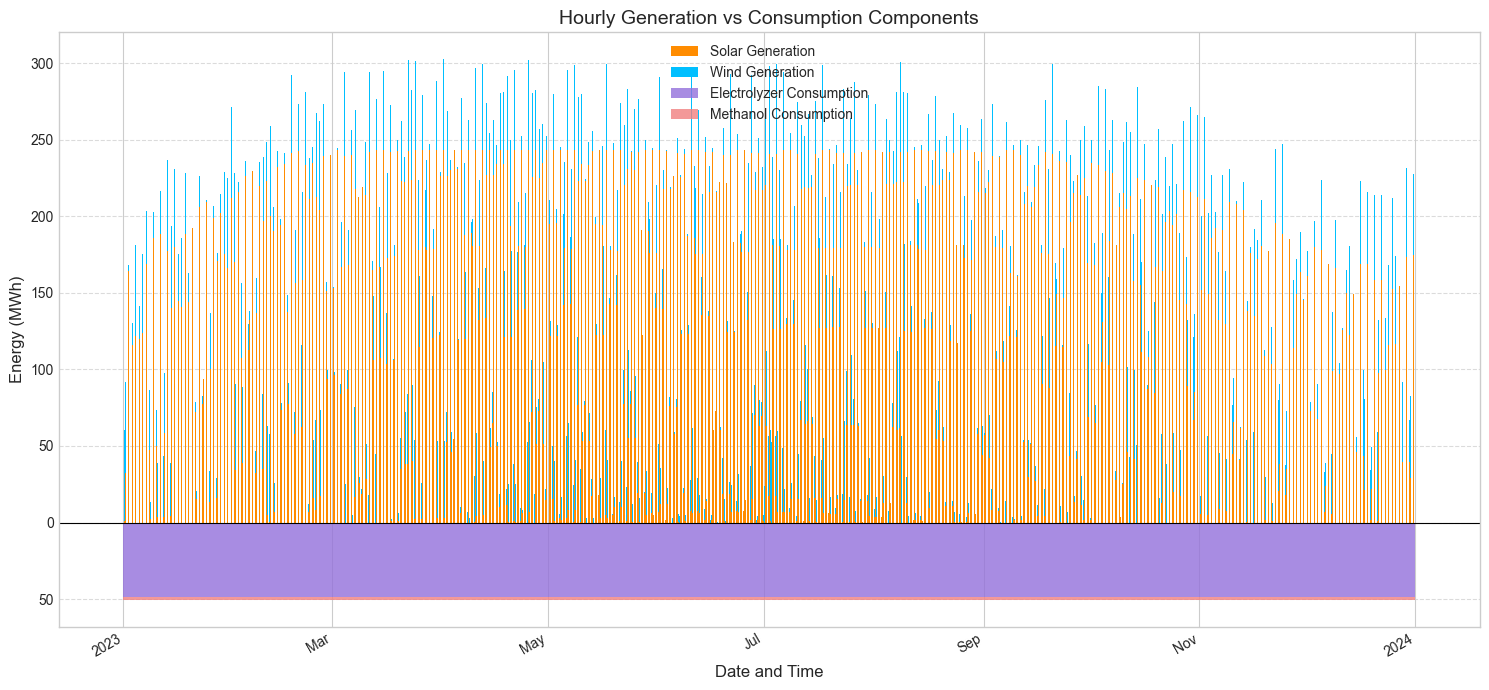

Plotting Hourly Net Energy / Grid Interaction...


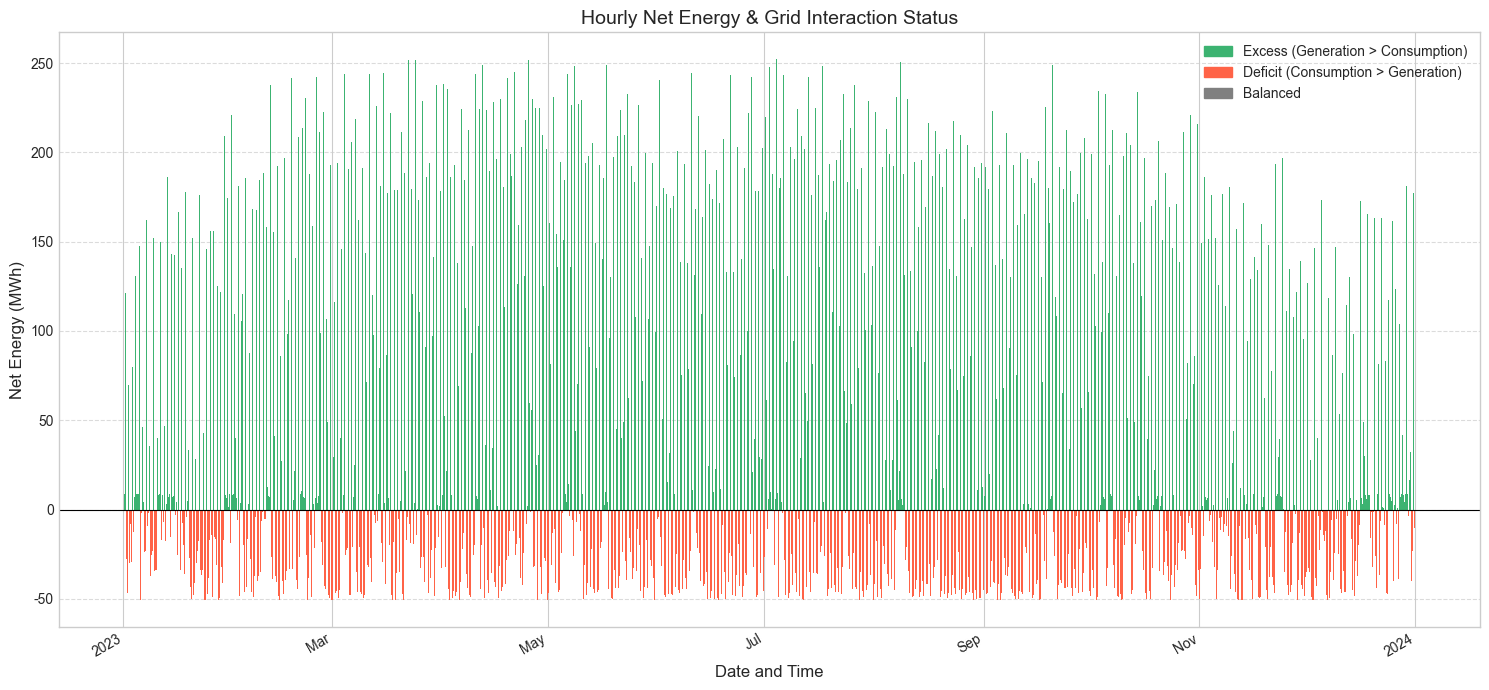

Plotting Aggregated Energy Balance (Daily/Weekly/Monthly)...


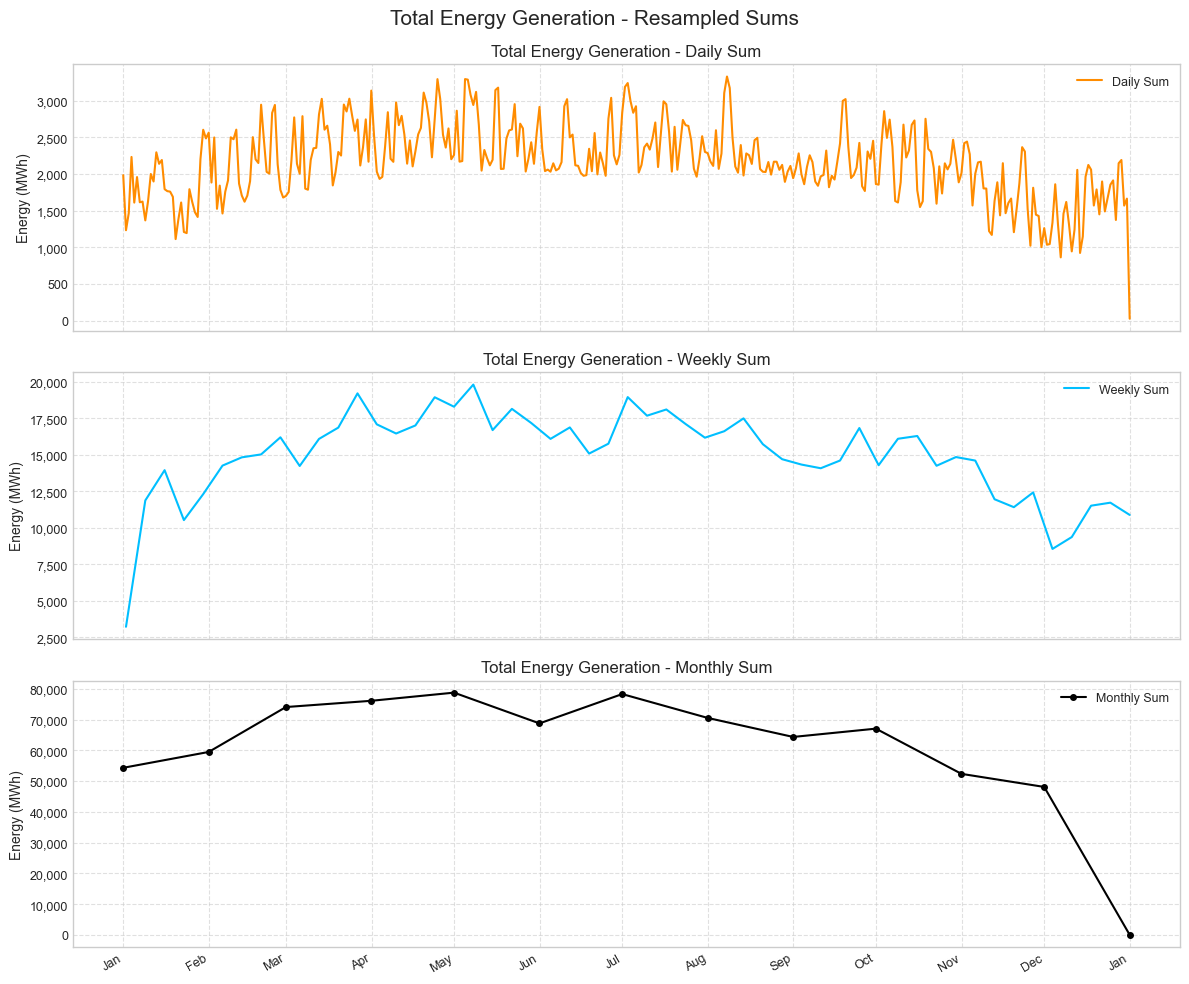

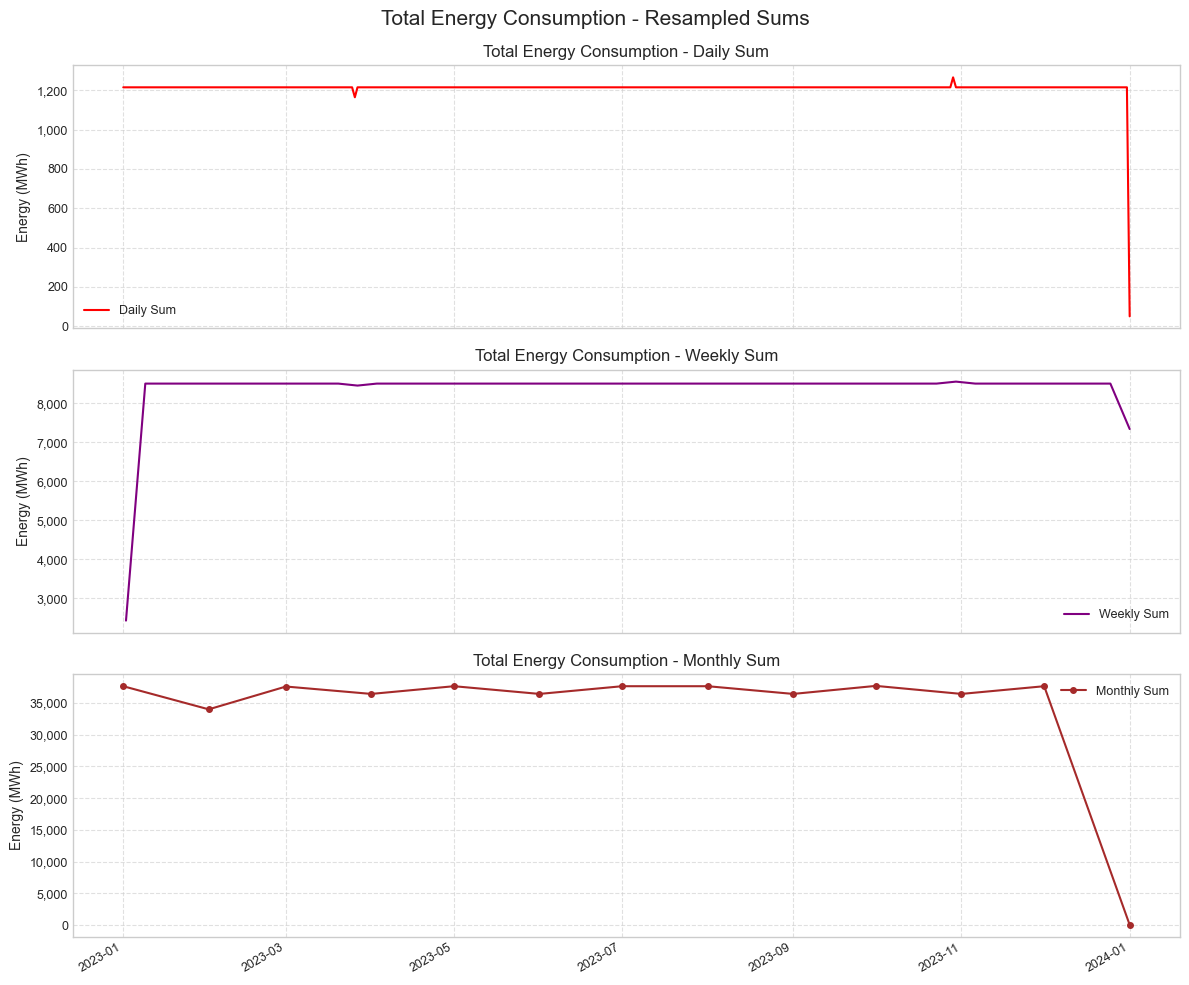

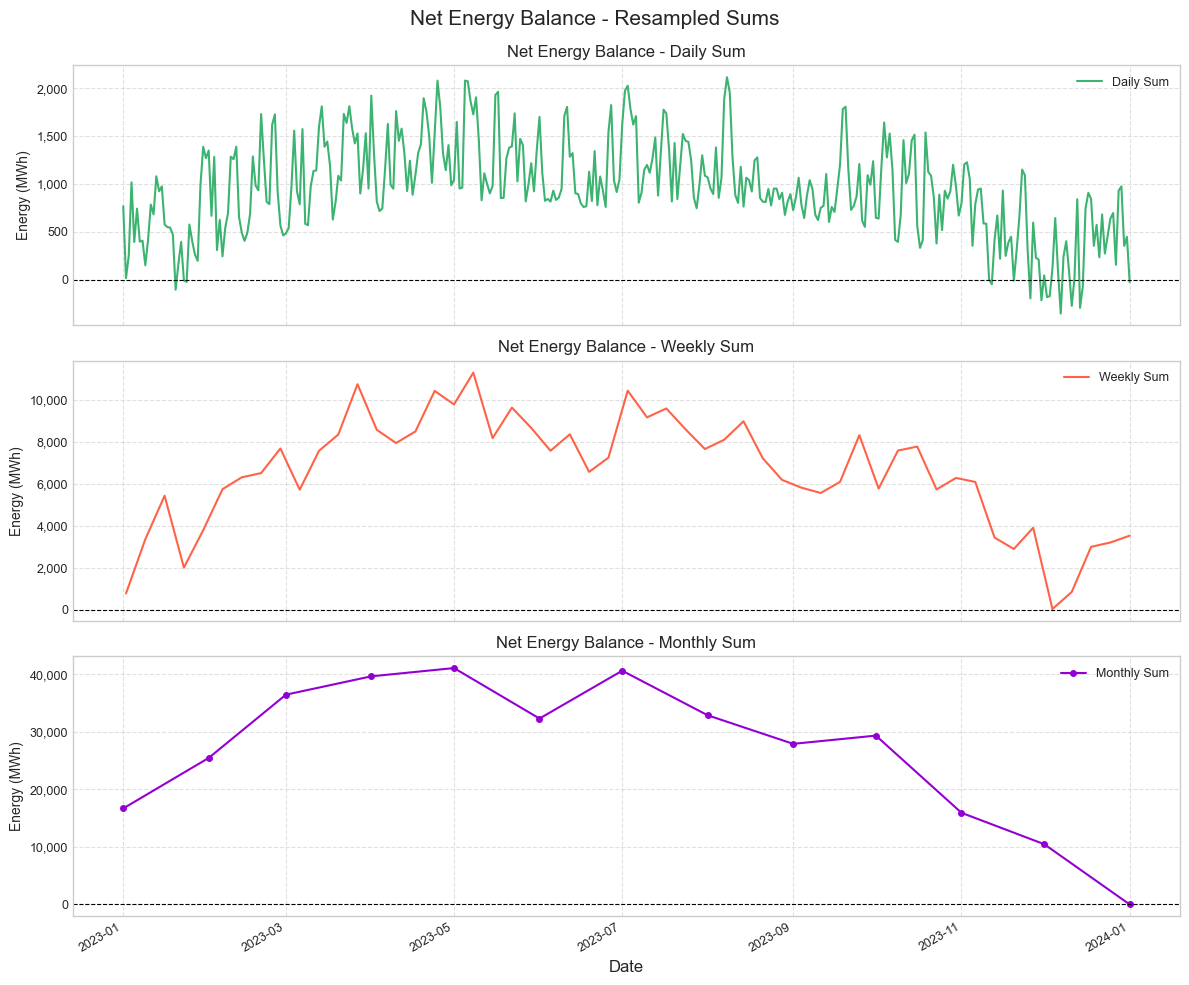


Plotting chunk complete.


In [7]:
# %% Chunk 6: Plotting and Visualization

# Import plotting libraries if not already imported
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import matplotlib.ticker as mticker
import matplotlib.patches as mpatches
import numpy as np
import pandas as pd
import calendar
from windrose import WindroseAxes # For wind rose plot
from scipy.stats import weibull_min # For Weibull plot

# Assume the following variables are available from previous chunks:
# clear_sky: DataFrame with clear sky irradiance (ghi, dni, dhi)
# location: pvlib Location object
# total_ac_power_mw: Series with total farm AC power (MW)
# num_inverters: Integer, number of inverters
# INVERTER_AC_LIMIT_MW: Float, AC limit per inverter
# resulting_total_farm_ac_capacity_mw: Float, total nominal AC capacity of the farm
# W_Turbine: windpowerlib WindTurbine object (if WIND_NUM_TURBINES > 0)
# WIND_NUM_TURBINES: Integer, number of wind turbines
# Farm_Power_Output_MW: DataFrame with wind farm hourly power output
# Weather_Data: DataFrame with processed weather data (MultiIndex columns)
# WIND_TARGET_HEIGHT: Float, hub height
# SOLAR_LOCATION_NAME: String, location name
# hourly_solar_power_mw: Series with hourly solar power (MW)
# SOLAR_SIMULATION_START: String, simulation start date
# results_df_hourly: DataFrame with hourly energy balance results
# total_generation_mwh_hourly: Series, total hourly generation
# total_consumption_mwh_hourly: Series, total hourly consumption
# net_energy_mwh_hourly: Series, net hourly energy

print("\nGenerating plots...")

# Set a general style for plots (optional)
plt.style.use('seaborn-v0_8-whitegrid') # Example style

# --- Plot Clear-Sky Irradiance (Solar) ---
if 'clear_sky' in locals() and not clear_sky.empty:
    print("Plotting Clear-Sky Irradiance...")
    fig_irrad, ax1_irrad = plt.subplots(figsize=(14, 7)) # Adjusted size
    ax1_irrad.plot(clear_sky.index, clear_sky['ghi'], color='navy', linewidth=1.5, label='GHI (Global Horizontal)')
    ax1_irrad.set_ylabel('GHI (W/m²)', color='navy', fontsize=12)
    ax1_irrad.tick_params(axis='y', labelcolor='navy', labelsize=11)
    ax1_irrad.set_xlabel('Time', fontsize=12)
    ax1_irrad.tick_params(axis='x', labelsize=11)

    # Create a second y-axis for DNI and DHI
    ax2_irrad = ax1_irrad.twinx()
    ax2_irrad.plot(clear_sky.index, clear_sky['dni'], color='darkorange', alpha=0.8, linewidth=1.5, label='DNI (Direct Normal)')
    ax2_irrad.plot(clear_sky.index, clear_sky['dhi'], color='forestgreen', alpha=0.8, linewidth=1.5, label='DHI (Diffuse Horizontal)')
    ax2_irrad.set_ylabel('DNI and DHI (W/m²)', color='darkorange', fontsize=12)
    ax2_irrad.tick_params(axis='y', labelcolor='darkorange', labelsize=11)

    # Add title and combined legend
    sim_year_solar = pd.to_datetime(SOLAR_SIMULATION_START).year if 'SOLAR_SIMULATION_START' in locals() else 'Year'
    loc_name_solar = location.name if 'location' in locals() else 'Location'
    fig_irrad.suptitle(f"Clear-Sky Irradiance at {loc_name_solar} ({sim_year_solar})", fontsize=16)
    # Combine legends from both axes
    lines1, labels1 = ax1_irrad.get_legend_handles_labels()
    lines2, labels2 = ax2_irrad.get_legend_handles_labels()
    ax2_irrad.legend(lines1 + lines2, labels1 + labels2, loc='upper center', bbox_to_anchor=(0.5, -0.1), ncol=3, fontsize=11) # Legend below plot

    # Improve grid and layout
    ax1_irrad.grid(True, linestyle='--', alpha=0.6)
    plt.tight_layout(rect=[0, 0.05, 1, 0.96]) # Adjust layout to accommodate legend
    plt.show()
else:
    print("Skipping Clear-Sky Irradiance plot: 'clear_sky' data not available.")


# --- Plot Total Farm AC Power (Solar) ---
if 'total_ac_power_mw' in locals() and not total_ac_power_mw.empty:
    print("Plotting Total Solar Farm AC Power...")
    plt.figure(figsize=(14, 7))
    # Ensure index is datetime for plotting
    plot_index_solar_ac = pd.to_datetime(total_ac_power_mw.index)
    plt.plot(plot_index_solar_ac, total_ac_power_mw, color='crimson', linewidth=1.5, label='Total Farm AC Power (Simulated)')

    # Add horizontal line for the farm's nominal AC capacity
    if 'resulting_total_farm_ac_capacity_mw' in locals():
        plt.axhline(y=resulting_total_farm_ac_capacity_mw, color='gray', linestyle='--', label=f'Total Farm AC Capacity ({resulting_total_farm_ac_capacity_mw:.2f} MW)')

    # Add titles and labels
    loc_name_solar = location.name if 'location' in locals() else 'Location'
    num_inv_str = f"{num_inverters} Inverters" if 'num_inverters' in locals() else "Multiple Inverters"
    plt.title(f"Estimated TOTAL Solar Farm AC Power ({num_inv_str}) - {loc_name_solar} (Clear Sky)", fontsize=14)
    plt.xlabel("Time", fontsize=12)
    plt.ylabel("Total AC Power Output (MW)", fontsize=12)
    plt.ylim(bottom=0) # Ensure y-axis starts at 0
    plt.legend(fontsize=11)
    plt.grid(True, linestyle='--', alpha=0.6)
    plt.xticks(fontsize=11)
    plt.yticks(fontsize=11)
    plt.tight_layout()
    plt.show()
else:
    print("Skipping Total Solar Farm AC Power plot: 'total_ac_power_mw' data not available.")


# --- Wind Turbine Power Curve Plot ---
# Check if simulation ran and turbine object exists
if 'WIND_NUM_TURBINES' in locals() and WIND_NUM_TURBINES > 0 and 'W_Turbine' in locals() and hasattr(W_Turbine, 'power_curve') and W_Turbine.power_curve is not None:
    print("Plotting Wind Turbine Power Curve...")
    plt.figure(figsize=(10, 5))
    # Extract wind speeds and power values from the turbine's power curve attribute
    wind_speeds = W_Turbine.power_curve['wind_speed']
    power_values_W = W_Turbine.power_curve['value'] # Power is usually in Watts
    # Convert power to Megawatts
    power_values_MW = power_values_W / 1e6
    # Scale power curve to total number of turbines for visualization
    power_values_MW_total_turbines = power_values_MW * WIND_NUM_TURBINES

    plt.plot(wind_speeds, power_values_MW_total_turbines, marker='o', linestyle='-', color='dodgerblue')
    plt.xlabel('Wind Speed (m/s)', fontsize=12)
    plt.ylabel('Total Farm Power Output (MW)', fontsize=12) # Updated label
    plt.title(f'Scaled Power Curve for {WIND_NUM_TURBINES} x {W_Turbine.turbine_type} Wind Turbines', fontsize=14) # Updated title
    plt.grid(True, linestyle='--', alpha=0.6)
    plt.xticks(fontsize=11)
    plt.yticks(fontsize=11)
    plt.tight_layout()
    plt.show()
else:
     print("Skipping Wind Turbine Power Curve plot: Wind simulation data or turbine object not available.")


# --- Wind Farm Power Output Time Series Plot ---
if 'Farm_Power_Output_MW' in locals() and not Farm_Power_Output_MW.empty:
    print("Plotting Wind Farm Power Output Time Series...")
    plt.figure(figsize=(14, 5)) # Wider figure
    # Ensure index is datetime for plotting
    plot_index_wind = pd.to_datetime(Farm_Power_Output_MW.index)
    plt.plot(plot_index_wind, Farm_Power_Output_MW['Power Output (MW)'], color='mediumblue', linewidth=0.8)
    plt.xlabel('Date', fontsize=12)
    plt.ylabel('Power Output (MW)', fontsize=12)
    plt.title('Wind Farm Power Output Time Series - Hourly', fontsize=14)
    plt.grid(True, linestyle='--', alpha=0.6)
    plt.xticks(fontsize=11)
    plt.yticks(fontsize=11)
    plt.tight_layout()
    plt.show()

    # --- Daily Wind Summary Plot ---
    print("Plotting Daily Wind Power Summary...")
    # Ensure index is datetime before resampling
    if not isinstance(Farm_Power_Output_MW.index, pd.DatetimeIndex):
        Farm_Power_Output_MW.index = pd.to_datetime(Farm_Power_Output_MW.index)
    daily_max = Farm_Power_Output_MW['Power Output (MW)'].resample('D').max()
    daily_min = Farm_Power_Output_MW['Power Output (MW)'].resample('D').min()
    daily_avg = Farm_Power_Output_MW['Power Output (MW)'].resample('D').mean()
    fig_daily, axs_daily = plt.subplots(3, 1, figsize=(14, 9), sharex=True) # Wider figure
    axs_daily[0].plot(daily_max.index, daily_max, color='crimson', label='Daily Max')
    axs_daily[0].set_ylabel('Power (MW)', fontsize=11)
    axs_daily[0].set_title('Wind Farm Daily Power Output Summary', fontsize=13)
    axs_daily[0].grid(True, alpha=0.5, linestyle='--'); axs_daily[0].legend(loc='upper right', fontsize=10)
    axs_daily[0].tick_params(axis='y', labelsize=10)
    axs_daily[1].plot(daily_min.index, daily_min, color='teal', label='Daily Min')
    axs_daily[1].set_ylabel('Power (MW)', fontsize=11); axs_daily[1].grid(True, alpha=0.5, linestyle='--'); axs_daily[1].legend(loc='upper right', fontsize=10)
    axs_daily[1].tick_params(axis='y', labelsize=10)
    axs_daily[2].plot(daily_avg.index, daily_avg, color='forestgreen', label='Daily Avg') # Changed color
    axs_daily[2].set_ylabel('Power (MW)', fontsize=11); axs_daily[2].set_xlabel('Date', fontsize=12); axs_daily[2].grid(True, alpha=0.5, linestyle='--'); axs_daily[2].legend(loc='upper right', fontsize=10)
    axs_daily[2].tick_params(axis='both', labelsize=10)
    plt.tight_layout(); plt.show()

    # --- Weekly Wind Summary Plot ---
    print("Plotting Weekly Wind Power Summary...")
    weekly_max = Farm_Power_Output_MW['Power Output (MW)'].resample('W-MON').max() # Weekly starting Monday
    weekly_min = Farm_Power_Output_MW['Power Output (MW)'].resample('W-MON').min()
    weekly_avg = Farm_Power_Output_MW['Power Output (MW)'].resample('W-MON').mean()
    fig_weekly, axs_weekly = plt.subplots(3, 1, figsize=(14, 9), sharex=True) # Wider figure
    axs_weekly[0].plot(weekly_max.index, weekly_max, color='crimson', label='Weekly Max', marker='.', linestyle='-')
    axs_weekly[0].set_ylabel('Power (MW)', fontsize=11)
    axs_weekly[0].set_title('Wind Farm Weekly Power Output Summary', fontsize=13)
    axs_weekly[0].grid(True, alpha=0.5, linestyle='--'); axs_weekly[0].legend(loc='upper right', fontsize=10)
    axs_weekly[0].tick_params(axis='y', labelsize=10)
    axs_weekly[1].plot(weekly_min.index, weekly_min, color='teal', label='Weekly Min', marker='.', linestyle='-')
    axs_weekly[1].set_ylabel('Power (MW)', fontsize=11); axs_weekly[1].grid(True, alpha=0.5, linestyle='--'); axs_weekly[1].legend(loc='upper right', fontsize=10)
    axs_weekly[1].tick_params(axis='y', labelsize=10)
    axs_weekly[2].plot(weekly_avg.index, weekly_avg, color='forestgreen', label='Weekly Avg', marker='.', linestyle='-') # Changed color
    axs_weekly[2].set_ylabel('Power (MW)', fontsize=11); axs_weekly[2].set_xlabel('Date (Week Start)', fontsize=12); axs_weekly[2].grid(True, alpha=0.5, linestyle='--'); axs_weekly[2].legend(loc='upper right', fontsize=10)
    axs_weekly[2].tick_params(axis='both', labelsize=10)
    plt.tight_layout(); plt.show()

    # --- Monthly Wind Summary Plot ---
    print("Plotting Monthly Wind Power Summary...")
    monthly_max = Farm_Power_Output_MW['Power Output (MW)'].resample('MS').max() # Monthly start
    monthly_min = Farm_Power_Output_MW['Power Output (MW)'].resample('MS').min()
    monthly_avg = Farm_Power_Output_MW['Power Output (MW)'].resample('MS').mean()
    fig_monthly, axs_monthly = plt.subplots(3, 1, figsize=(14, 9), sharex=True) # Wider figure
    axs_monthly[0].plot(monthly_max.index, monthly_max, color='crimson', label='Monthly Max', marker='o', linestyle='-')
    axs_monthly[0].set_ylabel('Power (MW)', fontsize=11)
    axs_monthly[0].set_title('Wind Farm Monthly Power Output Summary', fontsize=13)
    axs_monthly[0].grid(True, alpha=0.5, linestyle='--'); axs_monthly[0].legend(loc='upper right', fontsize=10)
    axs_monthly[0].tick_params(axis='y', labelsize=10)
    axs_monthly[1].plot(monthly_min.index, monthly_min, color='teal', label='Monthly Min', marker='o', linestyle='-')
    axs_monthly[1].set_ylabel('Power (MW)', fontsize=11); axs_monthly[1].grid(True, alpha=0.5, linestyle='--'); axs_monthly[1].legend(loc='upper right', fontsize=10)
    axs_monthly[1].tick_params(axis='y', labelsize=10)
    axs_monthly[2].plot(monthly_avg.index, monthly_avg, color='forestgreen', label='Monthly Avg', marker='o', linestyle='-') # Changed color
    axs_monthly[2].set_ylabel('Power (MW)', fontsize=11); axs_monthly[2].set_xlabel('Date (Month Start)', fontsize=12); axs_monthly[2].grid(True, alpha=0.5, linestyle='--'); axs_monthly[2].legend(loc='upper right', fontsize=10)
    axs_monthly[2].tick_params(axis='both', labelsize=10)
    # Format x-axis for months
    axs_monthly[2].xaxis.set_major_formatter(mdates.DateFormatter('%Y-%b'))
    plt.tight_layout(); plt.show()

    # --- Monthly Wind Power Output Distribution Plot ---
    print("Plotting Monthly Wind Power Distribution...")
    # Define bins dynamically based on max power, or use fixed bins if preferred
    max_power_output = Farm_Power_Output_MW['Power Output (MW)'].max()
    if pd.isna(max_power_output) or max_power_output <= 0:
        print("Max wind power output is zero or invalid, skipping distribution plot.")
    else:
        num_bins = 6 # Example number of bins
        # Create bins up to slightly above max power
        bins = np.linspace(0, max_power_output * 1.01, num_bins + 1) # Add small margin
        # Create labels dynamically
        labels = [f'{bins[i]:.1f}–{bins[i+1]:.1f} MW' for i in range(num_bins)]
        # Adjust last label slightly if needed, e.g., '> X MW'
        # labels[-1] = f'> {bins[-2]:.1f} MW'

        colors = plt.cm.viridis(np.linspace(0, 1, num_bins)) # Use a colormap

        temp_df = Farm_Power_Output_MW.copy()
        # Ensure index is datetime before extracting month
        if not isinstance(temp_df.index, pd.DatetimeIndex):
            temp_df.index = pd.to_datetime(temp_df.index)
        temp_df['Month'] = temp_df.index.month
        # Use the dynamically created bins and labels
        temp_df['Power Range'] = pd.cut(temp_df['Power Output (MW)'],
                                        bins=bins, labels=labels, right=False, include_lowest=True)

        # Group by month and power range, ensure all months are present
        monthly_distribution = temp_df.groupby(['Month', 'Power Range'], observed=False).size().unstack(fill_value=0)
        monthly_distribution = monthly_distribution.reindex(range(1, 13), fill_value=0) # Ensure all 12 months
        monthly_distribution = monthly_distribution.reindex(columns=labels, fill_value=0) # Ensure all labels

        total_hours_per_month = monthly_distribution.sum(axis=1)
        # Avoid division by zero for months with no data
        percentage_distribution = monthly_distribution.divide(total_hours_per_month.replace(0, np.nan), axis=0).fillna(0) * 100

        fig, ax = plt.subplots(figsize=(12, 7))
        percentage_distribution.plot(kind='bar', stacked=True, ax=ax, width=0.8, color=colors)

        # Add labels inside bars (optional, can be cluttered)
        # for container in ax.containers:
        #     labels_on_bar = [f'{h:.0f}%' if h > 5 else '' for h in container.datavalues] # Only show if > 5%
        #     ax.bar_label(container, labels=labels_on_bar, label_type='center', fontsize=8, color='white', weight='bold')

        ax.set_xlabel('Month', fontsize=12)
        ax.set_ylabel('Percentage of Time (%)', fontsize=12)
        ax.set_title('Monthly Wind Power Output Distribution', fontsize=14)
        month_names = [calendar.month_abbr[i] for i in percentage_distribution.index]
        ax.set_xticklabels(month_names, rotation=0, fontsize=11)
        ax.legend(title='Power Output Range', bbox_to_anchor=(1.02, 1), loc='upper left', borderaxespad=0., fontsize=10, title_fontsize=11)
        ax.set_ylim(0, 100); ax.grid(axis='y', linestyle='--', alpha=0.7)
        ax.tick_params(axis='y', labelsize=11)
        plt.tight_layout(rect=[0, 0, 0.85, 1]); # Adjust layout for legend
        plt.show()

else:
    print("Skipping Wind Power Time Series and Distribution plots: 'Farm_Power_Output_MW' data not available.")


# --- Weibull Wind Speed Distribution Plot ---
if 'Weather_Data' in locals() and not Weather_Data.empty:
    print("Plotting Weibull Wind Speed Distribution...")
    # Construct the column name tuple for the target height wind speed
    wind_speed_col_name = f'wind_speed_{int(WIND_TARGET_HEIGHT)}m'
    wind_speed_col_tuple = (wind_speed_col_name, float(WIND_TARGET_HEIGHT))

    if wind_speed_col_tuple in Weather_Data.columns:
        wind_speed_data = Weather_Data[wind_speed_col_tuple].dropna()
        # Check if data is suitable for fitting (non-empty, variation, positive values)
        if not wind_speed_data.empty and wind_speed_data.nunique() > 1 and wind_speed_data.max() > 0:
            try:
                # Fit Weibull distribution (floc=0 fixes location parameter to 0)
                shape, loc, scale = weibull_min.fit(wind_speed_data, floc=0)
                x = np.linspace(0, wind_speed_data.max()*1.05, 200) # Extend range slightly
                pdf_weibull = weibull_min.pdf(x, shape, loc=0, scale=scale)

                plt.figure(figsize=(10, 6))
                # Plot histogram of observed data
                plt.hist(wind_speed_data, bins=30, density=True, alpha=0.7, color='skyblue', edgecolor='white', label='Observed Data Histogram')
                # Plot fitted Weibull PDF
                plt.plot(x, pdf_weibull, 'r-', linewidth=2.5, label=f'Weibull Fit (k={shape:.2f}, A={scale:.2f})')
                plt.title(f"Weibull Wind Speed Distribution (Height: {WIND_TARGET_HEIGHT}m)", fontsize=14)
                plt.xlabel("Wind Speed (m/s)", fontsize=12); plt.ylabel("Probability Density", fontsize=12)
                plt.grid(True, linestyle='--', alpha=0.6); plt.legend(fontsize=11)
                plt.xticks(fontsize=11); plt.yticks(fontsize=11); plt.xlim(left=0); plt.tight_layout(); plt.show()
            except Exception as e:
                print(f"Could not fit or plot Weibull distribution: {e}")
        else:
            print("Wind speed data not suitable for Weibull fitting (empty, constant, or non-positive).")
    else:
        print(f"Skipping Weibull plot: Column {wind_speed_col_tuple} not found in Weather_Data.")
else:
    print("Skipping Weibull plot: 'Weather_Data' not available.")


# --- Wind Rose Plot ---
if 'Weather_Data' in locals() and not Weather_Data.empty:
    print("Plotting Wind Rose...")
    # Construct column name tuples for wind speed and direction at target height
    wind_speed_col_rose_name = f'wind_speed_{int(WIND_TARGET_HEIGHT)}m'
    wind_direction_col_rose_name = f'wind_direction_{int(WIND_TARGET_HEIGHT)}m'
    wind_speed_col_rose_tuple = (wind_speed_col_rose_name, float(WIND_TARGET_HEIGHT))
    wind_direction_col_rose_tuple = (wind_direction_col_rose_name, float(WIND_TARGET_HEIGHT))

    if wind_speed_col_rose_tuple in Weather_Data.columns and wind_direction_col_rose_tuple in Weather_Data.columns:
        # Extract wind speed and direction data
        ws_rose = Weather_Data[wind_speed_col_rose_tuple].dropna()
        # Align wind direction data with non-NA wind speed data
        wd_rose = Weather_Data.loc[ws_rose.index, wind_direction_col_rose_tuple].dropna()
        # Align wind speed data again after dropping NA directions
        ws_rose = ws_rose.loc[wd_rose.index]

        if not ws_rose.empty and not wd_rose.empty:
            try:
                fig_wr = plt.figure(figsize=(9, 9)) # Slightly smaller
                ax_wr = WindroseAxes.from_ax(fig=fig_wr)
                # Create the wind rose plot with specified bins and colormap
                ax_wr.bar(wd_rose, ws_rose, normed=True, opening=0.8, edgecolor='white', nsector=16, cmap=plt.cm.viridis)
                ax_wr.set_legend(title='Wind Speed (m/s)', fontsize=10, title_fontsize=11)
                loc_name_wind = SOLAR_LOCATION_NAME if 'SOLAR_LOCATION_NAME' in locals() else 'Location'
                plt.title(f'Wind Rose for {loc_name_wind} (Height: {WIND_TARGET_HEIGHT}m)', y=1.05, fontsize=15) # Adjusted title position
                plt.show()
            except Exception as e:
                print(f"Could not create wind rose plot: {e}")
        else:
            print("Not enough valid wind speed/direction data for wind rose plot.")
    else:
        print(f"Skipping Wind Rose plot: Columns {wind_speed_col_rose_tuple} or {wind_direction_col_rose_tuple} not found.")
else:
    print("Skipping Wind Rose plot: 'Weather_Data' not available.")


# --- Seasonal Variation Analysis Plot (Solar vs Wind Average Power) ---
print("Plotting Seasonal Variation (Solar vs Wind)...")
# Calculate monthly average solar power
monthly_avg_solar_power = pd.Series(dtype=float) # Initialize empty series
if 'hourly_solar_power_mw' in locals() and not hourly_solar_power_mw.empty:
    # Ensure index is datetime before grouping
    if not isinstance(hourly_solar_power_mw.index, pd.DatetimeIndex):
        hourly_solar_power_mw.index = pd.to_datetime(hourly_solar_power_mw.index)
    # Group by month abbreviation and calculate mean
    monthly_avg_solar_power = hourly_solar_power_mw.groupby(hourly_solar_power_mw.index.strftime('%b')).mean()
    monthly_avg_solar_power.name = 'Solar Power (MW)'

# Calculate monthly average wind power
monthly_avg_wind_power_data = pd.Series(dtype=float) # Initialize empty series
if 'Farm_Power_Output_MW' in locals() and not Farm_Power_Output_MW.empty:
    # Ensure index is datetime before grouping
    wind_power_seasonal = Farm_Power_Output_MW.copy() # Work on a copy
    if not isinstance(wind_power_seasonal.index, pd.DatetimeIndex):
         wind_power_seasonal.index = pd.to_datetime(wind_power_seasonal.index)
    # Convert to local timezone if needed, matching solar data (should already be localized)
    if wind_power_seasonal.index.tz is None:
        wind_power_seasonal.index = wind_power_seasonal.index.tz_localize('UTC').tz_convert(SOLAR_TIMEZONE)
    elif str(wind_power_seasonal.index.tz) != SOLAR_TIMEZONE:
        wind_power_seasonal.index = wind_power_seasonal.index.tz_convert(SOLAR_TIMEZONE)

    # Group by month abbreviation and calculate mean
    monthly_avg_wind_power_data = wind_power_seasonal['Power Output (MW)'].groupby(wind_power_seasonal.index.strftime('%b')).mean()
    monthly_avg_wind_power_data.name = 'Wind Power (MW)'


# Combine and plot if data exists
if not monthly_avg_solar_power.empty or not monthly_avg_wind_power_data.empty:
    all_months_abbr = [calendar.month_abbr[i] for i in range(1, 13)]
    # Reindex both series to ensure all months are present and aligned
    monthly_avg_solar_power = monthly_avg_solar_power.reindex(all_months_abbr, fill_value=0)
    monthly_avg_wind_power_data = monthly_avg_wind_power_data.reindex(all_months_abbr, fill_value=0)

    combined_monthly_avg = pd.concat([monthly_avg_solar_power, monthly_avg_wind_power_data], axis=1)

    if not combined_monthly_avg.empty:
        plt.figure(figsize=(12, 6)) # Adjusted size
        combined_monthly_avg.plot(kind='bar', ax=plt.gca(), width=0.8, color=['darkorange', 'deepskyblue']) # Plot on current axes
        plt.xlabel('Month', fontsize=12)
        plt.ylabel('Average Power Output (MW)', fontsize=12)
        # Use the year from the simulation start date for the title
        sim_year = pd.to_datetime(SOLAR_SIMULATION_START).year if 'SOLAR_SIMULATION_START' in locals() else 'Year'
        plt.title(f'Average Monthly Power Output: Solar vs Wind ({sim_year})', fontsize=14)
        plt.xticks(rotation=0, fontsize=11)
        plt.yticks(fontsize=11)
        plt.legend(title='Source', fontsize=10, title_fontsize=11)
        plt.grid(axis='y', linestyle='--', alpha=0.7)
        plt.tight_layout()
        plt.show()
else:
    print("No data available for seasonal variation plot.")


# --- Plotting (Energy Balance) ---
if 'results_df_hourly' in locals() and not results_df_hourly.empty:
    print("Plotting Energy Balance Results...")
    plot_timestamps = results_df_hourly.index # Use the index from the results dataframe

    # --- Plot 1: Hourly Energy Generation Components ---
    fig_gen_bal, axs_gen_bal = plt.subplots(3, 1, figsize=(15, 12), sharex=True) # Adjusted size

    axs_gen_bal[0].plot(plot_timestamps, results_df_hourly["Total Generation (MWh)"], linestyle='-', label='Total Generation', linewidth=1.5, color='green')
    axs_gen_bal[0].plot(plot_timestamps, results_df_hourly["Solar (MWh)"], linestyle='--', label='Solar', linewidth=1, color='yellow')
    axs_gen_bal[0].plot(plot_timestamps, results_df_hourly["Wind (MWh)"], linestyle=':', label='Wind', linewidth=1, color='blue')
    axs_gen_bal[0].set_title('Hourly Energy Generation', fontsize=13)
    axs_gen_bal[0].set_ylabel('Energy (MWh)', fontsize=11)
    axs_gen_bal[0].legend(fontsize=10)
    axs_gen_bal[0].grid(True, linestyle='--', alpha=0.7)
    axs_gen_bal[0].yaxis.set_major_formatter(mticker.FuncFormatter(lambda x, p: format(int(x), ',')))
    axs_gen_bal[0].tick_params(axis='y', labelsize=10)

    # --- Plot 2: Hourly Energy Consumption Components ---
    axs_gen_bal[1].plot(plot_timestamps, results_df_hourly["Total Consumption (MWh)"], linestyle='-', label='Total Consumption', linewidth=1.5, color='red')
    axs_gen_bal[1].plot(plot_timestamps, results_df_hourly["Electrolyzer Consumption (MWh)"], linestyle='--', label='Electrolyzer', color='purple', linewidth=1)
    axs_gen_bal[1].plot(plot_timestamps, results_df_hourly["Methanol Consumption (MWh)"], linestyle=':', label='Methanol Plant', color='brown', linewidth=1) # Changed color
    axs_gen_bal[1].set_title('Hourly Energy Consumption', fontsize=13)
    axs_gen_bal[1].set_ylabel('Energy (MWh)', fontsize=11)
    axs_gen_bal[1].legend(fontsize=10)
    axs_gen_bal[1].grid(True, linestyle='--', alpha=0.7)
    axs_gen_bal[1].yaxis.set_major_formatter(mticker.FuncFormatter(lambda x, p: format(int(x), ',')))
    axs_gen_bal[1].tick_params(axis='y', labelsize=10)

    # --- Plot 3: Net Energy Balance (Hourly) ---
    axs_gen_bal[2].plot(plot_timestamps, results_df_hourly["Net Energy (MWh)"], linestyle='-', label='Net Energy (Gen - Con)', color='green', linewidth=1.5) # Changed color
    axs_gen_bal[2].axhline(0, color='black', linewidth=1.0, linestyle='--') # Make zero line clearer
    axs_gen_bal[2].set_title('Hourly Net Energy Balance (Generation - Consumption)', fontsize=13)
    axs_gen_bal[2].set_xlabel('Date and Time', fontsize=12)
    axs_gen_bal[2].set_ylabel('Energy (MWh)', fontsize=11)
    axs_gen_bal[2].legend(fontsize=10)
    axs_gen_bal[2].grid(True, linestyle='--', alpha=0.7)
    axs_gen_bal[2].yaxis.set_major_formatter(mticker.FuncFormatter(lambda x, p: format(int(x), ',')))
    axs_gen_bal[2].tick_params(axis='y', labelsize=10)
    axs_gen_bal[2].tick_params(axis='x', labelsize=10)

    # Configure x-axis date formatting for the bottom plot
    axs_gen_bal[2].xaxis.set_major_locator(mdates.AutoDateLocator(minticks=6, maxticks=12))
    axs_gen_bal[2].xaxis.set_major_formatter(mdates.ConciseDateFormatter(axs_gen_bal[2].xaxis.get_major_locator()))

    fig_gen_bal.autofmt_xdate() # Auto-format x-axis labels to prevent overlap
    plt.tight_layout(rect=[0, 0.03, 1, 0.96]) # Adjust layout
    sim_year_balance = plot_timestamps.year.min() if not plot_timestamps.empty else 'Year'
    plt.suptitle(f'Hourly Energy Generation, Consumption, and Net Balance ({sim_year_balance})', fontsize=16)
    plt.show()

    # --- Plot 4: Stacked bar chart of Generation and Consumption (Hourly) ---
    # This can be slow/cluttered for a full year of hourly data. Consider resampling or plotting a shorter period.
    print("Plotting Hourly Stacked Generation vs Consumption (may be slow/cluttered)...")
    plt.figure(figsize=(15, 7)) # Adjusted size
    # Calculate bar width dynamically based on inferred frequency (aim for no gaps)
    bar_width = 1.0 # Default width (suitable for hourly if index is numeric equivalent)
    if isinstance(plot_timestamps, pd.DatetimeIndex):
         inferred_freq = pd.infer_freq(plot_timestamps)
         if inferred_freq:
             # Convert frequency to days for width calculation relative to matplotlib date units
             time_delta = pd.tseries.frequencies.to_offset(inferred_freq)
             bar_width = time_delta.nanos / (24 * 3600 * 1e9) # Width in days
         elif len(plot_timestamps) > 1:
              # Estimate from first two points if frequency inference fails
             time_diff_seconds = (plot_timestamps[1] - plot_timestamps[0]).total_seconds()
             if time_diff_seconds > 0:
                  bar_width = time_diff_seconds / (24 * 3600) # Width in days
         # else: keep default width

    # Plotting generation components (positive)
    plt.bar(plot_timestamps, results_df_hourly["Solar (MWh)"], label='Solar Generation', color='darkorange', width=bar_width, align='edge')
    plt.bar(plot_timestamps, results_df_hourly["Wind (MWh)"], bottom=results_df_hourly["Solar (MWh)"], label='Wind Generation', color='deepskyblue', width=bar_width, align='edge')
    # Plotting consumption components (negative)
    plt.bar(plot_timestamps, -results_df_hourly["Electrolyzer Consumption (MWh)"], label='Electrolyzer Consumption', color='mediumpurple', alpha=0.8, width=bar_width, align='edge') # Adjusted color
    plt.bar(plot_timestamps, -results_df_hourly["Methanol Consumption (MWh)"], bottom=-results_df_hourly["Electrolyzer Consumption (MWh)"], label='Methanol Consumption', color='lightcoral', alpha=0.8, width=bar_width, align='edge') # Adjusted color

    plt.axhline(0, color='black', linewidth=0.8)
    plt.title('Hourly Generation vs Consumption Components', fontsize=14)
    plt.xlabel('Date and Time', fontsize=12)
    plt.ylabel('Energy (MWh)', fontsize=12)
    plt.legend(fontsize=10)
    plt.grid(True, axis='y', linestyle='--', alpha=0.7)
    # Format y-axis ticks to show absolute values
    plt.gca().yaxis.set_major_formatter(mticker.FuncFormatter(lambda x, p: f"{abs(x):,.0f}"))
    plt.gca().xaxis.set_major_locator(mdates.AutoDateLocator(minticks=6, maxticks=12))
    plt.gca().xaxis.set_major_formatter(mdates.ConciseDateFormatter(plt.gca().xaxis.get_major_locator()))
    plt.gcf().autofmt_xdate() # Auto-format x-axis labels
    plt.xticks(fontsize=10)
    plt.yticks(fontsize=10)
    plt.tight_layout()
    plt.show()

    # --- Plot 5: Grid Interaction (Bar Chart showing Net Energy - Hourly) ---
    print("Plotting Hourly Net Energy / Grid Interaction...")
    plt.figure(figsize=(15, 7)) # Adjusted size
    # Map interaction status to colors
    grid_interaction_colors_hourly = results_df_hourly['Grid Interaction'].map({'Excess': 'mediumseagreen', 'Deficit': 'tomato', 'Balanced': 'grey'}) # Adjusted colors

    # Ensure colors align with data if there were NaNs removed earlier (shouldn't be if fillna(0) was used)
    valid_indices = results_df_hourly["Net Energy (MWh)"].notna()
    plt.bar(plot_timestamps[valid_indices], results_df_hourly["Net Energy (MWh)"][valid_indices], color=grid_interaction_colors_hourly[valid_indices].values, width=bar_width, align='edge')

    plt.axhline(0, color='black', linewidth=0.8)
    plt.title('Hourly Net Energy & Grid Interaction Status', fontsize=14)
    plt.xlabel('Date and Time', fontsize=12)
    plt.ylabel('Net Energy (MWh)', fontsize=12) # Clarified label
    plt.grid(True, axis='y', linestyle='--', alpha=0.7)
    # Create legend handles manually
    excess_patch = mpatches.Patch(color='mediumseagreen', label='Excess (Generation > Consumption)')
    deficit_patch = mpatches.Patch(color='tomato', label='Deficit (Consumption > Generation)')
    balanced_patch = mpatches.Patch(color='grey', label='Balanced')
    plt.legend(handles=[excess_patch, deficit_patch, balanced_patch], fontsize=10)
    # Format y-axis ticks
    plt.gca().yaxis.set_major_formatter(mticker.FuncFormatter(lambda x, p: format(int(x), ',')))
    plt.gca().xaxis.set_major_locator(mdates.AutoDateLocator(minticks=6, maxticks=12))
    plt.gca().xaxis.set_major_formatter(mdates.ConciseDateFormatter(plt.gca().xaxis.get_major_locator()))
    plt.gcf().autofmt_xdate() # Auto-format x-axis labels
    plt.xticks(fontsize=10)
    plt.yticks(fontsize=10)
    plt.tight_layout()
    plt.show()

    # --- Resampling and Plotting for Energy Balance (Aggregated) ---
    print("Plotting Aggregated Energy Balance (Daily/Weekly/Monthly)...")
    # Ensure indices are datetime before resampling
    if not isinstance(total_generation_mwh_hourly.index, pd.DatetimeIndex):
         total_generation_mwh_hourly.index = pd.to_datetime(total_generation_mwh_hourly.index)
    if not isinstance(total_consumption_mwh_hourly.index, pd.DatetimeIndex):
         total_consumption_mwh_hourly.index = pd.to_datetime(total_consumption_mwh_hourly.index)
    if not isinstance(net_energy_mwh_hourly.index, pd.DatetimeIndex):
         net_energy_mwh_hourly.index = pd.to_datetime(net_energy_mwh_hourly.index)

    # Resample data to daily, weekly, and monthly sums
    total_generation_daily = total_generation_mwh_hourly.resample('D').sum()
    total_generation_weekly = total_generation_mwh_hourly.resample('W-MON').sum() # Weekly starting Monday
    total_generation_monthly = total_generation_mwh_hourly.resample('MS').sum() # Monthly starting at month start

    total_consumption_daily = total_consumption_mwh_hourly.resample('D').sum()
    total_consumption_weekly = total_consumption_mwh_hourly.resample('W-MON').sum()
    total_consumption_monthly = total_consumption_mwh_hourly.resample('MS').sum()

    net_energy_daily = net_energy_mwh_hourly.resample('D').sum()
    net_energy_weekly = net_energy_mwh_hourly.resample('W-MON').sum()
    net_energy_monthly = net_energy_mwh_hourly.resample('MS').sum()

    # Plotting Total Generation Data (Daily, Weekly, Monthly)
    fig_gen_agg, axs_gen_agg = plt.subplots(3, 1, figsize=(12, 10), sharex=True)
    axs_gen_agg[0].plot(total_generation_daily.index, total_generation_daily.values, label='Daily Sum', color='darkorange')
    axs_gen_agg[0].set_title('Total Energy Generation - Daily Sum', fontsize=12)
    axs_gen_agg[0].set_ylabel('Energy (MWh)', fontsize=10)
    axs_gen_agg[0].grid(True, linestyle='--', alpha=0.6); axs_gen_agg[0].legend(fontsize=9)
    axs_gen_agg[0].yaxis.set_major_formatter(mticker.FuncFormatter(lambda x, p: format(int(x), ',')))
    axs_gen_agg[0].tick_params(axis='y', labelsize=9)

    axs_gen_agg[1].plot(total_generation_weekly.index, total_generation_weekly.values, label='Weekly Sum', color='deepskyblue')
    axs_gen_agg[1].set_title('Total Energy Generation - Weekly Sum', fontsize=12)
    axs_gen_agg[1].set_ylabel('Energy (MWh)', fontsize=10)
    axs_gen_agg[1].grid(True, linestyle='--', alpha=0.6); axs_gen_agg[1].legend(fontsize=9)
    axs_gen_agg[1].yaxis.set_major_formatter(mticker.FuncFormatter(lambda x, p: format(int(x), ',')))
    axs_gen_agg[1].tick_params(axis='y', labelsize=9)

    axs_gen_agg[2].plot(total_generation_monthly.index, total_generation_monthly.values, label='Monthly Sum', color='black', marker='o', markersize=4)
    axs_gen_agg[2].set_title('Total Energy Generation - Monthly Sum', fontsize=12)
    axs_gen_agg[2].set_ylabel('Energy (MWh)', fontsize=10)
    axs_gen_agg[2].grid(True, linestyle='--', alpha=0.6); axs_gen_agg[2].legend(fontsize=9)
    axs_gen_agg[2].yaxis.set_major_formatter(mticker.FuncFormatter(lambda x, p: format(int(x), ',')))
    axs_gen_agg[2].xaxis.set_major_locator(mdates.MonthLocator())
    axs_gen_agg[2].xaxis.set_major_formatter(mdates.DateFormatter('%b'))
    axs_gen_agg[2].tick_params(axis='both', labelsize=9)

    fig_gen_agg.autofmt_xdate()
    plt.tight_layout(rect=[0, 0, 1, 0.96]) # Adjust layout
    fig_gen_agg.suptitle('Total Energy Generation - Resampled Sums', fontsize=15)
    plt.show()

    # Plotting Total Consumption Data (Daily, Weekly, Monthly)
    fig_cons_agg, axs_cons_agg = plt.subplots(3, 1, figsize=(12, 10), sharex=True)
    axs_cons_agg[0].plot(total_consumption_daily.index, total_consumption_daily.values, label='Daily Sum', color='red')
    axs_cons_agg[0].set_title('Total Energy Consumption - Daily Sum', fontsize=12)
    axs_cons_agg[0].set_ylabel('Energy (MWh)', fontsize=10)
    axs_cons_agg[0].grid(True, linestyle='--', alpha=0.6); axs_cons_agg[0].legend(fontsize=9)
    axs_cons_agg[0].yaxis.set_major_formatter(mticker.FuncFormatter(lambda x, p: format(int(x), ',')))
    axs_cons_agg[0].tick_params(axis='y', labelsize=9)

    axs_cons_agg[1].plot(total_consumption_weekly.index, total_consumption_weekly.values, label='Weekly Sum', color='purple')
    axs_cons_agg[1].set_title('Total Energy Consumption - Weekly Sum', fontsize=12)
    axs_cons_agg[1].set_ylabel('Energy (MWh)', fontsize=10)
    axs_cons_agg[1].grid(True, linestyle='--', alpha=0.6); axs_cons_agg[1].legend(fontsize=9)
    axs_cons_agg[1].yaxis.set_major_formatter(mticker.FuncFormatter(lambda x, p: format(int(x), ',')))
    axs_cons_agg[1].tick_params(axis='y', labelsize=9)

    axs_cons_agg[2].plot(total_consumption_monthly.index, total_consumption_monthly.values, label='Monthly Sum', color='brown', marker='o', markersize=4)
    axs_cons_agg[2].set_title('Total Energy Consumption - Monthly Sum', fontsize=12)
    axs_cons_agg[2].set_ylabel('Energy (MWh)', fontsize=10)
    axs_cons_agg[2].grid(True, linestyle='--', alpha=0.6); axs_cons_agg[2].legend(fontsize=9)
    axs_cons_agg[2].yaxis.set_major_formatter(mticker.FuncFormatter(lambda x, p: format(int(x), ',')))
    axs_gen_agg[2].xaxis.set_major_locator(mdates.MonthLocator())
    axs_gen_agg[2].xaxis.set_major_formatter(mdates.DateFormatter('%b'))
    axs_cons_agg[2].tick_params(axis='both', labelsize=9)

    fig_cons_agg.autofmt_xdate()
    plt.tight_layout(rect=[0, 0, 1, 0.96]) # Adjust layout
    fig_cons_agg.suptitle('Total Energy Consumption - Resampled Sums', fontsize=15)
    plt.show()

    # Plotting Net Energy Balance Data (Daily, Weekly, Monthly)
    fig_net_agg, axs_net_agg = plt.subplots(3, 1, figsize=(12, 10), sharex=True)
    axs_net_agg[0].plot(net_energy_daily.index, net_energy_daily.values, label='Daily Sum', color='mediumseagreen') # Changed color
    axs_net_agg[0].axhline(0, color='black', linewidth=0.8, linestyle='--')
    axs_net_agg[0].set_title('Net Energy Balance - Daily Sum', fontsize=12)
    axs_net_agg[0].set_ylabel('Energy (MWh)', fontsize=10)
    axs_net_agg[0].grid(True, linestyle='--', alpha=0.6); axs_net_agg[0].legend(fontsize=9)
    axs_net_agg[0].yaxis.set_major_formatter(mticker.FuncFormatter(lambda x, p: format(int(x), ',')))
    axs_net_agg[0].tick_params(axis='y', labelsize=9)

    axs_net_agg[1].plot(net_energy_weekly.index, net_energy_weekly.values, label='Weekly Sum', color='tomato') # Changed color
    axs_net_agg[1].axhline(0, color='black', linewidth=0.8, linestyle='--')
    axs_net_agg[1].set_title('Net Energy Balance - Weekly Sum', fontsize=12)
    axs_net_agg[1].set_ylabel('Energy (MWh)', fontsize=10)
    axs_net_agg[1].grid(True, linestyle='--', alpha=0.6); axs_net_agg[1].legend(fontsize=9)
    axs_net_agg[1].yaxis.set_major_formatter(mticker.FuncFormatter(lambda x, p: format(int(x), ',')))
    axs_net_agg[1].tick_params(axis='y', labelsize=9)

    axs_net_agg[2].plot(net_energy_monthly.index, net_energy_monthly.values, label='Monthly Sum', color='darkviolet', marker='o', markersize=4) # Changed color
    axs_net_agg[2].axhline(0, color='black', linewidth=0.8, linestyle='--')
    axs_net_agg[2].set_title('Net Energy Balance - Monthly Sum', fontsize=12)
    axs_net_agg[2].set_xlabel('Date', fontsize=12)
    axs_net_agg[2].set_ylabel('Energy (MWh)', fontsize=10)
    axs_net_agg[2].grid(True, linestyle='--', alpha=0.6); axs_net_agg[2].legend(fontsize=9)
    axs_net_agg[2].yaxis.set_major_formatter(mticker.FuncFormatter(lambda x, p: format(int(x), ',')))
    axs_gen_agg[2].xaxis.set_major_locator(mdates.MonthLocator())
    axs_gen_agg[2].xaxis.set_major_formatter(mdates.DateFormatter('%b'))
    axs_net_agg[2].tick_params(axis='both', labelsize=9)

    fig_net_agg.autofmt_xdate()
    plt.tight_layout(rect=[0, 0, 1, 0.96]) # Adjust layout
    fig_net_agg.suptitle('Net Energy Balance - Resampled Sums', fontsize=15)
    plt.show()

else:
    print("\nSkipping energy balance plotting: 'results_df_hourly' data not available.")

print("\nPlotting chunk complete.")



Starting Geospatial Solar Analysis...
Defined 31 locations for analysis.

Processing 31 locations...
--- Location 1/31: Skagen (57.72, 10.58) ---
Cache hit for 57.72, 10.58. Loaded from solar_57.7200_10.5800_20230101_20231231_7293506d.json
--- Location 2/31: Copenhagen (55.68, 12.57) ---
Cache hit for 55.68, 12.57. Loaded from solar_55.6800_12.5700_20230101_20231231_7293506d.json
--- Location 3/31: Aarhus (56.16, 10.21) ---
Cache hit for 56.16, 10.21. Loaded from solar_56.1600_10.2100_20230101_20231231_7293506d.json
--- Location 4/31: Odense (55.40, 10.39) ---
Cache hit for 55.40, 10.39. Loaded from solar_55.4000_10.3900_20230101_20231231_7293506d.json
--- Location 5/31: Esbjerg (55.47, 8.45) ---
Cache hit for 55.47, 8.45. Loaded from solar_55.4700_8.4500_20230101_20231231_7293506d.json
--- Location 6/31: Aalborg (57.05, 9.92) ---
Cache hit for 57.05, 9.92. Loaded from solar_57.0500_9.9200_20230101_20231231_7293506d.json
--- Location 7/31: Rønne (Bornholm) (55.10, 14.70) ---
Cache hit

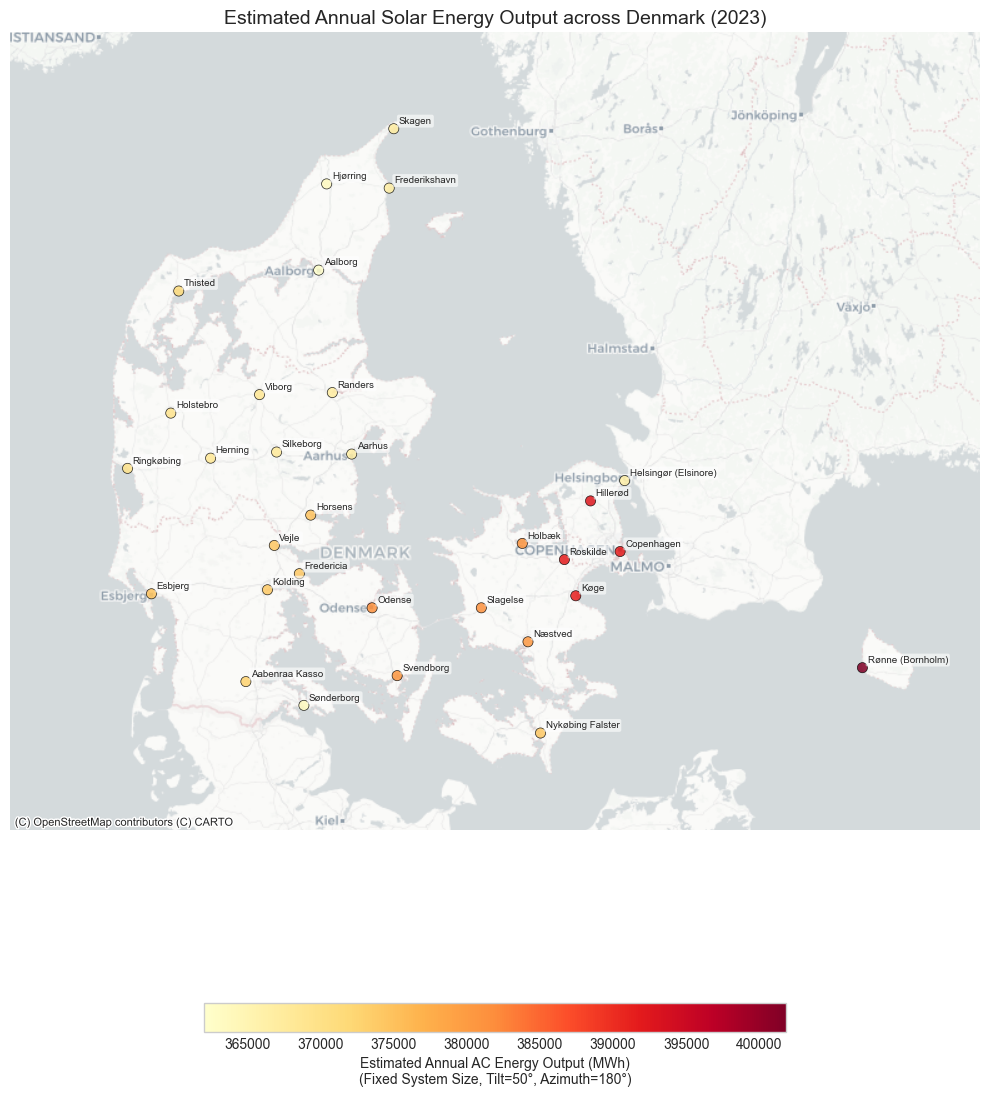


Geospatial solar analysis chunk complete.


In [8]:
# %% Chunk 7: Geospatial Solar Analysis

# Import necessary libraries for this specific chunk
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
import requests
import json
import time
import geopandas as gpd
import contextily as ctx # For adding basemaps
import os
import hashlib # For creating cache filenames
import pvlib
from pvlib.modelchain import ModelChain
from pvlib.location import Location
from pvlib.pvsystem import PVSystem
from pvlib.temperature import TEMPERATURE_MODEL_PARAMETERS

print("\nStarting Geospatial Solar Analysis...")

# --- User Inputs & Constants for Geospatial Solar Analysis ---
# API and Simulation Parameters
SOLAR_START_DATE = "20230101"        # Start date for NASA POWER API query
SOLAR_END_DATE = "20231231"          # End date for NASA POWER API query
SOLAR_PARAMETERS = "ALLSKY_SFC_SW_DWN,ALLSKY_SFC_SW_DNI,ALLSKY_SFC_SW_DIFF,T2M,WS10M" # Request GHI, DNI, DHI, Temp, Wind Speed
SOLAR_COMMUNITY = "RE"               # NASA POWER community parameter
SOLAR_OUTPUT_FORMAT = "JSON"         # NASA POWER output format
API_DELAY_SECONDS = 0.2              # Small delay between API calls to avoid overwhelming the server
CACHE_DIR = "nasa_power_solar_cache" # Directory to store cached API responses
ZOOM_OUT_FACTOR = 0.10               # Factor to zoom out map slightly for better context

# PV System Parameters (using values from Chunk 1 for consistency)
# Note: Using a fixed system size/config for comparison across locations
SOLAR_TOTAL_MODULES_TARGET = 1069776 # Target number of modules (determines farm size)
SOLAR_TARGET_DC_AC_RATIO = 1.25      # Target DC/AC ratio for inverter sizing
SOLAR_ALTITUDE = 10                  # Assumed altitude (can be refined per location if needed)
SOLAR_TIMEZONE = 'Europe/Copenhagen' # Common timezone for all Danish locations
SOLAR_MODULE_MODEL_NAME = 'Canadian_Solar_CS6X_300M__2013_' # Module model
SOLAR_INVERTER_MODEL_NAME = 'Yaskawa_Solectria_Solar__SGI_750XTM__380V_' # Inverter model
SOLAR_TEMP_MODEL_PARAMS_TYPE = 'open_rack_glass_polymer' # Temperature model type
SOLAR_SURFACE_TILT = 50              # Fixed tilt for comparison
SOLAR_SURFACE_AZIMUTH = 180            # Fixed azimuth (South) for comparison

# List of locations in Denmark to analyze
locations = [
    {'name': 'Skagen', 'latitude': 57.72, 'longitude': 10.58},
    {'name': 'Copenhagen', 'latitude': 55.68, 'longitude': 12.57},
    {'name': 'Aarhus', 'latitude': 56.16, 'longitude': 10.21},
    {'name': 'Odense', 'latitude': 55.40, 'longitude': 10.39},
    {'name': 'Esbjerg', 'latitude': 55.47, 'longitude': 8.45},
    {'name': 'Aalborg', 'latitude': 57.05, 'longitude': 9.92},
    {'name': 'Rønne (Bornholm)', 'latitude': 55.10, 'longitude': 14.70},
    {'name': 'Aabenraa Kasso', 'latitude': 55.03, 'longitude': 9.28}, # Original location
    {'name': 'Randers', 'latitude': 56.46, 'longitude': 10.04},
    {'name': 'Kolding', 'latitude': 55.49, 'longitude': 9.47},
    {'name': 'Horsens', 'latitude': 55.86, 'longitude': 9.85},
    {'name': 'Vejle', 'latitude': 55.71, 'longitude': 9.53},
    {'name': 'Roskilde', 'latitude': 55.64, 'longitude': 12.08},
    {'name': 'Herning', 'latitude': 56.14, 'longitude': 8.97},
    {'name': 'Silkeborg', 'latitude': 56.17, 'longitude': 9.55},
    {'name': 'Næstved', 'latitude': 55.23, 'longitude': 11.76},
    {'name': 'Fredericia', 'latitude': 55.57, 'longitude': 9.75},
    {'name': 'Viborg', 'latitude': 56.45, 'longitude': 9.40},
    {'name': 'Køge', 'latitude': 55.46, 'longitude': 12.18},
    {'name': 'Holstebro', 'latitude': 56.36, 'longitude': 8.62},
    {'name': 'Slagelse', 'latitude': 55.40, 'longitude': 11.35},
    {'name': 'Hillerød', 'latitude': 55.93, 'longitude': 12.31},
    {'name': 'Sønderborg', 'latitude': 54.91, 'longitude': 9.79},
    {'name': 'Svendborg', 'latitude': 55.06, 'longitude': 10.61},
    {'name': 'Hjørring', 'latitude': 57.46, 'longitude': 9.99},
    {'name': 'Frederikshavn', 'latitude': 57.44, 'longitude': 10.54},
    {'name': 'Nykøbing Falster', 'latitude': 54.77, 'longitude': 11.87},
    {'name': 'Helsingør (Elsinore)', 'latitude': 56.03, 'longitude': 12.61},
    {'name': 'Holbæk', 'latitude': 55.72, 'longitude': 11.71},
    {'name': 'Ringkøbing', 'latitude': 56.09, 'longitude': 8.24},
    {'name': 'Thisted', 'latitude': 56.95, 'longitude': 8.69},
]
print(f"Defined {len(locations)} locations for analysis.")

# --- Helper Functions ---

# Function to get solar weather data from NASA POWER API with caching
def get_solar_data(latitude, longitude, start_date, end_date, parameters, cache_dir):
    """
    Fetches hourly solar irradiance and weather data from NASA POWER API.
    Uses a local cache to avoid redundant downloads.

    Args:
        latitude (float): Latitude of the location.
        longitude (float): Longitude of the location.
        start_date (str): Start date in 'YYYYMMDD' format.
        end_date (str): End date in 'YYYYMMDD' format.
        parameters (str): Comma-separated string of NASA POWER parameters.
        cache_dir (str): Directory path to store cached data.

    Returns:
        pandas.DataFrame or None: DataFrame with weather data or None if fetch fails.
    """
    # Create a unique filename based on inputs for caching
    param_hash = hashlib.md5(parameters.encode()).hexdigest()[:8] # Short hash of parameters
    cache_filename = f"solar_{latitude:.4f}_{longitude:.4f}_{start_date}_{end_date}_{param_hash}.json"
    cache_filepath = os.path.join(cache_dir, cache_filename)

    # Check if cached data exists
    if os.path.exists(cache_filepath):
        try:
            # Try reading from cache
            df = pd.read_json(cache_filepath, orient='split')
            # Ensure index is DatetimeIndex after reading from JSON
            if not isinstance(df.index, pd.DatetimeIndex):
                 df.index = pd.to_datetime(df.index)
            # Ensure timezone is set (should be UTC from NASA POWER)
            if df.index.tz is None:
                 df.index = df.index.tz_localize('UTC')
            print(f"Cache hit for {latitude:.2f}, {longitude:.2f}. Loaded from {cache_filename}")
            return df
        except Exception as e:
            print(f"Cache read error for {cache_filename}: {e}. Fetching from API.")
            # If cache read fails, proceed to fetch from API

    # Fetch data from API if not cached or cache read failed
    print(f"Cache miss for {latitude:.2f}, {longitude:.2f}. Fetching from NASA POWER API...")
    base_url = "https://power.larc.nasa.gov/api/temporal/hourly/point"
    payload = {
        "latitude": latitude,
        "longitude": longitude,
        "start": start_date,
        "end": end_date,
        "parameters": parameters,
        "community": SOLAR_COMMUNITY,
        "format": SOLAR_OUTPUT_FORMAT,
        "header": True # Request header info
    }
    try:
        response = requests.get(base_url, params=payload, timeout=60) # 60-second timeout
        response.raise_for_status() # Raise HTTPError for bad responses (4xx or 5xx)
        data = response.json()

        # Basic validation of the response structure
        if 'properties' not in data or 'parameter' not in data['properties']:
            print(f"Error: Unexpected API response structure for {latitude:.2f}, {longitude:.2f}. Missing 'properties' or 'parameter'.")
            return None

        parameter_data = data['properties']['parameter']
        # Check if all requested parameters are present
        requested_params_list = parameters.split(',')
        if not all(p in parameter_data for p in requested_params_list):
             missing_params = [p for p in requested_params_list if p not in parameter_data]
             print(f"Warning: Missing parameters in API response for {latitude:.2f}, {longitude:.2f}: {missing_params}")
             # Decide whether to proceed or return None based on missing parameters
             # For this analysis, GHI, DNI, DHI, T2M, WS10M are important.
             core_params = ['ALLSKY_SFC_SW_DWN', 'ALLSKY_SFC_SW_DNI', 'ALLSKY_SFC_SW_DIFF', 'T2M', 'WS10M']
             if not all(p in parameter_data for p in core_params):
                  print("Error: Core parameters missing. Cannot proceed.")
                  return None

        # Create DataFrame
        df = pd.DataFrame(parameter_data)
        # Convert index to datetime (NASA format YYYYMMDDHH) and handle errors
        df.index = pd.to_datetime(df.index, format='%Y%m%d%H', errors='coerce')
        # Drop rows with invalid dates (NaT)
        df = df[pd.notna(df.index)]
        # Localize index to UTC
        df.index = df.index.tz_localize('UTC')

        # Replace NASA POWER fill value (-999) with NaN
        df.replace(-999.0, np.nan, inplace=True)

        # Rename columns to pvlib standard names
        rename_dict = {
            'ALLSKY_SFC_SW_DWN': 'ghi',
            'ALLSKY_SFC_SW_DNI': 'dni',
            'ALLSKY_SFC_SW_DIFF': 'dhi',
            'T2M': 'temp_air', # Temperature at 2 meters
            'WS10M': 'wind_speed' # Wind speed at 10 meters
        }
        df = df.rename(columns=rename_dict)

        # Select only the columns needed for pvlib simulation
        required_cols = ['ghi', 'dni', 'dhi', 'temp_air', 'wind_speed']
        # Filter rename_dict to existing columns before selecting
        existing_pvlib_cols = [col for col in required_cols if col in df.columns]
        df = df[existing_pvlib_cols]


        # Fill missing values (consider ffill/bfill or interpolation)
        df = df.ffill().bfill() # Simple forward/backward fill

        # Cache the fetched and processed data
        try:
            os.makedirs(cache_dir, exist_ok=True) # Ensure cache directory exists
            df.to_json(cache_filepath, orient='split', date_format='iso')
            print(f"Saved fetched data to cache: {cache_filename}")
        except Exception as e:
            print(f"Error writing cache file {cache_filename}: {e}")

        return df

    except requests.exceptions.Timeout:
        print(f"Error: API request timed out for {latitude:.2f}, {longitude:.2f}.")
        return None
    except requests.exceptions.RequestException as e:
        print(f"Error: API request failed for {latitude:.2f}, {longitude:.2f}: {e}")
        return None
    except json.JSONDecodeError as e:
         print(f"Error: Could not decode JSON response for {latitude:.2f}, {longitude:.2f}: {e}")
         return None
    except Exception as e:
        print(f"Error processing data for {latitude:.2f}, {longitude:.2f}: {e}")
        return None

# Function to calculate annual solar energy yield for a given location and weather data
def calculate_solar_energy(latitude, longitude, weather_df):
    """
    Calculates the total annual AC energy yield for a predefined PV system
    at a specific location using provided weather data.

    Args:
        latitude (float): Latitude of the location.
        longitude (float): Longitude of the location.
        weather_df (pandas.DataFrame): DataFrame containing hourly weather data
                                       (ghi, dni, dhi, temp_air, wind_speed) with UTC DatetimeIndex.

    Returns:
        float or None: Total annual energy yield in MWh, or None if calculation fails.
    """
    if weather_df is None or weather_df.empty:
        print(f"Calculation skipped for {latitude:.2f}, {longitude:.2f}: Weather data is missing or empty.")
        return None

    # Check for required columns
    required_cols = ['ghi', 'dni', 'dhi', 'temp_air', 'wind_speed']
    if not all(col in weather_df.columns for col in required_cols):
        missing = [col for col in required_cols if col not in weather_df.columns]
        print(f"Calculation skipped for {latitude:.2f}, {longitude:.2f}: Missing weather columns: {missing}")
        return None

    try:
        # Define location object
        location = Location(latitude=latitude, longitude=longitude, tz=SOLAR_TIMEZONE, altitude=SOLAR_ALTITUDE)

        # Retrieve component parameters (cached by pvlib after first call)
        sandia_modules = pvlib.pvsystem.retrieve_sam('SandiaMod')
        cec_inverters = pvlib.pvsystem.retrieve_sam('CECInverter')
        module = sandia_modules[SOLAR_MODULE_MODEL_NAME]
        inverter = cec_inverters[SOLAR_INVERTER_MODEL_NAME]
        temperature_parameters = TEMPERATURE_MODEL_PARAMETERS['sapm'][SOLAR_TEMP_MODEL_PARAMS_TYPE]

        # --- Calculate System Configuration (same logic as Chunk 2) ---
        # This ensures the same farm size/layout is simulated for each location
        INVERTER_AC_LIMIT_W = inverter.Paco
        INVERTER_AC_LIMIT_MW = INVERTER_AC_LIMIT_W / 1e6
        nominal_dc_power_per_module_w = module.Vmpo * module.Impo
        if nominal_dc_power_per_module_w <= 0 or pd.isna(nominal_dc_power_per_module_w):
             raise ValueError("Nominal DC power per module invalid.")
        max_mods_vdcmax = np.floor(inverter.Vdcmax / module.Voco) if module.Voco > 0 else np.inf
        max_mods_mppt_high = np.floor(inverter.Mppt_high / module.Vmpo) if module.Vmpo > 0 else np.inf
        min_mods_mppt_low = np.ceil(inverter.Mppt_low / module.Vmpo) if module.Vmpo > 0 else 0
        modules_per_string = int(min(max_mods_vdcmax, max_mods_mppt_high))
        if modules_per_string < min_mods_mppt_low: modules_per_string = int(min_mods_mppt_low)
        if modules_per_string <= 0: modules_per_string = 1
        target_dc_power_per_inverter_mw = INVERTER_AC_LIMIT_MW * SOLAR_TARGET_DC_AC_RATIO
        modules_per_inverter_target = (target_dc_power_per_inverter_mw * 1e6) / nominal_dc_power_per_module_w
        strings_per_inverter = int(np.ceil(modules_per_inverter_target / modules_per_string)) if modules_per_string > 0 else 1
        if strings_per_inverter <= 0: strings_per_inverter = 1
        modules_per_inverter_actual = modules_per_string * strings_per_inverter
        if modules_per_inverter_actual <= 0: raise ValueError("Modules per inverter invalid.")
        num_inverters = int(np.ceil(SOLAR_TOTAL_MODULES_TARGET / modules_per_inverter_actual)) if modules_per_inverter_actual > 0 else 1
        if num_inverters <= 0: num_inverters = 1
        # total_modules_actual = num_inverters * modules_per_inverter_actual # Not strictly needed here

        # Define PVSystem for a single inverter block
        system = PVSystem(
            surface_tilt=SOLAR_SURFACE_TILT,
            surface_azimuth=SOLAR_SURFACE_AZIMUTH,
            module_parameters=module,
            inverter_parameters=inverter,
            temperature_model_parameters=temperature_parameters,
            modules_per_string=modules_per_string,
            strings_per_inverter=strings_per_inverter
        )

        # Create ModelChain
        modelchain = ModelChain(system, location)

        # Ensure weather data index is localized correctly for the modelchain
        if weather_df.index.tz is None:
             weather_df.index = weather_df.index.tz_localize('UTC') # Assume UTC if naive
        # Convert weather data index to the location's timezone for simulation
        weather_df_local = weather_df.tz_convert(location.tz)

        # Run the model
        modelchain.run_model(weather_df_local)

        # Calculate AC power and total energy
        ac_power_single_clipped_w = modelchain.results.ac.clip(lower=0, upper=INVERTER_AC_LIMIT_W).fillna(0)
        # Scale to total farm power (Watts)
        total_ac_power_w = ac_power_single_clipped_w * num_inverters

        # Calculate total energy (MWh) - Summing hourly power gives Wh, convert to MWh
        total_energy_mwh = total_ac_power_w.sum() / 1e6 # sum assumes hourly data, result in MWh

        return total_energy_mwh

    except Exception as e:
        print(f"Error during pvlib simulation for {latitude:.2f}, {longitude:.2f}: {e}")
        return None

# --- Main Processing Loop ---
results = [] # List to store results for each location
os.makedirs(CACHE_DIR, exist_ok=True) # Ensure cache directory exists

print(f"\nProcessing {len(locations)} locations...")
for i, loc in enumerate(locations):
    print(f"--- Location {i+1}/{len(locations)}: {loc['name']} ({loc['latitude']:.2f}, {loc['longitude']:.2f}) ---")
    # Get weather data (from cache or API)
    weather_df = get_solar_data(loc['latitude'], loc['longitude'], SOLAR_START_DATE, SOLAR_END_DATE, SOLAR_PARAMETERS, CACHE_DIR)

    # Calculate energy yield if weather data was obtained
    total_energy_mwh = calculate_solar_energy(loc['latitude'], loc['longitude'], weather_df)

    # Store results (even if calculation failed, store NaN)
    results.append({
        'name': loc['name'],
        'latitude': loc['latitude'],
        'longitude': loc['longitude'],
        'total_energy_mwh': total_energy_mwh if total_energy_mwh is not None else np.nan
    })

    # Add a small delay between API calls
    time.sleep(API_DELAY_SECONDS)

print("\nFinished processing all locations.")

# Convert results list to DataFrame
results_df = pd.DataFrame(results)

# Drop rows where energy calculation failed completely (resulted in NaN)
results_df_clean = results_df.dropna(subset=['total_energy_mwh'])
print(f"\nSuccessfully calculated energy for {len(results_df_clean)} out of {len(locations)} locations.")
print("Failed locations (if any):")
print(results_df[results_df['total_energy_mwh'].isna()]['name'].tolist())

# --- Plotting Results on a Map ---
if not results_df_clean.empty:
    print("\nGenerating geospatial plot...")
    # Create GeoDataFrame
    gdf = gpd.GeoDataFrame(
        results_df_clean,
        geometry=gpd.points_from_xy(results_df_clean.longitude, results_df_clean.latitude),
        crs="EPSG:4326" # WGS 84 coordinate system
    )

    # Reproject to Web Mercator (EPSG:3857) for compatibility with contextily basemaps
    gdf_wm = gdf.to_crs(epsg=3857)

    # Create the plot
    fig, ax = plt.subplots(1, 1, figsize=(10, 12)) # Adjust figure size as needed

    # Determine point size dynamically (optional, makes less dense maps clearer)
    base_size = 100
    num_points = len(gdf_wm)
    point_size = max(20, base_size - num_points * 1.5) # Decrease size slightly as points increase

    # Plot points on the map, colored by energy yield
    plot = gdf_wm.plot(
        column='total_energy_mwh', # Column to determine color
        cmap='YlOrRd',             # Colormap (Yellow-Orange-Red is good for energy)
        s=point_size,              # Size of points
        alpha=0.85,                # Point transparency
        edgecolor='k',             # Point border color
        linewidth=0.5,             # Point border width
        legend=True,               # Show color legend
        legend_kwds={              # Legend customization
            'label': f"Estimated Annual AC Energy Output (MWh)\n(Fixed System Size, Tilt={SOLAR_SURFACE_TILT}°, Azimuth={SOLAR_SURFACE_AZIMUTH}°)",
            'orientation': "horizontal",
            'shrink': 0.6          # Make legend smaller than the axis
        },
        ax=ax,                     # Plot on the created axes
        zorder=3                   # Ensure points are plotted above the basemap
    )

    # Add labels for each point (optional, can get cluttered)
    label_offset_m = 5000 # Offset labels slightly in meters (in Web Mercator units)
    for idx, row in gdf_wm.iterrows():
        ax.text(row.geometry.x + label_offset_m, row.geometry.y + label_offset_m,
                row['name'], fontsize=7, zorder=4, # Label text properties
                bbox=dict(boxstyle="round,pad=0.2", fc="white", alpha=0.6, ec='none')) # Add background box

    # Adjust map bounds slightly
    xmin, xmax = ax.get_xlim()
    ymin, ymax = ax.get_ylim()
    x_padding = (xmax - xmin) * ZOOM_OUT_FACTOR
    y_padding = (ymax - ymin) * ZOOM_OUT_FACTOR
    ax.set_xlim(xmin - x_padding, xmax + x_padding)
    ax.set_ylim(ymin - y_padding, ymax + y_padding)

    # Add a basemap using contextily
    try:
        ctx.add_basemap(ax, crs=gdf_wm.crs.to_string(), source=ctx.providers.CartoDB.Positron, zorder=1)
        print("Added CartoDB Positron basemap.")
    except Exception as e:
        print(f"Could not add basemap: {e}")

    # Final plot adjustments
    sim_year_geo = SOLAR_START_DATE[:4]
    ax.set_title(f'Estimated Annual Solar Energy Output across Denmark ({sim_year_geo})', fontsize=14)
    ax.set_axis_off() # Hide axis labels and ticks
    plt.tight_layout()
    # plt.savefig('solar_energy_map_denmark.png', dpi=300) # Optional: Save the figure
    plt.show()

else:
    print("\nSkipping geospatial plot: No valid energy results to plot.")

print("\nGeospatial solar analysis chunk complete.")



Starting Geospatial Wind Analysis...
Defined 31 locations for wind analysis.

Processing 31 locations for wind energy...
--- Wind Location 1/31: Skagen (57.72, 10.58) ---
Cache hit for wind data at 57.72, 10.58. Loaded from power_57.7200_10.5800_20230101_20231231_48887439_windlib.json
--- Wind Location 2/31: Copenhagen (55.68, 12.57) ---
Cache hit for wind data at 55.68, 12.57. Loaded from power_55.6800_12.5700_20230101_20231231_48887439_windlib.json
--- Wind Location 3/31: Aarhus (56.16, 10.21) ---
Cache hit for wind data at 56.16, 10.21. Loaded from power_56.1600_10.2100_20230101_20231231_48887439_windlib.json
--- Wind Location 4/31: Odense (55.40, 10.39) ---
Cache hit for wind data at 55.40, 10.39. Loaded from power_55.4000_10.3900_20230101_20231231_48887439_windlib.json
--- Wind Location 5/31: Esbjerg (55.47, 8.45) ---
Cache hit for wind data at 55.47, 8.45. Loaded from power_55.4700_8.4500_20230101_20231231_48887439_windlib.json
--- Wind Location 6/31: Aalborg (57.05, 9.92) ---
C

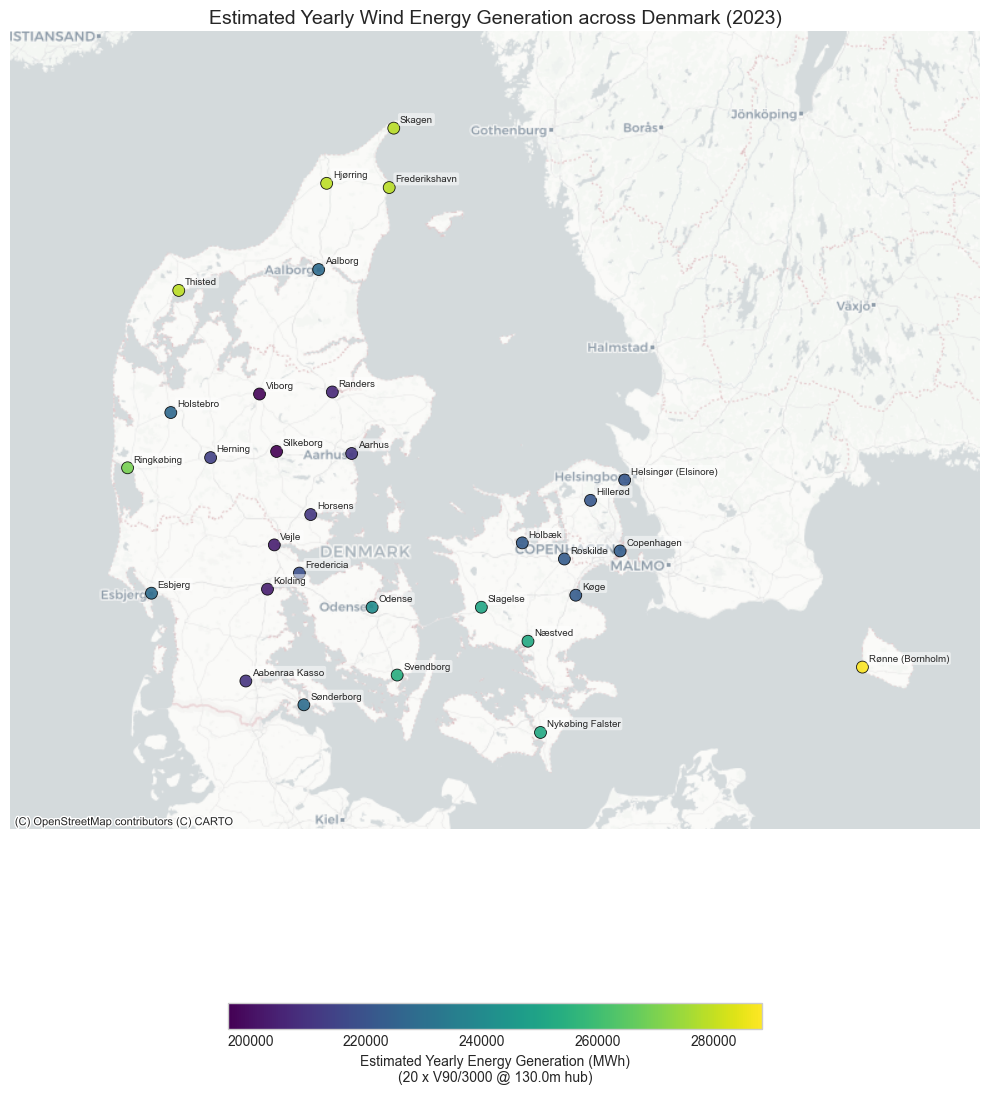


Geospatial wind analysis chunk complete.


In [9]:
# %% Chunk 8: Geospatial Wind Analysis (Results in MWh)

# Import necessary libraries for this specific chunk
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
import requests
import json
import time
import geopandas as gpd
import contextily as ctx # For adding basemaps
import os
import hashlib # For creating cache filenames
from windpowerlib import WindTurbine, WindFarm, TurbineClusterModelChain
import warnings # To potentially filter warnings from libraries

print("\nStarting Geospatial Wind Analysis...")

# --- User Inputs & Constants for Geospatial Wind Analysis ---
# API and Simulation Parameters
START_DATE = "20230101"             # Start date for NASA POWER API query
END_DATE = "20231231"               # End date for NASA POWER API query
WIND_PARAMETERS = "T2M,PS,WS10M,WD10M,WS50M,T10M,WD50M" # Parameters needed for windpowerlib extrapolation
WIND_COMMUNITY = "RE"               # NASA POWER community parameter
WIND_OUTPUT_FORMAT = "JSON"         # NASA POWER output format
API_DELAY_SECONDS = 0.2             # Small delay between API calls
CACHE_DIR = "nasa_power_cache_windlib" # Directory for wind data cache
ZOOM_OUT_FACTOR = 0.10              # Map zoom factor
MAP_CRS = "EPSG:3857"               # Coordinate Reference System for plotting (Web Mercator)

# Wind Farm Configuration (Fixed for comparison across locations)
WIND_TARGET_HEIGHT = 130.0          # Hub height (meters)
WIND_ROUGHNESS_VALUE = 0.15         # Assumed surface roughness length
WIND_HELLMAN_EXPONENT = 0.15        # Assumed Hellmann exponent (can be calculated if needed)
WIND_SELECTED_TURBINE_TYPE = 'V90/3000' # Turbine model from windpowerlib db
WIND_NUM_TURBINES = 20              # Number of turbines per hypothetical farm
WIND_SPACING_FACTOR = 7             # Turbine spacing (rotor diameters)
WIND_ROTOR_DIAMETER = 90.0          # Rotor diameter (meters) for the selected turbine

# List of locations (same as solar analysis)
locations = [
    {'name': 'Skagen', 'latitude': 57.72, 'longitude': 10.58},
    {'name': 'Copenhagen', 'latitude': 55.68, 'longitude': 12.57},
    {'name': 'Aarhus', 'latitude': 56.16, 'longitude': 10.21},
    {'name': 'Odense', 'latitude': 55.40, 'longitude': 10.39},
    {'name': 'Esbjerg', 'latitude': 55.47, 'longitude': 8.45},
    {'name': 'Aalborg', 'latitude': 57.05, 'longitude': 9.92},
    {'name': 'Rønne (Bornholm)', 'latitude': 55.10, 'longitude': 14.70},
    {'name': 'Aabenraa Kasso', 'latitude': 55.03, 'longitude': 9.28},
    {'name': 'Randers', 'latitude': 56.46, 'longitude': 10.04},
    {'name': 'Kolding', 'latitude': 55.49, 'longitude': 9.47},
    {'name': 'Horsens', 'latitude': 55.86, 'longitude': 9.85},
    {'name': 'Vejle', 'latitude': 55.71, 'longitude': 9.53},
    {'name': 'Roskilde', 'latitude': 55.64, 'longitude': 12.08},
    {'name': 'Herning', 'latitude': 56.14, 'longitude': 8.97},
    {'name': 'Silkeborg', 'latitude': 56.17, 'longitude': 9.55},
    {'name': 'Næstved', 'latitude': 55.23, 'longitude': 11.76},
    {'name': 'Fredericia', 'latitude': 55.57, 'longitude': 9.75},
    {'name': 'Viborg', 'latitude': 56.45, 'longitude': 9.40},
    {'name': 'Køge', 'latitude': 55.46, 'longitude': 12.18},
    {'name': 'Holstebro', 'latitude': 56.36, 'longitude': 8.62},
    {'name': 'Slagelse', 'latitude': 55.40, 'longitude': 11.35},
    {'name': 'Hillerød', 'latitude': 55.93, 'longitude': 12.31},
    {'name': 'Sønderborg', 'latitude': 54.91, 'longitude': 9.79},
    {'name': 'Svendborg', 'latitude': 55.06, 'longitude': 10.61},
    {'name': 'Hjørring', 'latitude': 57.46, 'longitude': 9.99},
    {'name': 'Frederikshavn', 'latitude': 57.44, 'longitude': 10.54},
    {'name': 'Nykøbing Falster', 'latitude': 54.77, 'longitude': 11.87},
    {'name': 'Helsingør (Elsinore)', 'latitude': 56.03, 'longitude': 12.61},
    {'name': 'Holbæk', 'latitude': 55.72, 'longitude': 11.71},
    {'name': 'Ringkøbing', 'latitude': 56.09, 'longitude': 8.24},
    {'name': 'Thisted', 'latitude': 56.95, 'longitude': 8.69},
]
print(f"Defined {len(locations)} locations for wind analysis.")

# --- Helper Functions ---

# Function to get wind weather data from NASA POWER API with caching
def get_wind_data(latitude, longitude, start_date, end_date, parameters, cache_dir):
    """
    Fetches hourly wind-related weather data from NASA POWER API.
    Uses a local cache to avoid redundant downloads.

    Args:
        latitude (float): Latitude of the location.
        longitude (float): Longitude of the location.
        start_date (str): Start date in 'YYYYMMDD' format.
        end_date (str): End date in 'YYYYMMDD' format.
        parameters (str): Comma-separated string of NASA POWER parameters.
        cache_dir (str): Directory path to store cached data.

    Returns:
        pandas.DataFrame or None: DataFrame with weather data or None if fetch fails.
    """
    # Create a unique filename based on inputs for caching
    param_hash = hashlib.md5(parameters.encode()).hexdigest()[:8]
    cache_filename = f"power_{latitude:.4f}_{longitude:.4f}_{start_date}_{end_date}_{param_hash}_windlib.json"
    cache_filepath = os.path.join(cache_dir, cache_filename)

    # Check if cached data exists
    if os.path.exists(cache_filepath):
        try:
            # Try reading from cache
            df = pd.read_json(cache_filepath, orient='split')
            # Ensure index is DatetimeIndex and localized to UTC
            if not isinstance(df.index, pd.DatetimeIndex):
                 df.index = pd.to_datetime(df.index)
            if df.index.tz is None:
                 df.index = df.index.tz_localize('UTC')
            print(f"Cache hit for wind data at {latitude:.2f}, {longitude:.2f}. Loaded from {cache_filename}")
            return df
        except Exception as e:
            print(f"Wind cache read error for {cache_filename}: {e}. Fetching from API.")
            # Proceed to fetch from API if cache read fails

    # Fetch data from API if not cached or cache read failed
    print(f"Cache miss for wind data at {latitude:.2f}, {longitude:.2f}. Fetching from NASA POWER API...")
    base_url = "https://power.larc.nasa.gov/api/temporal/hourly/point"
    payload = {
        "latitude": latitude, "longitude": longitude, "start": start_date,
        "end": end_date, "parameters": parameters, "community": WIND_COMMUNITY,
        "format": WIND_OUTPUT_FORMAT, "header": True
    }
    try:
        response = requests.get(base_url, params=payload, timeout=90) # Increased timeout
        response.raise_for_status()
        data = response.json()

        # Validate response structure
        if 'properties' not in data or 'parameter' not in data['properties']:
            print(f"Error: Unexpected API response structure for wind data at {latitude:.2f}, {longitude:.2f}.")
            return None

        parameter_data = data['properties']['parameter']
        # Check if core parameters needed for windpowerlib are present
        core_params = ['T2M', 'PS', 'WS10M', 'WD10M', 'WS50M', 'WD50M']
        if not all(p in parameter_data for p in core_params):
             missing_core = [p for p in core_params if p not in parameter_data]
             print(f"Error: Core wind parameters missing for {latitude:.2f}, {longitude:.2f}: {missing_core}")
             return None

        # Create DataFrame
        df = pd.DataFrame(parameter_data)
        # Convert index to datetime and handle errors
        df.index = pd.to_datetime(df.index, format='%Y%m%d%H', errors='coerce')
        # Drop rows with invalid dates (NaT)
        df = df[pd.notna(df.index)]
        # Localize index to UTC
        df.index = df.index.tz_localize('UTC')

        # Replace NASA POWER fill value (-999) with NaN
        df.replace(-999.0, np.nan, inplace=True)

        # Convert columns to numeric, coercing errors
        for col in df.columns:
             df[col] = pd.to_numeric(df[col], errors='coerce')

        # Fill missing values
        df = df.ffill().bfill()

        # Cache the fetched and processed data
        try:
            os.makedirs(cache_dir, exist_ok=True)
            df.to_json(cache_filepath, orient='split', date_format='iso')
            print(f"Saved fetched wind data to cache: {cache_filename}")
        except Exception as e:
            print(f"Error writing wind cache file {cache_filename}: {e}")

        return df

    except requests.exceptions.Timeout:
        print(f"Error: API request timed out for wind data at {latitude:.2f}, {longitude:.2f}.")
        return None
    except requests.exceptions.RequestException as e:
        print(f"Error: API request failed for wind data at {latitude:.2f}, {longitude:.2f}: {e}")
        return None
    except json.JSONDecodeError as e:
         print(f"Error: Could not decode JSON response for wind data at {latitude:.2f}, {longitude:.2f}: {e}")
         return None
    except Exception as e:
        print(f"Error processing wind data for {latitude:.2f}, {longitude:.2f}: {e}")
        return None

# Function to calculate annual wind energy yield using windpowerlib
def calculate_yearly_wind_energy(weather_df_raw, turbine_config):
    """
    Calculates the total annual energy yield for a predefined wind farm
    using windpowerlib.

    Args:
        weather_df_raw (pandas.DataFrame): Raw weather data from NASA POWER API.
        turbine_config (dict): Dictionary containing turbine and farm parameters
                               ('type', 'hub_height', 'num_turbines',
                                'spacing_factor', 'rotor_diameter').

    Returns:
        float or np.nan: Total annual energy yield in MWh, or np.nan if calculation fails.
    """
    if weather_df_raw is None or weather_df_raw.empty:
        print("Wind energy calculation skipped: Weather data is missing or empty.")
        return np.nan

    # Make a copy to avoid modifying the original DataFrame
    df = weather_df_raw.copy()

    # --- Data Processing (similar to Chunk 3) ---
    try:
        # Add roughness length
        df['roughness_length'] = WIND_ROUGHNESS_VALUE

        # Define measurement heights
        h_ws1 = 10.0; h_ws2 = 50.0
        h_t1 = 2.0; h_t2 = 10.0 # T10M might be missing, handle later
        z_ref = 50.0 # Reference height for WD50M
        z_hub = turbine_config['hub_height']

        # Calculate Hellmann exponent (alpha) safely
        ws10m_safe = df['WS10M'].replace(0, np.nan)
        ws50m_safe = df['WS50M'].replace(0, np.nan)
        ratio_ws = (ws50m_safe / ws10m_safe).replace([np.inf, -np.inf], np.nan)
        log_ratio_h = np.log(h_ws2 / h_ws1) if h_ws1 > 0 and h_ws2 > 0 and h_ws1 != h_ws2 else np.nan

        alpha = pd.Series(np.nan, index=df.index)
        if pd.notna(log_ratio_h) and log_ratio_h != 0:
            valid_alpha_idx = ratio_ws.dropna().index[ratio_ws.dropna() > 0]
            alpha.loc[valid_alpha_idx] = np.log(ratio_ws.loc[valid_alpha_idx]) / log_ratio_h
        alpha.fillna(WIND_HELLMAN_EXPONENT, inplace=True)

        # Calculate wind speed at target height
        ws_target_col = f'WS_{int(z_hub)}m'
        df[ws_target_col] = df['WS50M'] * (z_hub / h_ws2) ** alpha if h_ws2 > 0 else df['WS50M']
        df[ws_target_col] = df[ws_target_col].clip(lower=0)

        # Calculate temperature at target height
        t_target_col = f'T_{int(z_hub)}m'
        if 'T10M' in df.columns and h_t2 != h_t1:
            valid_temp_idx = df[['T2M', 'T10M']].dropna().index
            temp_diff = df.loc[valid_temp_idx, 'T10M'] - df.loc[valid_temp_idx, 'T2M']
            height_ratio = (z_hub - h_t1) / (h_t2 - h_t1)
            df[t_target_col] = np.nan
            df.loc[valid_temp_idx, t_target_col] = df.loc[valid_temp_idx, 'T2M'] + temp_diff * height_ratio
            df[t_target_col] = df[t_target_col].fillna(df['T2M'])
        else:
            df[t_target_col] = df['T2M']

        # Calculate wind direction at target height
        wd_ref_col = 'WD50M'
        wd_target_col = f'WD_{int(z_hub)}m'
        if z_ref > 0:
            df[wd_ref_col] = pd.to_numeric(df[wd_ref_col], errors='coerce').fillna(0)
            df[wd_target_col] = df[wd_ref_col] * (z_hub / z_ref) ** WIND_HELLMAN_EXPONENT
            df[wd_target_col] = df[wd_target_col] % 360.0
        else:
            df[wd_target_col] = df[wd_ref_col]

        # Rename columns for windpowerlib
        rename_map = {
            'T2M': 'temperature', 'PS': 'pressure', 'WS10M': 'wind_speed',
            'WS50M': 'wind_speed.1', 'T10M': 'temperature.1', 'WD50M': 'wind_direction',
            wd_target_col: f'wind_direction_{int(z_hub)}m',
            ws_target_col: f'wind_speed_{int(z_hub)}m',
            t_target_col: f'temperature_{int(z_hub)}m',
            'roughness_length': 'roughness_length'
        }
        rename_map_filtered = {k: v for k, v in rename_map.items() if k in df.columns}
        Weather_Data = df.rename(columns=rename_map_filtered)

        # Convert units
        temp_cols = [col for col in Weather_Data.columns if 'temperature' in col]
        for col in temp_cols:
            Weather_Data[col] = Weather_Data[col] + 273.15
        if 'pressure' in Weather_Data.columns:
            Weather_Data['pressure'] = Weather_Data['pressure'] * 1000

        # Drop unused original columns
        cols_to_drop = ['WD10M']
        cols_to_drop_existing = [c for c in cols_to_drop if c in Weather_Data.columns]
        Weather_Data.drop(columns=cols_to_drop_existing, inplace=True, errors='ignore')

        # Create MultiIndex
        current_columns = list(Weather_Data.columns)
        height_mapping = {
            'temperature': 2.0, 'pressure': 0.0, 'wind_speed': 10.0, 'wind_speed.1': 50.0,
            'temperature.1': 10.0, 'wind_direction': 50.0, 'roughness_length': 0.0,
            f'wind_direction_{int(z_hub)}m': float(z_hub),
            f'wind_speed_{int(z_hub)}m': float(z_hub),
            f'temperature_{int(z_hub)}m': float(z_hub),
        }
        filtered_height_mapping = {k: v for k, v in height_mapping.items() if k in current_columns}
        if len(filtered_height_mapping) != len(current_columns):
            missing_cols = [col for col in current_columns if col not in filtered_height_mapping]
            print(f"Warning: Height mapping missing for columns: {missing_cols}. Cannot run windpowerlib.")
            return np.nan

        heights = [filtered_height_mapping[col] for col in current_columns]
        multi_index = pd.MultiIndex.from_arrays(
            [current_columns, heights], names=['variable_name', 'height']
        )
        Weather_Data.columns = multi_index

    except Exception as e:
        print(f"Error during weather data processing for windpowerlib: {e}")
        return np.nan

    # --- Run windpowerlib Simulation ---
    try:
        # Define Wind Turbine
        Selected_Turbine_Details = {
            'turbine_type': turbine_config['type'],
            'hub_height': turbine_config['hub_height']
        }
        W_Turbine = WindTurbine(**Selected_Turbine_Details)

        # Define Wind Farm Layout
        radius = turbine_config['spacing_factor'] * turbine_config['rotor_diameter']
        angle_step = 360.0 / turbine_config['num_turbines'] if turbine_config['num_turbines'] > 0 else 0
        turbine_coordinates = []
        for i in range(turbine_config['num_turbines']):
            angle = np.radians(i * angle_step)
            x = radius * np.cos(angle)
            y = radius * np.sin(angle)
            turbine_coordinates.append([x, y])

        # Define Turbine Fleet
        Wind_Turbine_Fleet = [
            {
                'wind_turbine': W_Turbine,
                'number_of_turbines': 1,
                'coordinates': coord
            }
            for coord in turbine_coordinates
        ]
        Wind_Farm_Def = WindFarm(wind_turbine_fleet=Wind_Turbine_Fleet)

        # Define Model Chain Parameters
        Wind_Farm_Submodel = {
            'wake_loss_model': 'jensen',
            'wind_direction_model': (f'wind_direction_{int(z_hub)}m', float(z_hub)),
            'smoothing': True,
            'power_output_model': 'power_curve',
            'density_model': 'barometric',
            'temperature_model': 'linear_gradient',
            'wind_speed_model': 'logarithmic',
            'density_correction': True,
            'obstacle_height': 0,
        }

        # Initialize Model Chain
        Model = TurbineClusterModelChain(Wind_Farm_Def, **Wind_Farm_Submodel)

        # Ensure weather data index is DatetimeIndex and UTC
        if not isinstance(Weather_Data.index, pd.DatetimeIndex):
             Weather_Data.index = pd.to_datetime(Weather_Data.index)
        if Weather_Data.index.tz is None:
             Weather_Data.index = Weather_Data.index.tz_localize('UTC')
        elif str(Weather_Data.index.tz).upper() != 'UTC':
             Weather_Data.index = Weather_Data.index.tz_convert('UTC')

        # Run the model
        ModelResult = Model.run_model(Weather_Data)

        # Extract total power output (in Watts)
        total_hourly_power_w = ModelResult.power_output

        if total_hourly_power_w is None or total_hourly_power_w.isnull().all():
            print("Warning: Windpowerlib simulation resulted in no power output.")
            return np.nan

        # Calculate total annual energy (sum hourly power [W] -> Wh, convert to MWh)
        total_energy_wh = total_hourly_power_w.sum()
        total_energy_mwh = total_energy_wh / 1e6 # Convert Wh to MWh

        return total_energy_mwh

    except ImportError as e:
        print(f"Windpowerlib import error: {e}. Cannot calculate wind energy.")
        return np.nan
    except KeyError as e:
        print(f"Key error during windpowerlib setup: {e}")
        return np.nan
    except ValueError as e:
        print(f"Value error during windpowerlib setup/run: {e}")
        return np.nan
    except Exception as e:
        print(f"Unexpected error during wind energy calculation: {e}")
        return np.nan

# --- Main Processing Loop ---
results_wind = [] # List to store wind results

os.makedirs(CACHE_DIR, exist_ok=True) # Ensure cache directory exists

# Define the fixed turbine configuration for comparison
turbine_config = {
    'type': WIND_SELECTED_TURBINE_TYPE,
    'hub_height': WIND_TARGET_HEIGHT,
    'num_turbines': WIND_NUM_TURBINES,
    'spacing_factor': WIND_SPACING_FACTOR,
    'rotor_diameter': WIND_ROTOR_DIAMETER
}

print(f"\nProcessing {len(locations)} locations for wind energy...")
for i, loc in enumerate(locations):
    print(f"--- Wind Location {i+1}/{len(locations)}: {loc['name']} ({loc['latitude']:.2f}, {loc['longitude']:.2f}) ---")
    # Get weather data
    weather_df_wind = get_wind_data(loc['latitude'], loc['longitude'], START_DATE, END_DATE, WIND_PARAMETERS, CACHE_DIR)

    # Calculate yearly energy yield
    yearly_energy_mwh = calculate_yearly_wind_energy(weather_df_wind, turbine_config) # Now in MWh

    # Store results
    results_wind.append({
        'name': loc['name'],
        'latitude': loc['latitude'],
        'longitude': loc['longitude'],
        'yearly_energy_mwh': yearly_energy_mwh # Store MWh
    })

    # API delay
    time.sleep(API_DELAY_SECONDS)

print("\nFinished processing all wind locations.")

# Convert results to DataFrame
results_wind_df = pd.DataFrame(results_wind)

# Drop rows where energy calculation failed
results_wind_df_clean = results_wind_df.dropna(subset=['yearly_energy_mwh']) # Use new column name
print(f"\nSuccessfully calculated wind energy for {len(results_wind_df_clean)} out of {len(locations)} locations.")
print("Failed wind locations (if any):")
print(results_wind_df[results_wind_df['yearly_energy_mwh'].isna()]['name'].tolist()) # Use new column name


# --- Plotting Wind Results on a Map ---
if not results_wind_df_clean.empty:
    print("\nGenerating geospatial wind plot...")
    # Create GeoDataFrame
    gdf_wind = gpd.GeoDataFrame(
        results_wind_df_clean,
        geometry=gpd.points_from_xy(results_wind_df_clean.longitude, results_wind_df_clean.latitude),
        crs="EPSG:4326" # WGS 84
    )

    # Reproject to Web Mercator for basemap compatibility
    gdf_wind_wm = gdf_wind.to_crs(crs=MAP_CRS)

    # Create the plot
    fig_wind_map, ax_wind_map = plt.subplots(1, 1, figsize=(10, 12))

    # Determine point size
    base_size_wind = 120
    num_points_wind = len(gdf_wind_wm)
    point_size_wind = max(25, base_size_wind - num_points_wind * 1.5)

    # Plot points, colored by yearly energy yield (MWh)
    plot_wind = gdf_wind_wm.plot(
        column='yearly_energy_mwh', # Use new column name
        cmap='viridis',
        s=point_size_wind,
        alpha=0.9,
        edgecolor='k',
        linewidth=0.6,
        legend=True,
        legend_kwds={
            'label': f"Estimated Yearly Energy Generation (MWh)\n({turbine_config['num_turbines']} x {turbine_config['type']} @ {turbine_config['hub_height']}m hub)", # Updated label
            'orientation': "horizontal",
            'shrink': 0.55
        },
        ax=ax_wind_map,
        zorder=3
    )

    # Add labels
    label_offset_m_wind = 6000
    for idx, row in gdf_wind_wm.iterrows():
        ax_wind_map.text(row.geometry.x + label_offset_m_wind, row.geometry.y + label_offset_m_wind,
                         row['name'], fontsize=7, zorder=4,
                         bbox=dict(boxstyle="round,pad=0.2", fc="white", alpha=0.5, ec='none'))

    # Adjust map bounds
    xmin_w, xmax_w = ax_wind_map.get_xlim()
    ymin_w, ymax_w = ax_wind_map.get_ylim()
    x_padding_w = (xmax_w - xmin_w) * ZOOM_OUT_FACTOR
    y_padding_w = (ymax_w - ymin_w) * ZOOM_OUT_FACTOR
    ax_wind_map.set_xlim(xmin_w - x_padding_w, xmax_w + x_padding_w)
    ax_wind_map.set_ylim(ymin_w - y_padding_w, ymax_w + y_padding_w)

    # Add basemap
    try:
        ctx.add_basemap(ax_wind_map, crs=gdf_wind_wm.crs.to_string(), source=ctx.providers.CartoDB.Positron, zorder=1)
        print("Added CartoDB Positron basemap for wind map.")
    except Exception as e:
        print(f"Could not add basemap for wind map: {e}")

    # Final plot adjustments
    sim_year_geo_wind = START_DATE[:4]
    ax_wind_map.set_title(f'Estimated Yearly Wind Energy Generation across Denmark ({sim_year_geo_wind})', fontsize=14)
    ax_wind_map.set_axis_off()

    plt.tight_layout()
    # plt.savefig('wind_energy_map_denmark_mwh.png', dpi=300) # Optional: Save figure with new name
    plt.show()

else:
    print("\nSkipping geospatial wind plot: No valid wind energy results to plot.")

print("\nGeospatial wind analysis chunk complete.")



Starting Solar Sensitivity Analysis (Tilt/Azimuth)...
Setting up PV system for sensitivity analysis...
System configuration for sensitivity analysis:
  Modules per string: 18
  Strings per inverter: 184
  Number of inverters: 323
  Total nominal AC capacity: 243.28 MW
Generating time series and clear sky data (1h frequency)...
Clear sky data generated.
Tilt range: 0° to 90° (step 5°)
Azimuth range: 90° to 270° (step 5°)

Starting sensitivity simulation loop...
  Simulating combination 50/703 (Tilt: 5°, Azimuth: 150°)
  Simulating combination 100/703 (Tilt: 10°, Azimuth: 215°)
  Simulating combination 150/703 (Tilt: 20°, Azimuth: 95°)
  Simulating combination 200/703 (Tilt: 25°, Azimuth: 160°)
  Simulating combination 250/703 (Tilt: 30°, Azimuth: 225°)
  Simulating combination 300/703 (Tilt: 40°, Azimuth: 105°)
  Simulating combination 350/703 (Tilt: 45°, Azimuth: 170°)
  Simulating combination 400/703 (Tilt: 50°, Azimuth: 235°)
  Simulating combination 450/703 (Tilt: 60°, Azimuth: 115

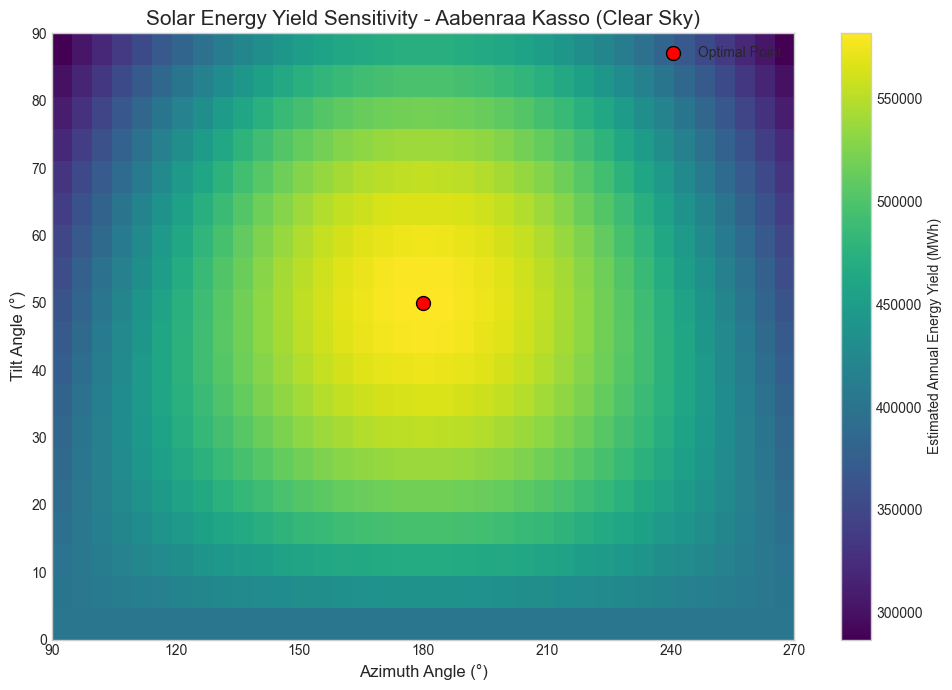


Solar sensitivity analysis chunk complete.


In [10]:
# %% Chunk 9: Solar Sensitivity Analysis (Tilt and Azimuth)

# Import necessary libraries if not already imported
import pvlib
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
from pvlib.modelchain import ModelChain
from pvlib.location import Location
from pvlib.pvsystem import PVSystem
from pvlib.temperature import TEMPERATURE_MODEL_PARAMETERS
# from pvlib.irradiance import get_total_irradiance # Not directly used here but good practice

print("\nStarting Solar Sensitivity Analysis (Tilt/Azimuth)...")

# --- Constants from the original code (only solar relevant ones) ---
# Using parameters defined in Chunk 1 for consistency
# Ensure these variables are available from Chunk 1 execution
# SOLAR_TOTAL_MODULES_TARGET, SOLAR_TARGET_DC_AC_RATIO, SOLAR_LATITUDE,
# SOLAR_LONGITUDE, SOLAR_ALTITUDE, SOLAR_TIMEZONE, SOLAR_LOCATION_NAME,
# SOLAR_MODULE_MODEL_NAME, SOLAR_INVERTER_MODEL_NAME, SOLAR_TEMP_MODEL_PARAMS_TYPE,
# SOLAR_SIMULATION_START, SOLAR_SIMULATION_END

# Define simulation frequency for sensitivity analysis (can be hourly for faster runs)
# Note: Using hourly ('1h') here for speed, original simulation might use '1min'.
# Results will differ based on frequency. Use SOLAR_SIMULATION_FREQ from Chunk 1
# if minute-level sensitivity is desired (will be much slower).
SENSITIVITY_SIM_FREQ = "1h" # Use '1h' for faster sensitivity analysis

# --- PV System Setup (Re-calculating based on Chunk 1 parameters) ---
print("Setting up PV system for sensitivity analysis...")
# Define Location object
location = Location(latitude=SOLAR_LATITUDE, longitude=SOLAR_LONGITUDE,
                    tz=SOLAR_TIMEZONE, altitude=SOLAR_ALTITUDE, name=SOLAR_LOCATION_NAME)

# Retrieve component parameters
sandia_modules = pvlib.pvsystem.retrieve_sam('SandiaMod')
cec_inverters = pvlib.pvsystem.retrieve_sam('CECInverter')
module = sandia_modules[SOLAR_MODULE_MODEL_NAME]
inverter = cec_inverters[SOLAR_INVERTER_MODEL_NAME]
temperature_parameters = TEMPERATURE_MODEL_PARAMETERS['sapm'][SOLAR_TEMP_MODEL_PARAMS_TYPE]

# Get inverter AC limit
INVERTER_AC_LIMIT_W = inverter.Paco
INVERTER_AC_LIMIT_MW = INVERTER_AC_LIMIT_W / 1e6

# Calculate system configuration (strings per inverter, number of inverters, etc.)
# This part is independent of tilt and azimuth, so it can be done once.
# Using the same logic as in Chunk 2.
nominal_dc_power_per_module_w = module.Vmpo * module.Impo
if nominal_dc_power_per_module_w <= 0 or pd.isna(nominal_dc_power_per_module_w):
     raise ValueError("Nominal DC power per module invalid.")
max_mods_vdcmax = np.floor(inverter.Vdcmax / module.Voco) if module.Voco > 0 else np.inf
max_mods_mppt_high = np.floor(inverter.Mppt_high / module.Vmpo) if module.Vmpo > 0 else np.inf
min_mods_mppt_low = np.ceil(inverter.Mppt_low / module.Vmpo) if module.Vmpo > 0 else 0
modules_per_string = int(min(max_mods_vdcmax, max_mods_mppt_high))
if modules_per_string < min_mods_mppt_low: modules_per_string = int(min_mods_mppt_low)
if modules_per_string <= 0: modules_per_string = 1
target_dc_power_per_inverter_mw = INVERTER_AC_LIMIT_MW * SOLAR_TARGET_DC_AC_RATIO
modules_per_inverter_target = (target_dc_power_per_inverter_mw * 1e6) / nominal_dc_power_per_module_w if nominal_dc_power_per_module_w > 0 else np.inf
strings_per_inverter = int(np.ceil(modules_per_inverter_target / modules_per_string)) if modules_per_string > 0 else 1
if strings_per_inverter <= 0: strings_per_inverter = 1
modules_per_inverter_actual = modules_per_string * strings_per_inverter
if modules_per_inverter_actual <= 0: raise ValueError("Modules per inverter invalid.")
# Use the target number of modules from Chunk 1 if available, otherwise recalculate based on a target capacity
if 'SOLAR_TOTAL_MODULES_TARGET' in locals():
     target_modules = SOLAR_TOTAL_MODULES_TARGET
elif 'SOLAR_FARM_TARGET_DC_CAPACITY_MW' in locals(): # Check if SOLAR_FARM_TARGET_DC_CAPACITY_MW is defined
     target_modules = (SOLAR_FARM_TARGET_DC_CAPACITY_MW * 1e6) / nominal_dc_power_per_module_w
else:
     # Fallback if neither global variable is defined (should be from Chunk 1)
     print("Warning: SOLAR_TOTAL_MODULES_TARGET or SOLAR_FARM_TARGET_DC_CAPACITY_MW not found. Using a default target of 100000 modules.")
     target_modules = 1069776 # Default target if not defined, adjust as necessary

num_inverters = int(np.ceil(target_modules / modules_per_inverter_actual)) if modules_per_inverter_actual > 0 else 1
if num_inverters <= 0: num_inverters = 1
total_modules_actual = num_inverters * modules_per_inverter_actual
total_nominal_dc_power_mw = (total_modules_actual * nominal_dc_power_per_module_w) / 1e6
total_nominal_ac_power_mw = num_inverters * INVERTER_AC_LIMIT_MW

print(f"System configuration for sensitivity analysis:")
print(f"  Modules per string: {modules_per_string}")
print(f"  Strings per inverter: {strings_per_inverter}")
print(f"  Number of inverters: {num_inverters}")
print(f"  Total nominal AC capacity: {total_nominal_ac_power_mw:.2f} MW")

# --- Time Series and Clear Sky Data (independent of tilt/azimuth) ---
print(f"Generating time series and clear sky data ({SENSITIVITY_SIM_FREQ} frequency)...")
# Adjust end date for date_range inclusive='left'
sensitivity_sim_end_adj = (pd.to_datetime(SOLAR_SIMULATION_END) + pd.Timedelta(days=1)).strftime('%Y-%m-%d')
times = pd.date_range(start=SOLAR_SIMULATION_START, end=sensitivity_sim_end_adj, freq=SENSITIVITY_SIM_FREQ,
                      tz=location.tz, inclusive='left')

# Get clear sky data for the defined times
clear_sky = location.get_clearsky(times)

# Add required weather parameters if missing (using defaults for clear-sky analysis)
if 'temp_air' not in clear_sky:
    clear_sky['temp_air'] = 20.0 # Dummy air temp in Celsius
if 'wind_speed' not in clear_sky:
    clear_sky['wind_speed'] = 1.0 # Dummy wind speed in m/s

# Ensure the clear_sky data is valid for simulation
if clear_sky.empty or clear_sky[['ghi', 'dni', 'dhi']].isnull().values.any():
    print("Error: Could not retrieve valid clear sky data. Cannot perform sensitivity analysis.")
    # Exit or handle error appropriately
    # exit() # Or raise an error
    results_df_sensitivity = pd.DataFrame() # Create empty df to avoid errors later
else:
    print("Clear sky data generated.")

    # --- Sensitivity Analysis Setup ---
    # Define the ranges for tilt and azimuth angles
    # Tilt from 0 to 90 degrees in steps of 5
    tilt_angles_range = np.arange(0, 91, 5) # Include 90 degrees
    # Azimuth from 90 (East) to 270 (West) degrees in steps of 5 (focus on southerly orientations)
    # Or use 0-360 for a full sweep: np.arange(0, 361, 5)
    azimuth_angles_range = np.arange(90, 271, 5) # Focus on East-South-West

    print(f"Tilt range: {tilt_angles_range.min()}° to {tilt_angles_range.max()}° (step {np.diff(tilt_angles_range)[0]}°)")
    print(f"Azimuth range: {azimuth_angles_range.min()}° to {azimuth_angles_range.max()}° (step {np.diff(azimuth_angles_range)[0]}°)")

    # List to store results dictionaries
    results_sensitivity = []

    # --- Perform Sensitivity Analysis ---
    print("\nStarting sensitivity simulation loop...")
    total_combinations = len(tilt_angles_range) * len(azimuth_angles_range)
    current_combination = 0

    for tilt in tilt_angles_range:
        for azimuth in azimuth_angles_range:
            current_combination += 1
            if current_combination % 50 == 0: # Print progress update every 50 combinations
                 print(f"  Simulating combination {current_combination}/{total_combinations} (Tilt: {tilt}°, Azimuth: {azimuth}°)")

            # Update the PVSystem with the current tilt and azimuth
            # Create a new system object for each combination
            system_single_inverter = PVSystem(surface_tilt=tilt, surface_azimuth=azimuth,
                                              module_parameters=module,
                                              inverter_parameters=inverter,
                                              temperature_model_parameters=temperature_parameters,
                                              modules_per_string=modules_per_string,
                                              strings_per_inverter=strings_per_inverter)

            # Create a new ModelChain for the updated system
            modelchain = ModelChain(system_single_inverter, location, name=f'Tilt{tilt}_Az{azimuth}')

            # Run the model with clear sky data
            # Use a try-except block in case of simulation errors for specific angles
            try:
                modelchain.run_model(clear_sky) # Pass the pre-calculated clear sky data

                # Calculate total AC power and energy yield
                # Clip AC power at inverter limit and handle potential NaNs
                ac_power_single_clipped_w = modelchain.results.ac.clip(lower=0, upper=INVERTER_AC_LIMIT_W).fillna(0)
                # Scale to the total number of inverters and convert to MW
                total_ac_power_mw_sim = (ac_power_single_clipped_w * num_inverters) / 1e6

                # Calculate total energy yield in MWh for the year
                # Summing hourly power (MW) gives MWh directly for hourly frequency
                if SENSITIVITY_SIM_FREQ == '1h':
                     total_energy_mwh = total_ac_power_mw_sim.sum()
                else:
                     # If using finer frequency, need to account for time step duration
                     time_step_hours = pd.Timedelta(SENSITIVITY_SIM_FREQ).total_seconds() / 3600
                     total_energy_mwh = total_ac_power_mw_sim.sum() * time_step_hours

                # Store the results
                results_sensitivity.append({'tilt': tilt, 'azimuth': azimuth, 'energy_mwh': total_energy_mwh})

            except Exception as e:
                print(f"Error during simulation for Tilt: {tilt}°, Azimuth: {azimuth}°: {e}")
                # Store NaN or 0 energy yield for failed simulations
                results_sensitivity.append({'tilt': tilt, 'azimuth': azimuth, 'energy_mwh': np.nan})

    print("Sensitivity simulation loop finished.")

    # Convert results to a pandas DataFrame
    results_df_sensitivity = pd.DataFrame(results_sensitivity)

    # Drop rows where energy calculation failed
    results_df_sensitivity.dropna(subset=['energy_mwh'], inplace=True)

# --- Analyze and Plot Sensitivity Results ---
if not results_df_sensitivity.empty:
    # Find the combination with the highest energy yield
    best_result = results_df_sensitivity.loc[results_df_sensitivity['energy_mwh'].idxmax()]

    print("\n--- Sensitivity Analysis Results ---")
    print(f"Location: {location.name}")
    print(f"Simulation Period: {SOLAR_SIMULATION_START} to {SOLAR_SIMULATION_END}")
    print(f"Weather Data Used: Clear Sky Model ({SENSITIVITY_SIM_FREQ} frequency)")
    print("\nOptimal Orientation Found:")
    # ***** THE FOLLOWING LINES PRINT THE BEST TILT AND AZIMUTH *****
    print(f"  Best Tilt Angle: {best_result['tilt']:.0f}°")
    print(f"  Best Azimuth Angle: {best_result['azimuth']:.0f}°")
    # ***************************************************************
    print(f"  Highest Estimated Annual Energy Yield: {best_result['energy_mwh']:,.2f} MWh")

    # --- Plotting the results (Heatmap) ---
    print("\nGenerating sensitivity heatmap...")
    try:
        # Reshape the results into a 2D grid for plotting
        pivot_table = results_df_sensitivity.pivot(index='tilt', columns='azimuth', values='energy_mwh')

        plt.figure(figsize=(10, 7)) # Adjusted size
        # Use 'viridis', 'plasma', 'YlGnBu' or similar colormaps
        plt.imshow(pivot_table, aspect='auto', cmap='viridis', origin='lower',
                   extent=[pivot_table.columns.min(), pivot_table.columns.max(),
                           pivot_table.index.min(), pivot_table.index.max()])

        plt.colorbar(label='Estimated Annual Energy Yield (MWh)')
        plt.title(f'Solar Energy Yield Sensitivity - {location.name} (Clear Sky)', fontsize=15)
        plt.xlabel('Azimuth Angle (°)', fontsize=12)
        plt.ylabel('Tilt Angle (°)', fontsize=12)

        # Set ticks explicitly based on the ranges used
        plt.xticks(np.arange(90, 271, 30), fontsize=10) # Show ticks every 30 degrees for azimuth
        plt.yticks(tilt_angles_range[::2], fontsize=10) # Show ticks every 10 degrees for tilt

        # Highlight the optimal point
        plt.scatter(best_result['azimuth'], best_result['tilt'], color='red', s=100, edgecolors='black', label='Optimal Point', zorder=5)
        plt.legend(fontsize=10)

        plt.grid(False) # Turn off grid for imshow
        plt.tight_layout()
        # plt.savefig(f'solar_sensitivity_{location.name}.png', dpi=300) # Optional save
        plt.show()

    except Exception as e:
        print(f"Error generating heatmap: {e}")

else:
    print("\nNo valid sensitivity simulation results were obtained. Cannot plot heatmap.")

print("\nSolar sensitivity analysis chunk complete.")


Running Monte Carlo Simulation...
Mean LCOM: 1825.07 EUR/t
5th Percentile: 1795.11 EUR/t
50th Percentile (Median): 1824.91 EUR/t
95th Percentile: 1855.10 EUR/t


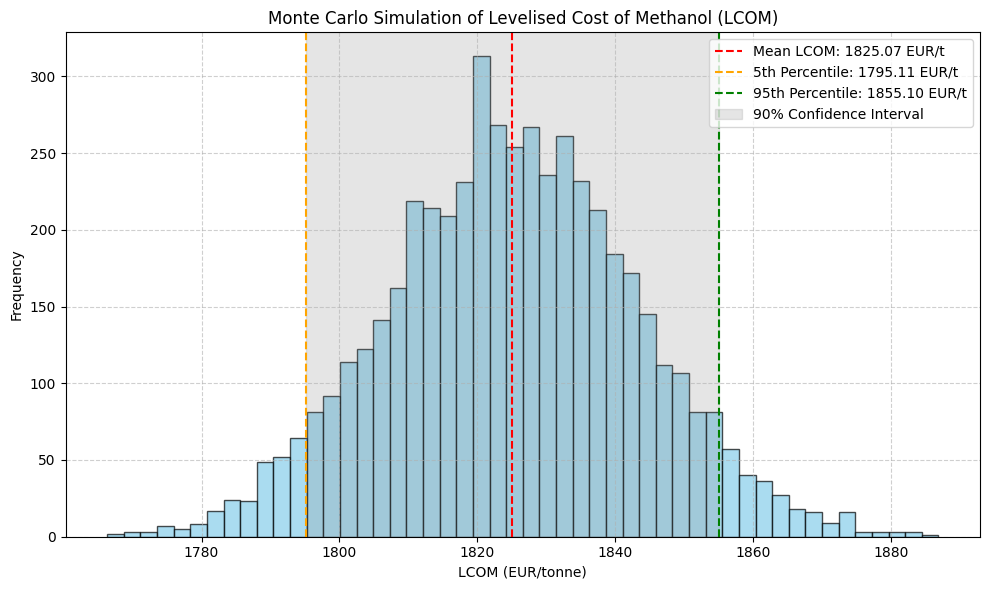


Running Tornado Sensitivity Analysis...
Base LCOM for Sensitivity Analysis: 1968.97 EUR/t


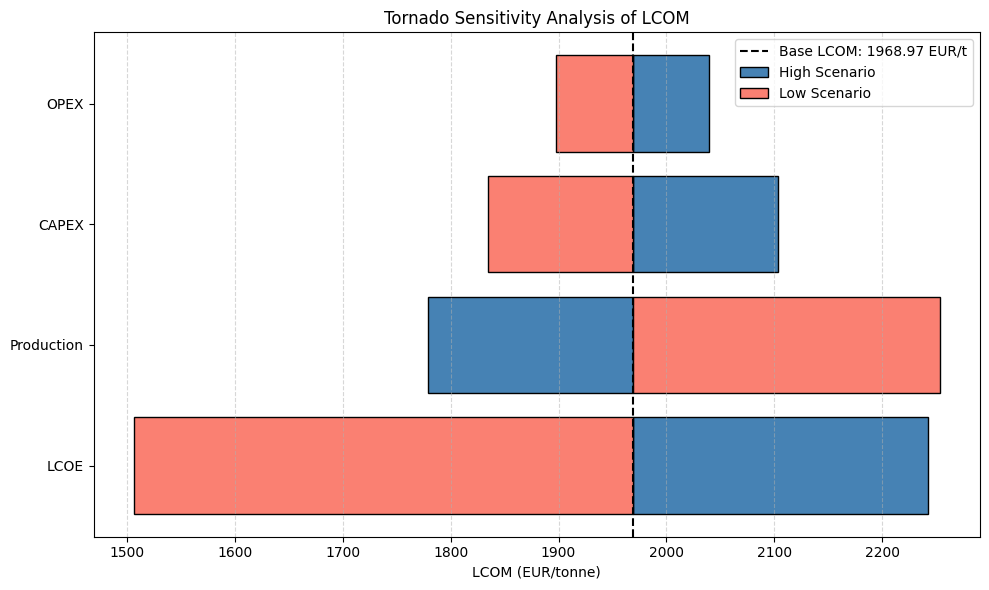

In [4]:
import numpy as np
import matplotlib.pyplot as plt

# ==============================================================================
# Script 1: Monte Carlo Simulation of Levelised Cost of Methanol (LCOM)
# ==============================================================================

print("Running Monte Carlo Simulation...")

# --- Constants and assumptions ---
years = 30
r = 0.05  # Discount rate
beta = 0.003  # Annual degradation in MeOH production
initial_production_tonnes = 44439  # tonnes/year

# --- Financials ---
CAPEX = 444210537.76  # EUR
OPEX_fixed = 15254147.04  # EUR/year

# --- Electricity data ---
total_renewable_generation = 792230.58  # MWh/year
export_energy = 183638  # MWh/year (excess)
import_energy = 140813  # MWh/year (deficit)
LCOE_base = 45.12  # EUR/MWh

# --- Market prices ---
export_price_day = 31.12 * 0.85  # EUR/MWh
export_price_night = 109.39 * 0.85  # EUR/MWh
day_import_price = 31.12  # EUR/MWh
night_import_price = 109.39  # EUR/MWh

# --- Monte Carlo settings ---
simulations = 5000
np.random.seed(42)  # for reproducibility

# --- Price assumptions ---
# Assuming 80% of export happens during the day, 20% at night
# Assuming 30% of import happens during the day, 70% at night
day_export_share = 0.8
night_export_share = 0.2
day_import_share = 0.3
night_import_share = 0.7

# Combine prices into base values for variation
export_price_base = export_price_day * day_export_share + export_price_night * night_export_share
import_price_base = day_import_price * day_import_share + night_import_price * night_import_share

# --- Simulation Loop ---
LCOMs = []
for _ in range(simulations):
    # Vary LCOE: 20% decrease with a standard deviation of 2%
    LCOE_adj = LCOE_base * (1 - np.random.normal(0.2, 0.02))

    # Vary prices: 20% increase with a standard deviation of 2%
    export_price = export_price_base * (1 + np.random.normal(0.2, 0.02))
    import_price = import_price_base * (1 + np.random.normal(0.2, 0.02))

    # Calculate the effective annual cost of energy
    effective_energy_cost = (
        total_renewable_generation * LCOE_adj +
        import_energy * import_price -
        export_energy * export_price
    )

    # --- Discounted Cash Flow Analysis ---
    discounted_costs = []
    discounted_production = []
    for t in range(1, years + 1):
        discount_factor = 1 / (1 + r) ** t
        # Calculate production for the year, accounting for degradation
        production_t = initial_production_tonnes * np.exp(-beta * (t - 1))
        
        # Calculate and append discounted costs and production
        current_year_costs = (OPEX_fixed + effective_energy_cost) * discount_factor
        discounted_costs.append(current_year_costs)
        discounted_production.append(production_t * discount_factor)

    # Calculate total discounted costs and production over the project lifetime
    total_discounted_costs = CAPEX + sum(discounted_costs)
    total_discounted_production = sum(discounted_production)

    # Calculate and store the LCOM for this simulation run
    LCOM = total_discounted_costs / total_discounted_production
    LCOMs.append(LCOM)

# --- Calculate statistics from simulation results ---
mean_lcom = np.mean(LCOMs)
p5, p50, p95 = np.percentile(LCOMs, [5, 50, 95])

print(f"Mean LCOM: {mean_lcom:.2f} EUR/t")
print(f"5th Percentile: {p5:.2f} EUR/t")
print(f"50th Percentile (Median): {p50:.2f} EUR/t")
print(f"95th Percentile: {p95:.2f} EUR/t")


# --- Plotting the results of the Monte Carlo Simulation ---
plt.figure(figsize=(10, 6))
plt.hist(LCOMs, bins=50, color='skyblue', edgecolor='black', alpha=0.7)
plt.title("Monte Carlo Simulation of Levelised Cost of Methanol (LCOM)")
plt.xlabel("LCOM (EUR/tonne)")
plt.ylabel("Frequency")
plt.grid(True, linestyle='--', alpha=0.6)

# Add vertical lines for statistical markers
plt.axvline(mean_lcom, color='red', linestyle='dashed', linewidth=1.5, label=f"Mean LCOM: {mean_lcom:.2f} EUR/t")
plt.axvline(p5, color='orange', linestyle='dashed', linewidth=1.5, label=f"5th Percentile: {p5:.2f} EUR/t")
plt.axvline(p95, color='green', linestyle='dashed', linewidth=1.5, label=f"95th Percentile: {p95:.2f} EUR/t")

# Shade the 95% confidence interval
plt.axvspan(p5, p95, color='gray', alpha=0.2, label='90% Confidence Interval') # p5 to p95 is a 90% interval

plt.legend()
plt.tight_layout()
plt.show()

# ==============================================================================
# Script 2: Tornado Sensitivity Analysis of LCOM
# ==============================================================================

print("\nRunning Tornado Sensitivity Analysis...")

# --- Base values (some are redefined for clarity in this standalone script) ---
# Note: These values should be consistent with the Monte Carlo script
def calculate_LCOM(CAPEX_val, OPEX_val, LCOE_val, production_val, energy_val):
    """Function to calculate LCOM with custom input values."""
    annual_energy_cost = (
        energy_val * LCOE_val +
        import_energy * import_price_base -  # Using base price for sensitivity
        export_energy * export_price_base
    )
    
    discounted_costs = []
    discounted_production = []
    for t in range(1, years + 1):
        discount = 1 / (1 + r) ** t
        prod_t = production_val * np.exp(-beta * (t - 1))
        discounted_costs.append((OPEX_val + annual_energy_cost) * discount)
        discounted_production.append(prod_t * discount)

    total_cost = CAPEX_val + sum(discounted_costs)
    total_prod = sum(discounted_production)
    return total_cost / total_prod

# --- Sensitivity parameters (e.g., +/- 20% variation) ---
parameters = {
    "LCOE": (20, 60), # A specific range for LCOE
    "Production": (initial_production_tonnes * 0.8, initial_production_tonnes * 1.2),
    "CAPEX": (CAPEX * 0.8, CAPEX * 1.2),
    "OPEX": (OPEX_fixed * 0.8, OPEX_fixed * 1.2),
}

# Adjust electricity usage proportionally with production changes
energy_low = total_renewable_generation * 0.8
energy_high = total_renewable_generation * 1.2

# Calculate base LCOM for the sensitivity analysis
base_LCOM = calculate_LCOM(CAPEX, OPEX_fixed, LCOE_base, initial_production_tonnes, total_renewable_generation)
print(f"Base LCOM for Sensitivity Analysis: {base_LCOM:.2f} EUR/t")

# --- Calculate sensitivity results for each parameter ---
results = {}
for param, (low, high) in parameters.items():
    if param == "CAPEX":
        lcom_low = calculate_LCOM(low, OPEX_fixed, LCOE_base, initial_production_tonnes, total_renewable_generation)
        lcom_high = calculate_LCOM(high, OPEX_fixed, LCOE_base, initial_production_tonnes, total_renewable_generation)
    elif param == "OPEX":
        lcom_low = calculate_LCOM(CAPEX, low, LCOE_base, initial_production_tonnes, total_renewable_generation)
        lcom_high = calculate_LCOM(CAPEX, high, LCOE_base, initial_production_tonnes, total_renewable_generation)
    elif param == "LCOE":
        lcom_low = calculate_LCOM(CAPEX, OPEX_fixed, low, initial_production_tonnes, total_renewable_generation)
        lcom_high = calculate_LCOM(CAPEX, OPEX_fixed, high, initial_production_tonnes, total_renewable_generation)
    elif param == "Production":
        # When production changes, associated energy generation also changes
        lcom_low = calculate_LCOM(CAPEX, OPEX_fixed, LCOE_base, low, energy_low)
        lcom_high = calculate_LCOM(CAPEX, OPEX_fixed, LCOE_base, high, energy_high)
    results[param] = (lcom_low, lcom_high)

# --- Prepare and sort data for plotting ---
labels = []
low_impacts = []
high_impacts = []
for key, (low_val, high_val) in results.items():
    labels.append(key)
    low_impacts.append(low_val - base_LCOM)
    high_impacts.append(high_val - base_LCOM)

# Sort by total impact range (|high - low|)
ranges = [abs(high - low) for (low, high) in results.values()]
sorted_indices = np.argsort(ranges)

# Apply the sorted order
labels_sorted = [labels[i] for i in sorted_indices]
low_impacts_sorted = [low_impacts[i] for i in sorted_indices]
high_impacts_sorted = [high_impacts[i] for i in sorted_indices]

# --- Plotting the Tornado Chart ---
y_pos = np.arange(len(labels_sorted))
fig, ax = plt.subplots(figsize=(10, 6))

# Plot the bars for high and low scenarios
ax.barh(y_pos, high_impacts_sorted, left=base_LCOM, color='steelblue', edgecolor='black', label='High Scenario')
ax.barh(y_pos, low_impacts_sorted, left=base_LCOM, color='salmon', edgecolor='black', label='Low Scenario')

# Set plot details
ax.set_yticks(y_pos)
ax.set_yticklabels(labels_sorted)
ax.invert_yaxis()  # To display the most sensitive parameter at the top
ax.axvline(base_LCOM, color='black', linestyle='--', label=f'Base LCOM: {base_LCOM:.2f} EUR/t')
ax.set_xlabel("LCOM (EUR/tonne)")
ax.set_title("Tornado Sensitivity Analysis of LCOM")
ax.legend()
plt.grid(True, axis='x', linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()


